# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |
| Apêndice | A | Painel-resumo do estudo; catálogo de todas as figuras e tabelas (numeradas por parte: Figura II.3, Tabela III.5) e exportação para `fig/`, `tab/` e `tab/ed2_tabelas.xlsx` |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.4);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos; **`CORES_DESFECHO`** usa matizes que não repetem os dos grupos (a camada de visualização completa, com estilo, rótulos e funções de figura e tabela, está na seção 1.2);
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
# Desfechos são outra entidade: nenhuma cor de desfecho repete a cor de um grupo (validação na seção 1.2)
CORES_DESFECHO = {'Homologação': '#CC79A7', 'Mérito': '#4B3F8F', 'Sem mérito': '#B8461B',
                  'Redistribuição': '#7F7F7F', 'Ativo': '#C8C8C8'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    try:
        if valor is None or pd.isna(valor):
            return '–'
    except (TypeError, ValueError):
        pass
    return f'{float(valor):,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Camada de visualização

Todas as figuras e tabelas do notebook passam por uma **camada comum**, definida aqui uma única vez. O objetivo é que qualquer gráfico possa ser lido sem consultar o código: cada figura e cada tabela tem **número** (por parte: Figura II.3, Tabela III.5), **título** que enuncia o achado ou a pergunta, **eixos com unidade**, **n** de cada grupo, a **fonte** e, quando há teste, o **resultado do teste no próprio gráfico** (estatística, valor-p e tamanho de efeito). Tudo é numerado e registrado num catálogo, reproduzido no Apêndice, e exportado: figuras em `fig/<id>.png` (e `.svg`), tabelas em `tab/<id>.csv` (separador `;`, vírgula decimal, UTF-8 com BOM, que o Excel abre corretamente).

| Elemento | Regra adotada |
|---|---|
| Cor | identifica uma **entidade**, e só uma: os três grupos têm as cores fixas de Okabe-Ito; os desfechos usam outros matizes (nenhum repete a cor de um grupo); "ativo/censurado" é cinza claro. Mapas de calor usam uma escala **sequencial** de um só matiz (magnitude, como o V de Cramér) ou **divergente** com dois matizes opostos e meio cinza (sinal, como os resíduos ajustados) |
| Daltonismo | as paletas são verificadas por simulação (Machado, Oliveira e Fernandes, 2009, protanopia e deuteranopia de severidade 1,0) e distância perceptual ΔE no espaço OKLab (×100): alvo ≥ 8 entre cores vizinhas, piso de 15 sem simulação. Além da cor, há sempre um segundo canal: legenda, rótulo direto ou posição |
| Forma | barras **verticais** e *boxplots*; nunca dois eixos verticais com escalas diferentes; nunca histograma em escala logarítmica; Kaplan-Meier sempre como S(t) descendente, com IC e número em risco |
| Rótulos | nomes legíveis (não os nomes das colunas), rótulos longos quebrados em linhas, ordem fixa dos grupos (Controle, Presencial, Remota) e dos desfechos; legenda sempre que há duas ou mais séries, e rótulos diretos seletivos (não um número em cada ponto) |
| Números | padrão brasileiro nos eixos, rótulos e tabelas: vírgula decimal, ponto de milhar, valor-p como "< 0,001" |

As funções disponíveis para as demais partes:

- **`figura(fig, id, titulo, secao=..., fonte=..., nota=...)`**: numera, põe título e fonte, converte os eixos para vírgula decimal, salva PNG e SVG e registra no catálogo;
- **`tabela(df, id, titulo, secao=..., nota=..., formatos=..., destaque=...)`**: exibe a tabela formatada (legenda numerada, pt-BR, valor-p formatado, índice oculto quando não tem significado, linhas significativas destacadas), exporta CSV e registra no catálogo;
- **auxiliares de gráfico**: `barras_verticais`, `barras_agrupadas`, `barras_empilhadas`, `boxplot_grupos`, `plot_km`, `anotar_n`, `anotar_teste`, `texto_teste`, `quebra`, `eixo_pct`, `eixo_meses`, `legenda_abaixo`;
- **rótulos**: `ROTULOS` (variável → rótulo com unidade), `ROTULO_DESFECHO`, `rotulo_grupo(g, com_n=True)` → "Controle (n = 313)".

In [3]:
import textwrap
from matplotlib.offsetbox import AnchoredText
from matplotlib.ticker import ScalarFormatter, FuncFormatter
from IPython.display import HTML

TAB = RAIZ / 'tab'
TAB.mkdir(parents=True, exist_ok=True)
FONTE_PADRAO = ('Fonte: elaboração própria a partir da planilha de controle dos processos do 4º JEC de Natal/RN '
                '(atualização de 07/10/2026).')

# ---------------------------------------------------------------- rótulos legíveis (com unidade)
ROTULOS = {
    'tempo': 'Tempo até a sentença ou a censura (dias)',
    'tempo_sentenca': 'Tempo até a sentença (dias)',
    'tempo_pos': 'Tempo até a sentença ou a censura (dias; zeros = 0,5)',
    'followup': 'Seguimento máximo possível (dias)',
    'dias': 'Dias desde a distribuição',
    'S': 'Proporção ainda sem sentença, S(t)',
    'F': 'Proporção acumulada de sentenças',
    'CIF': 'Incidência acumulada',
    'grupo': 'Grupo (rito sorteado)',
    'tipo_desfecho': 'Tipo de desfecho',
    'mes_distribuicao': 'Mês de distribuição (2026)',
    'dt_distribuicao': 'Data de distribuição (2026)',
    'dt_sentenca': 'Data da sentença (2026)',
    'ordem_chegada': 'Ordem de chegada (1 a 938)',
    'dia_estudo': 'Dia do estudo (desde 01/01/2026)',
    'n': 'Número de processos',
    'pct': 'Processos (%)',
    'acordo': 'Acordo (na AC ou fora dela)',
    'acordo_ac': 'Acordo na audiência de conciliação',
    'acordo_fora': 'Acordo fora da audiência',
    'ac_realizada': 'Audiência de conciliação realizada',
    'tecnica': 'Técnica de conciliação',
    'hibrida': 'Audiência híbrida',
    'origem_externa': 'Processo de outro órgão ou ano anterior',
}
ROTULO_DESFECHO = {'Homologação': 'Homologação de acordo', 'Mérito': 'Sentença de mérito',
                   'Sem mérito': 'Extinção sem mérito', 'Redistribuição': 'Redistribuição (Decisão)',
                   'Ativo': 'Em tramitação (censurado)'}
ORDEM_STATUS = ['Sentença', 'Redistribuição', 'Ativo (censurado)']
CORES_STATUS = {'Sentença': '#3D3D3D', 'Redistribuição': CORES_DESFECHO['Redistribuição'],
                'Ativo (censurado)': CORES_DESFECHO['Ativo']}
CINZA = '#A6A6A6'                       # séries de contexto (ênfase = 1 cor + cinza)
DESTAQUE = '#D55E00'                    # referência/limiar externo (linha de referência, valor divulgado)
MESES_PT = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']


def rotulo_grupo(g, com_n=False, longo=False, base=None, quebrar=False):
    """'Controle' | 'Controle (n = 313)' | rótulo longo; `base` = DataFrame de onde contar n (padrão: dados)."""
    nome = ROTULO_GRUPO.get(g, str(g)) if longo else str(g)
    if com_n:
        base = base if base is not None else globals().get('dados')
        n = int((base['grupo'] == g).sum()) if base is not None else None
        if n is not None:
            nome = f'{nome}\n(n = {fmt_br(n, 0)})' if quebrar else f'{nome} (n = {fmt_br(n, 0)})'
    return nome


def quebra(texto, largura=16):
    """Quebra rótulos longos em linhas ('Extinção do Feito com Homologação do Acordo' → 3 linhas)."""
    return '\n'.join(textwrap.fill(parte, largura, break_long_words=False) for parte in str(texto).split('\n'))


def fmt_p(p, casas=3):
    """Valor-p em pt-BR: '< 0,001' ou '0,034'; ausente → '–'."""
    try:
        if p is None or pd.isna(p):
            return '–'
    except (TypeError, ValueError):
        return str(p)
    limite = 10 ** -casas
    return f'< {fmt_br(limite, casas)}' if p < limite else fmt_br(p, casas)


def fmt_int(x):
    return fmt_br(x, 0)


# ---------------------------------------------------------------- paletas sequencial e divergente
SEQ = mpl.colors.LinearSegmentedColormap.from_list('ed2_seq', ['#F4F6F8', '#A9B8C6', '#5B7389', '#2B3A4A'])
DIV = mpl.colors.LinearSegmentedColormap.from_list('ed2_div', ['#2166AC', '#92C5DE', '#F2F2F2', '#F4A582', '#B2182B'])
for _mapa in (SEQ, DIV):
    _mapa.set_bad('#FFFFFF')

# ---------------------------------------------------------------- estilo matplotlib
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 8, 'axes.labelsize': 10, 'axes.labelcolor': TINTA,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'legend.fontsize': 9, 'legend.title_fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8c8c8c', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.7, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'axes.formatter.limits': (-5, 6), 'axes.formatter.use_mathtext': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
    'boxplot.medianprops.color': TINTA, 'image.cmap': 'ed2_seq' if 'ed2_seq' in mpl.colormaps else 'viridis',
})
if 'ed2_seq' not in mpl.colormaps:
    mpl.colormaps.register(SEQ); mpl.colormaps.register(DIV)
plt.rcParams['image.cmap'] = 'ed2_seq'
sns.set_palette(list(CORES_GRUPO.values()))


class FormatadorBR(ScalarFormatter):
    """Rótulos de eixo com vírgula decimal e ponto de milhar (0,25 · 1.200)."""
    def __call__(self, x, pos=None):
        s = super().__call__(x, pos)
        try:
            v = float(s.replace('−', '-'))
        except ValueError:
            return s.replace('.', ',')
        if abs(v) >= 1000 and float(v).is_integer():
            return fmt_br(v, 0).replace('-', '−')
        return s.replace('.', ',')


def aplicar_br(fig):
    """Troca o formatador padrão de todos os eixos numéricos da figura pelo formatador pt-BR."""
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if type(eixo.get_major_formatter()) is ScalarFormatter:
                eixo.set_major_formatter(FormatadorBR())


def eixo_pct(ax, eixo='y', casas=0, escala=100):
    """Eixo em percentual pt-BR. `escala=100` quando os dados estão em proporção (0–1)."""
    f = FuncFormatter(lambda v, _: fmt_br(v * escala, casas) + '%')
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)


def eixo_meses(ax, eixo='x', formato='mes'):
    """Eixo de datas com meses em português ('jan', 'fev', …) ou dia/mês ('15/03')."""
    alvo = ax.xaxis if eixo == 'x' else ax.yaxis
    if formato == 'mes':
        alvo.set_major_locator(mpl.dates.MonthLocator())
        alvo.set_major_formatter(FuncFormatter(lambda v, _: MESES_PT[mpl.dates.num2date(v).month - 1]))
    else:
        alvo.set_major_formatter(mpl.dates.DateFormatter('%d/%m'))


def legenda_abaixo(ax, ncol=3, dy=-0.16, **kw):
    """Legenda centralizada abaixo do eixo (não disputa espaço com os dados)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, dy), ncol=ncol, **kw)


# ---------------------------------------------------------------- catálogo, figuras e tabelas
CATALOGO = {}          # (tipo, id) -> registro
TABELAS_EXPORT = {}    # id -> DataFrame exportado (para a pasta de trabalho do Apêndice)
_CONTADOR = {}
PARTE_ATUAL = 'I'
_ROMANO = {1: 'I', 2: 'II', 3: 'III', 4: 'IV', 5: 'V', 6: 'VI', 7: 'VII', 8: 'VIII', 99: 'A'}


def _parte_de(secao):
    if secao is None:
        return PARTE_ATUAL
    try:
        return _ROMANO.get(int(str(secao).split('.')[0]), str(secao).split('.')[0])
    except ValueError:
        return str(secao)


def _registra(tipo, id_, titulo, secao, arquivo):
    chave = (tipo, id_)
    parte = _parte_de(secao)
    if chave in CATALOGO:
        numero = CATALOGO[chave]['Número']
    else:
        _CONTADOR[(tipo, parte)] = _CONTADOR.get((tipo, parte), 0) + 1
        numero = f'{parte}.{_CONTADOR[(tipo, parte)]}'
    CATALOGO[chave] = {'Tipo': tipo, 'Número': numero, 'id': id_, 'Título': titulo,
                       'Seção': '' if secao is None else str(secao), 'Arquivo': arquivo}
    return numero


def ref(id_, tipo='Figura'):
    """'Figura II.3' a partir do id (para textos gerados em código)."""
    reg = CATALOGO.get((tipo, id_))
    return f'{tipo} {reg["Número"]}' if reg else f'{tipo} ?'


def _quebrar_largura(texto, largura_pol, tamanho):
    n = max(40, int(largura_pol * 72 / (tamanho * 0.53)))
    return '\n'.join(textwrap.fill(par, n, break_long_words=False) if par else '' for par in str(texto).split('\n'))


def figura(fig, id, titulo, secao=None, fonte=FONTE_PADRAO, nota=None, svg=True, mostrar=True):
    """Numera, titula, põe fonte/nota, aplica pt-BR aos eixos, salva fig/<id>.png (+ .svg) e cataloga.

    O título (`titulo`) deve enunciar o achado ou a pergunta; os títulos dos painéis (ax.set_title)
    dizem o que cada painel mostra. Não use plt.suptitle: esta função é dona do título da figura.
    """
    numero = _registra('Figura', id, titulo, secao, f'fig/{id}.png')
    aplicar_br(fig)
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_visible(False)
    if fig.get_layout_engine() is None:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UserWarning)
            fig.tight_layout()
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    W, H = fig.get_size_inches()
    x0 = caixa.x0 / W
    largura = caixa.width
    fig.text(x0, (caixa.y1 + 0.12) / H, _quebrar_largura(f'Figura {numero} — {titulo}', largura, 12),
             ha='left', va='bottom', fontsize=12, fontweight='bold', color=TINTA)
    rodape = fonte or ''
    if nota:
        rodape = f'{rodape}\nNota: {nota}' if rodape else f'Nota: {nota}'
    if rodape:
        fig.text(x0, (caixa.y0 - 0.10) / H, _quebrar_largura(rodape, largura, 8.5),
                 ha='left', va='top', fontsize=8.5, color=TINTA_2, linespacing=1.35)
    fig.savefig(FIG / f'{id}.png', bbox_inches='tight', pad_inches=0.15)
    if svg:
        fig.savefig(FIG / f'{id}.svg', bbox_inches='tight', pad_inches=0.15)
    if mostrar:
        display(fig)
    plt.close(fig)


def _e_coluna_p(nome):
    s = str(nome[-1] if isinstance(nome, tuple) else nome).strip().lower()
    return (s in {'p', 'valor-p', 'p-valor', 'valor p', 'p holm', 'p bh', 'p_holm'}
            or s.startswith(('p ', 'p(', 'p_', 'p-', 'valor-p', 'valor p')))


def _na(v):
    try:
        return v is None or bool(pd.isna(v))
    except (TypeError, ValueError):
        return False


def _formatador(serie, nome, formato, casas):
    if callable(formato):
        return lambda v: '–' if _na(v) else formato(v)
    if formato == 'p' or (formato is None and _e_coluna_p(nome)):
        return fmt_p
    if formato == 'pct':                      # proporção 0–1 → 12,3%
        return lambda v: '–' if _na(v) else pct_br(v, 1)
    if formato == '%':                        # já em percentual → 12,3%
        return lambda v: '–' if _na(v) else fmt_br(v, 1) + '%'
    if formato == 'int':
        return lambda v: '–' if _na(v) else fmt_br(v, 0)
    if formato == 'texto':
        return lambda v: '–' if _na(v) else str(v)
    if isinstance(formato, int) and not isinstance(formato, bool):
        return lambda v, c=formato: '–' if _na(v) else fmt_br(v, c)
    s = serie.dropna()
    if pd.api.types.is_bool_dtype(serie) or (len(s) and s.map(lambda v: isinstance(v, (bool, np.bool_))).all()):
        return lambda v: '–' if _na(v) else ('Sim' if bool(v) else 'Não')
    if pd.api.types.is_datetime64_any_dtype(serie):
        return lambda v: '–' if _na(v) else pd.Timestamp(v).strftime('%d/%m/%Y')
    if pd.api.types.is_numeric_dtype(serie):
        valores = pd.to_numeric(s, errors='coerce').astype(float)
        valores = valores[np.isfinite(valores)]
        if '%' in str(nome):
            return lambda v: '–' if _na(v) else fmt_br(v, 1)
        if len(valores) and np.allclose(valores, np.round(valores)):
            return lambda v: '–' if _na(v) else fmt_br(v, 0)
        return lambda v, c=casas: '–' if _na(v) else fmt_br(v, c)

    def _obj(v):
        if _na(v):
            return '–'
        if isinstance(v, (bool, np.bool_)):
            return 'Sim' if v else 'Não'
        if isinstance(v, (float, np.floating)):
            return fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, casas)
        if isinstance(v, (int, np.integer)):
            return fmt_br(v, 0)
        if isinstance(v, pd.Timestamp):
            return v.strftime('%d/%m/%Y')
        return str(v)
    return _obj


def _limpa_dtypes(df):
    """Nullable (Int64, Float64, boolean, string) → tipos simples, para formatação e exportação sem ruído."""
    saida = df.copy()
    for c in saida.columns:
        dt = saida[c].dtype
        if isinstance(dt, pd.CategoricalDtype):
            saida[c] = saida[c].astype(object)
        elif str(dt) in ('Int64', 'Int32', 'Float64', 'Float32', 'UInt8', 'Int8', 'Int16'):
            saida[c] = saida[c].astype('float64')
        elif str(dt) == 'boolean':
            saida[c] = saida[c].astype(object).where(saida[c].notna(), None)
        elif str(dt) in ('string', 'str'):
            saida[c] = saida[c].astype(object)
    return saida


def tabela(df, id, titulo, secao=None, nota=None, fonte=FONTE_PADRAO, formatos=None, destaque=None,
           casas=2, indice=None, alfa=0.05, gradiente=None, exportar=True, mostrar=True):
    """Exibe `df` como tabela numerada (Tabela II.4 — título), em pt-BR, exporta tab/<id>.csv e cataloga.

    formatos: {coluna: casas (int) | 'p' | 'pct' (proporção→%) | '%' (já em %) | 'int' | 'texto' | função}.
              Sem formato, colunas cujo nome começa com 'p' + separador ('p', 'p Holm', 'p (exato)') viram
              valor-p; inteiros ficam sem casas; demais números com `casas`.
    destaque: nome de uma coluna de valores-p (linhas com p < alfa em destaque), máscara booleana
              ou função df -> máscara.
    indice:   None = oculta se for um RangeIndex sem significado; True/False força.
    gradiente: {'mapa': SEQ | DIV, 'colunas': [...], 'vmin': .., 'vmax': ..} para mapas de calor em tabela.
    """
    if isinstance(df, pd.Series):
        df = df.to_frame()
    bruto = df.copy()
    numero = _registra('Tabela', id, titulo, secao, f'tab/{id}.csv')
    if indice is None:
        indice = not (isinstance(bruto.index, pd.RangeIndex) and bruto.index.name is None)
    if indice and not isinstance(bruto.index, pd.MultiIndex) and not isinstance(bruto.columns, pd.MultiIndex):
        # índice simples com significado vira a 1ª coluna (sem a linha extra do nome do índice)
        nome_ind = bruto.index.name if bruto.index.name is not None else ''
        bruto = bruto.reset_index(names=[nome_ind] if nome_ind not in bruto.columns else ['_' + str(nome_ind)])
        indice = False
    limpo = _limpa_dtypes(bruto)
    if isinstance(limpo.index, pd.CategoricalIndex):
        limpo.index = limpo.index.astype(object)
    formatos = formatos or {}
    fmt = {c: _formatador(limpo[c], c, formatos.get(c), casas) for c in limpo.columns}
    sty = limpo.style.format(fmt, na_rep='–', escape='html')
    sty = sty.format_index(lambda v: '–' if _na(v) else (fmt_br(v, 0) if isinstance(v, (int, np.integer)) and abs(v) >= 1000
                                                          else (pd.Timestamp(v).strftime('%d/%m/%Y') if isinstance(v, pd.Timestamp)
                                                                else str(v))), escape='html')
    sty = sty.set_caption(f'Tabela {numero} — {titulo}')
    sty = sty.set_table_styles([
        {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; '
                                         'color: #1a1a1a; padding: 4px 0 6px 0;'},
        {'selector': 'th', 'props': 'text-align: center; background-color: #f3f3f3; color: #1a1a1a; '
                                    'padding: 4px 8px; border-bottom: 1px solid #bbb;'},
        {'selector': 'th.row_heading', 'props': 'text-align: left; background-color: #fafafa;'},
        {'selector': 'td', 'props': 'text-align: right; padding: 3px 8px; font-variant-numeric: tabular-nums;'},
        {'selector': '', 'props': 'border-collapse: collapse; margin-bottom: 2px;'},
    ])
    texto = [c for c in limpo.columns if limpo[c].dtype == object
             and not limpo[c].dropna().map(lambda v: isinstance(v, (int, float, np.number, bool, np.bool_))).all()]
    if texto:
        sty = sty.set_properties(subset=texto, **{'text-align': 'left'})
    if gradiente:
        sty = sty.background_gradient(cmap=gradiente.get('mapa', SEQ), subset=gradiente.get('colunas'),
                                      vmin=gradiente.get('vmin'), vmax=gradiente.get('vmax'), axis=None)
    if destaque is not None:
        if isinstance(destaque, str):
            mascara = pd.to_numeric(bruto[destaque], errors='coerce').lt(alfa).to_numpy()
        elif callable(destaque):
            mascara = np.asarray(destaque(bruto), dtype=bool)
        else:
            mascara = np.asarray(destaque, dtype=bool)
        css = 'background-color: #EAF0F6; font-weight: 600;'
        sty = sty.apply(lambda d: pd.DataFrame(np.where(np.broadcast_to(mascara[:, None], d.shape), css, ''), index=d.index, columns=d.columns),
                        axis=None)
    if not indice:
        sty = sty.hide(axis='index')
    if mostrar:
        display(sty)
        rodape = []
        if nota:
            rodape.append(f'Nota: {nota}')
        if fonte:
            rodape.append(fonte)
        if rodape:
            display(HTML('<div style="font-size: 0.85em; color: #555; margin: 2px 0 14px 0; max-width: 60em;">'
                         + '<br>'.join(rodape) + '</div>'))
    if exportar:
        exp = limpo.copy()
        if isinstance(exp.columns, pd.MultiIndex):
            exp.columns = [' | '.join(str(x) for x in c if str(x) != '') for c in exp.columns]
        if indice:
            exp = exp.reset_index()
        exp.columns = [str(c) for c in exp.columns]
        exp.to_csv(TAB / f'{id}.csv', sep=';', decimal=',', encoding='utf-8-sig', index=False)
        TABELAS_EXPORT[id] = exp


# ---------------------------------------------------------------- auxiliares de gráfico
def anotar_n(ax, posicoes, ns, onde='topo', tamanho=8.5):
    """Escreve 'n = …' sobre cada posição do eixo x (topo ou base da área do gráfico)."""
    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    y, va = (0.985, 'top') if onde == 'topo' else (0.015, 'bottom')
    for x, n in zip(posicoes, ns):
        ax.text(x, y, f'n = {fmt_br(n, 0)}', transform=trans, ha='center', va=va, fontsize=tamanho, color=TINTA_2)


def texto_teste(teste, estatistica=None, p=None, efeito=None, extra=None):
    """Monta o texto padrão do resultado: 'Kruskal-Wallis\\nH = 3,21; p = 0,201\\nε² = 0,002 [0,000; 0,010]'."""
    linhas = [teste]
    meio = []
    if estatistica:
        meio.append(estatistica)
    if p is not None:
        meio.append(f'p {"< 0,001" if p < 0.001 else "= " + fmt_p(p)}')
    if meio:
        linhas.append('; '.join(meio))
    if efeito:
        linhas.append(efeito)
    if extra:
        linhas.append(extra)
    return '\n'.join(linhas)


def anotar_teste(ax, texto, loc='upper right', tamanho=8.5):
    """Caixa com o resultado do teste dentro do gráfico (estatística, p, efeito)."""
    caixa = AnchoredText(texto, loc=loc, prop=dict(size=tamanho, color=TINTA), frameon=True, pad=0.4, borderpad=0.6)
    caixa.patch.set_boxstyle('round,pad=0.3,rounding_size=0.2')
    caixa.patch.set_facecolor((1, 1, 1, 0.92))
    caixa.patch.set_edgecolor('#bdbdbd')
    caixa.patch.set_linewidth(0.8)
    ax.add_artist(caixa)
    return caixa


def _cor_texto(cor):
    r, g, b = mpl.colors.to_rgb(cor)
    return 'white' if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else TINTA


def barras_verticais(ax, categorias, valores, cores=None, rotular=True, fmt=None, erro=None, largura=0.6,
                     quebrar=14, ylabel=None, xlabel=None, ns=None, ymax=None):
    """Barras verticais com rótulo do valor no topo (rotular=True | 'max' | False) e IC opcional (erro=(lo, hi))."""
    categorias = list(categorias)
    valores = np.asarray(valores, dtype=float)
    x = np.arange(len(categorias))
    if cores is None:
        cores = [CORES_GRUPO.get(c, CORES_GRUPO['Controle']) if c in CORES_GRUPO else '#5B7389' for c in categorias]
    elif isinstance(cores, dict):
        cores = [cores.get(c, CINZA) for c in categorias]
    elif isinstance(cores, str):
        cores = [cores] * len(categorias)
    barras = ax.bar(x, valores, width=largura, color=cores, edgecolor='white', linewidth=1)
    topo = valores.copy()
    if erro is not None:
        lo, hi = (np.asarray(e, dtype=float) for e in erro)
        ax.errorbar(x, valores, yerr=[valores - lo, hi - valores], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
        topo = np.maximum(topo, hi)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    if rotular:
        alvo = range(len(x)) if rotular is True else [int(np.nanargmax(valores))]
        for i in alvo:
            ax.annotate(fmt(valores[i]), (x[i], topo[i]), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, color=TINTA)
    rot = [quebra(c, quebrar) for c in categorias]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, ymax if ymax is not None else np.nanmax(topo) * 1.15 if np.nanmax(topo) > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return barras


def barras_agrupadas(ax, tab, cores=None, rotular=False, fmt=None, largura_total=0.8, quebrar=14,
                     ylabel=None, xlabel=None, legenda=True, erro=None, titulo_legenda=None):
    """Barras verticais agrupadas: linhas de `tab` no eixo x, colunas = séries (cores por série)."""
    cores = cores or CORES_GRUPO
    series = list(tab.columns)
    x = np.arange(len(tab.index))
    w = largura_total / len(series)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    topo_max = 0
    for j, s in enumerate(series):
        v = tab[s].to_numpy(dtype=float)
        pos = x + (j - (len(series) - 1) / 2) * w
        ax.bar(pos, v, width=w, color=cores.get(s, CINZA), label=str(s), edgecolor='white', linewidth=1)
        topo = v
        if erro is not None and s in erro:
            lo, hi = (np.asarray(e, dtype=float) for e in erro[s])
            ax.errorbar(pos, v, yerr=[v - lo, hi - v], fmt='none', ecolor=TINTA, elinewidth=1, capsize=3)
            topo = np.maximum(v, hi)
        topo_max = max(topo_max, np.nanmax(topo))
        if rotular:
            for xi, vi, ti in zip(pos, v, topo):
                ax.annotate(fmt(vi), (xi, ti), xytext=(0, 2), textcoords='offset points', ha='center',
                            va='bottom', fontsize=8, color=TINTA)
    ax.set_xticks(x, [quebra(c, quebrar) for c in tab.index])
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, topo_max * 1.15 if topo_max > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if legenda and len(series) > 1:
        ax.legend(title=titulo_legenda)


def barras_empilhadas(ax, tab_prop, cores=None, rotulo_min=0.06, fmt=None, largura=0.6, quebrar=14,
                      ylabel='Processos (%)', ns=None, legenda=True, rotulos_serie=None, ncol_legenda=None):
    """Barras verticais 100% empilhadas (linhas = barras; colunas = partes, em proporção 0–1).

    Rótulo dentro do segmento só quando cabe (≥ rotulo_min); separação por um fio branco (sem contorno).
    """
    cores = cores or CORES_DESFECHO
    fmt = fmt or (lambda v: pct_br(v, 0))
    x = np.arange(len(tab_prop.index))
    base = np.zeros(len(x))
    for parte in tab_prop.columns:
        v = tab_prop[parte].fillna(0).to_numpy(dtype=float)
        nome = (rotulos_serie or {}).get(parte, parte)
        ax.bar(x, v, bottom=base, width=largura, color=cores.get(parte, CINZA), label=nome,
               edgecolor='white', linewidth=1.2)
        for xi, b, vi in zip(x, base, v):
            if vi >= rotulo_min:
                ax.text(xi, b + vi / 2, fmt(vi), ha='center', va='center', fontsize=8.5,
                        color=_cor_texto(cores.get(parte, CINZA)))
        base += v
    rot = [quebra(c, quebrar) for c in tab_prop.index]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.set_ylim(0, 1)
    eixo_pct(ax)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if legenda:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='center left', bbox_to_anchor=(1.01, 0.5))


def boxplot_grupos(ax, df, valor, grupo='grupo', ordem=None, cores=None, pontos=True, rotulo_mediana=True,
                   ylabel=None, xlabel=None, com_n=True, largura=0.5, quebrar=14, semente=SEMENTE, tam_ponto=6):
    """Boxplot vertical por grupo, com pontos (jitter), mediana rotulada e n no rótulo do eixo."""
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    amostras = [pd.to_numeric(df.loc[df[grupo] == g, valor], errors='coerce').dropna().astype(float).to_numpy()
                for g in ordem]
    bp = ax.boxplot(amostras, positions=np.arange(len(ordem)), widths=largura, patch_artist=True,
                    showfliers=not pontos, medianprops=dict(color=TINTA, lw=2),
                    whiskerprops=dict(color=TINTA_2, lw=1), capprops=dict(color=TINTA_2, lw=1),
                    boxprops=dict(lw=1.2), flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
    for caixa, g in zip(bp['boxes'], ordem):
        cor = cores.get(g, CINZA)
        caixa.set_facecolor(mpl.colors.to_rgba(cor, 0.22))
        caixa.set_edgecolor(cor)
    if pontos:
        rng = np.random.default_rng(semente)
        for i, (a, g) in enumerate(zip(amostras, ordem)):
            ax.scatter(i + rng.uniform(-largura * 0.35, largura * 0.35, len(a)), a, s=tam_ponto,
                       color=cores.get(g, CINZA), alpha=0.35, lw=0, zorder=1)
    if rotulo_mediana:
        for i, a in enumerate(amostras):
            if len(a):
                ax.annotate(f'Md = {fmt_br(np.median(a), 0 if np.median(a).is_integer() else 1)}',
                            (i + largura / 2, np.median(a)), xytext=(4, 0), textcoords='offset points',
                            va='center', ha='left', fontsize=8.5, color=TINTA)
    rot = [quebra(str(g), quebrar) for g in ordem]
    if com_n:
        rot = [f'{r}\n(n = {fmt_br(len(a), 0)})' for r, a in zip(rot, amostras)]
    ax.set_xticks(np.arange(len(ordem)), rot)
    ax.set_xlim(-0.6, len(ordem) - 0.4)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return amostras


def plot_km(ax, df, tempo='tempo', evento='evento', grupo='grupo', ordem=None, cores=None, ic=True, censuras=True,
            tabela_risco=True, passo=30, tmax=None, rotulos=None, mediana=True, xlabel=None, ylabel=None,
            legenda=True):
    """Kaplan-Meier S(t) descendente por grupo: IC 95%, marcas de censura, número em risco sob o eixo.

    Os rótulos da legenda trazem n e a mediana (ou '> tmax' quando a curva não cruza 0,5).
    Devolve {grupo: KaplanMeierFitter}.
    """
    if grupo is None:
        df = df.assign(_todos='Todos')
        grupo, ordem, cores = '_todos', ['Todos'], {'Todos': TINTA}
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    T_all = df[tempo].astype(float)
    tmax = tmax or float(T_all.max())
    kms = {}
    for g in ordem:
        sub = df[df[grupo] == g]
        T, E = sub[tempo].astype(float), sub[evento].astype(float)
        km = KaplanMeierFitter(label=str(g)).fit(T, E)
        kms[g] = km
        sf = km.survival_function_.iloc[:, 0]
        nome = (rotulos or {}).get(g, str(g))
        nome = f'{nome} (n = {fmt_br(len(sub), 0)}'
        if mediana:
            md_ = km.median_survival_time_
            nome += f'; mediana = {fmt_br(md_, 0)} dias)' if np.isfinite(md_) else f'; mediana > {fmt_br(tmax, 0)} dias)'
        else:
            nome += ')'
        cor = cores.get(g, CINZA)
        ax.step(sf.index, sf.values, where='post', color=cor, lw=2, label=nome)
        if ic:
            ci = km.confidence_interval_survival_function_
            ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=cor, alpha=0.13, lw=0)
        if censuras:
            tc = np.unique(T[E == 0])
            if len(tc):
                ax.plot(tc, km.survival_function_at_times(tc).to_numpy(), ls='', marker='|', ms=6, mew=1, color=cor)
    ax.set_xlim(0, tmax * 1.01)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(np.arange(0, tmax + 1, passo))
    ax.grid(axis='both', visible=True)
    ax.set_xlabel(xlabel or ROTULOS['dias'])
    ax.set_ylabel(ylabel or ROTULOS['S'])
    if legenda:
        ax.legend(loc='upper right')
    if tabela_risco:
        tempos = np.arange(0, tmax + 1, passo)
        ax.annotate('Número em risco', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46),
                    textcoords='offset points', ha='left', va='top', fontsize=8.5, fontweight='bold', color=TINTA)
        for i, g in enumerate(ordem):
            sub = df[df[grupo] == g]
            T = sub[tempo].astype(float).to_numpy()
            dy = -60 - 12 * i
            ax.annotate('■', xy=(0, 0), xycoords='axes fraction', xytext=(-14, dy), textcoords='offset points',
                        ha='right', va='top', fontsize=8.5, color=cores.get(g, CINZA))
            ax.annotate(str((rotulos or {}).get(g, g)), xy=(0, 0), xycoords='axes fraction', xytext=(-26, dy),
                        textcoords='offset points', ha='right', va='top', fontsize=8.5, color=TINTA)
            for t in tempos:
                ax.annotate(fmt_br(int((T >= t).sum()), 0), xy=(t, 0), xycoords=('data', 'axes fraction'),
                            xytext=(0, dy), textcoords='offset points', ha='center', va='top', fontsize=8.5,
                            color=TINTA_2, annotation_clip=False)
    return kms


print('Camada de visualização carregada: figuras em', FIG.name + '/', '| tabelas em', TAB.name + '/')

Camada de visualização carregada: figuras em fig/ | tabelas em tab/


### 1.2.1 Verificação das paletas para daltonismo

As cores não são escolhidas "a olho". A célula simula como cada par de cores é visto por pessoas com protanopia e deuteranopia (as formas mais comuns de daltonismo, cerca de 8% dos homens) pelo modelo de Machado, Oliveira e Fernandes (2009, severidade 1,0) e mede a distância perceptual ΔE no espaço OKLab (×100). Os limiares seguem o método adotado: **ΔE ≥ 8** sob simulação para cores vizinhas (6 a 8 só com rótulo direto ou legenda) e **ΔE ≥ 15** sem simulação. Para o mapa divergente, verifica-se que a luminosidade cresce de cada polo até o meio cinza (os dois braços são simétricos e ordenados).

A paleta dos grupos é a de Okabe e Ito (2008), validada na literatura; a dos desfechos foi trocada em relação à versão anterior do notebook, que usava o verde da Remota para a homologação e o azul do Controle para o mérito (a mesma cor significava duas coisas diferentes).

Paleta,Pares,Menor ΔE normal,Menor ΔE simulado
Grupos (todos os pares),3,"18,7","11,4"
Desfechos (vizinhos),4,"16,6","11,6"
Grupo × desfecho (mesmo gráfico),9,"14,3","7,6"


Pares abaixo do alvo (exigem segundo canal):
  grupo Controle × desfecho Mérito: ΔE normal 14,3; pior simulado 10,8 → passa com rótulo/legenda
  grupo Remota × desfecho Homologação: ΔE normal 25,4; pior simulado 7,6 → passa com rótulo/legenda
Sequencial: luminosidade decrescente (claro → escuro): True
Divergente: luminosidade cresce até o meio e decresce depois: True


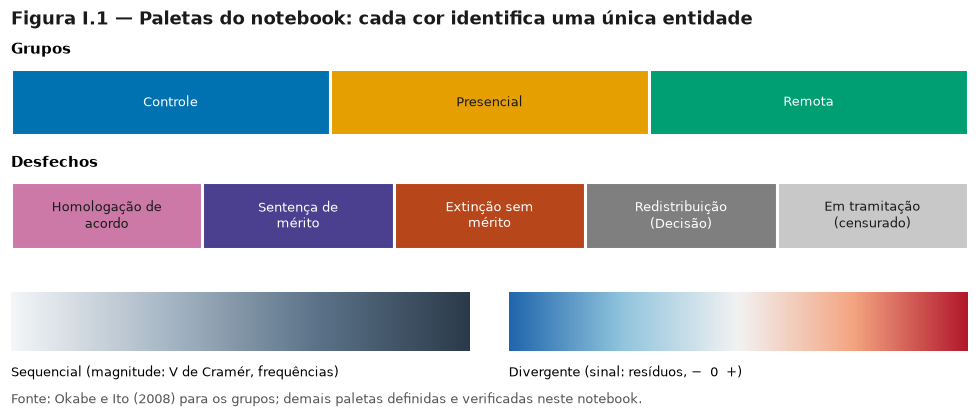

In [4]:
_MACHADO = {
    'protanopia': np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    'deuteranopia': np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
}


def _linear(cor):
    c = np.array(mpl.colors.to_rgb(cor))
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _oklab(rgb_linear):
    rgb_linear = np.clip(rgb_linear, 0, 1)
    lms = np.array([[0.4122214708, 0.5363325363, 0.0514459929], [0.2119034982, 0.6806995451, 0.1073969566],
                    [0.0883024619, 0.2817188376, 0.6299787005]]) @ rgb_linear
    return np.array([[0.2104542553, 0.7936177850, -0.0040720468], [1.9779984951, -2.4285922050, 0.4505937099],
                     [0.0259040371, 0.7827717662, -0.8086757660]]) @ np.cbrt(lms)


def delta_e(a, b, simulacao=None):
    """ΔE OKLab (×100) entre duas cores, opcionalmente sob simulação de daltonismo (Machado et al., 2009)."""
    A, B = _linear(a), _linear(b)
    if simulacao:
        A, B = _MACHADO[simulacao] @ A, _MACHADO[simulacao] @ B
    return 100 * float(np.linalg.norm(_oklab(A) - _oklab(B)))


def relatorio_cvd(nome, cores, pares):
    linhas = []
    for a, b in pares:
        d = {'Paleta': nome, 'Par': f'{a} × {b}', 'ΔE normal': delta_e(cores[a], cores[b])}
        for s in _MACHADO:
            d[f'ΔE {s}'] = delta_e(cores[a], cores[b], s)
        linhas.append(d)
    return linhas


_pares_grupo = [(a, b) for i, a in enumerate(ORDEM_GRUPO) for b in ORDEM_GRUPO[i + 1:]]
_pares_desf = list(zip(ORDEM_DESFECHO[:-1], ORDEM_DESFECHO[1:]))           # vizinhos nas barras empilhadas
_cromaticos = ['Homologação', 'Mérito', 'Sem mérito']
_cruzadas = {**{f'grupo {g}': CORES_GRUPO[g] for g in ORDEM_GRUPO}, **{f'desfecho {k}': CORES_DESFECHO[k] for k in _cromaticos}}
_pares_cruz = [(f'grupo {g}', f'desfecho {k}') for g in ORDEM_GRUPO for k in _cromaticos]
cvd = pd.DataFrame(relatorio_cvd('Grupos (todos os pares)', CORES_GRUPO, _pares_grupo)
                   + relatorio_cvd('Desfechos (vizinhos)', CORES_DESFECHO, _pares_desf)
                   + relatorio_cvd('Grupo × desfecho (mesmo gráfico)', _cruzadas, _pares_cruz))
cvd['Pior simulado'] = cvd[['ΔE protanopia', 'ΔE deuteranopia']].min(axis=1)
cvd['Situação'] = np.select([(cvd['Pior simulado'] >= 8) & (cvd['ΔE normal'] >= 15), cvd['Pior simulado'] >= 6],
                            ['passa', 'passa com rótulo/legenda'], 'exige 2º canal (forma, posição)')
resumo_cvd = cvd.groupby('Paleta', sort=False).agg(**{'Pares': ('Par', 'size'), 'Menor ΔE normal': ('ΔE normal', 'min'),
                                                      'Menor ΔE simulado': ('Pior simulado', 'min')})
tabela(resumo_cvd, 'cur_cvd_resumo', 'Distância perceptual mínima entre as cores de cada paleta (ΔE OKLab × 100)',
       secao='1.2.1', casas=1,
       nota='simulação de Machado, Oliveira e Fernandes (2009), severidade 1,0; alvo ≥ 8 sob simulação e ≥ 15 sem simulação. '
            'A linha "grupo × desfecho" é informativa: grupos e desfechos só dividem o mesmo gráfico quando a forma '
            '(linha × marcador) também os distingue.')
_fracos = cvd[cvd['Situação'] != 'passa']
if len(_fracos):
    print('Pares abaixo do alvo (exigem segundo canal):')
    for _, r in _fracos.iterrows():
        print(f"  {r['Par']}: ΔE normal {fmt_br(r['ΔE normal'])}; pior simulado {fmt_br(r['Pior simulado'])} → {r['Situação']}")

# Mapas sequencial e divergente: luminosidade OKLab monotônica
_L = lambda mapa, xs: [_oklab(_linear(mapa(x)))[0] for x in xs]
_seq_L = _L(SEQ, np.linspace(0, 1, 11))
_div_L = _L(DIV, np.linspace(0, 1, 11))
print('Sequencial: luminosidade decrescente (claro → escuro):', all(np.diff(_seq_L) < 0))
print('Divergente: luminosidade cresce até o meio e decresce depois:',
      all(np.diff(_div_L[:6]) > 0) and all(np.diff(_div_L[5:]) < 0))

fig, ax = plt.subplots(3, 1, figsize=(9, 3.4), gridspec_kw={'height_ratios': [1, 1, 0.8]})
for a, (nome, cores_) in zip(ax[:2], [('Grupos', {g: CORES_GRUPO[g] for g in ORDEM_GRUPO}),
                                       ('Desfechos', {ROTULO_DESFECHO[k]: CORES_DESFECHO[k] for k in ORDEM_DESFECHO})]):
    for i, (rot, cor) in enumerate(cores_.items()):
        a.barh(0, 1, left=i, color=cor, edgecolor='white', linewidth=2)
        a.text(i + 0.5, 0, quebra(rot, 14), ha='center', va='center', fontsize=8.5, color=_cor_texto(cor))
    a.set_xlim(0, len(cores_)); a.set_axis_off(); a.set_title(nome, loc='left', fontsize=10)
gradiente = np.linspace(0, 1, 256)[None, :]
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=SEQ, extent=(0, 0.48, 0, 1))
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=DIV, extent=(0.52, 1, 0, 1))
ax[2].set_xlim(0, 1); ax[2].set_axis_off()
ax[2].text(0, -0.25, 'Sequencial (magnitude: V de Cramér, frequências)', fontsize=8.5, va='top', transform=ax[2].transAxes)
ax[2].text(0.52, -0.25, 'Divergente (sinal: resíduos, −  0  +)', fontsize=8.5, va='top', transform=ax[2].transAxes)
figura(fig, 'cur_paletas', 'Paletas do notebook: cada cor identifica uma única entidade', secao='1.2.1',
       fonte='Fonte: Okabe e Ito (2008) para os grupos; demais paletas definidas e verificadas neste notebook.')

---

## 1.3 Formação do dataset bruto

### 1.3.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.14).

In [5]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
tabela(abas, 'cur_abas', 'Abas da planilha e o papel de cada uma: só a aba Processos tem dados por processo', secao='1.3.1')

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
Processos,visível,A2:O946,13.317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.3.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [6]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
tabela(dados_brutos.head(5), 'cur_bruto_amostra', 'As cinco primeiras linhas da aba Processos, como lidas (dados brutos, sem tratamento)',
       secao='1.3.2', indice=True, exportar=False, nota='a primeira coluna (linha_excel) é o número da linha no Excel.')

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']
Linhas inteiramente vazias: 0 | números de processo distintos: 938


linha_excel,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
3,0800001-35.2026.8.20.5004,01/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,07/01/2026,6,–,6,6,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,–,–,–,274,–,274,274,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,09/01/2026,3,–,3,3,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,07/01/2026,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,22/02/2026,46,46,46,46,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,07/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,27/02/2026,51,–,51,51,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.10). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.4).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.4 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [7]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
tabela(pd.DataFrame(formulas), 'cur_formulas', 'Colunas calculadas por fórmula (J a O): a duração dos ativos depende de TODAY()',
       secao='1.4')

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
J,DURAÇÃO-SENT2,943,Sim,Sim,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
K,DURAÇÃO-TECN,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
L,DURAÇÃO-SORT,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
M,DURAÇÃO-PROC,943,Sim,Sim,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
N,DURAÇÃO DO PROCESSO,943,Não,Não,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
O,STATUS,943,Não,Não,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [8]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
tabela(data_referencia.dt.strftime('%d/%m/%Y').value_counts().rename_axis('Data implícita de TODAY()').rename('Processos ativos').to_frame(),
       'cur_data_today', 'Data em que TODAY() foi avaliado, reconstituída dos valores em cache', secao='1.4')
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
tabela(iguais, 'cur_duracoes_iguais', 'As colunas de duração repetem DURAÇÃO-PROC (mesma variável, E6)', secao='1.4')
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

Data implícita de TODAY(),Processos ativos
07/10/2026,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


Coluna,Não nulas,Iguais a DURAÇÃO-PROC
DURAÇÃO-SENT2,943,943
DURAÇÃO-TECN,428,428
DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.14) mostra que não há nenhum caso.

---

## 1.5 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [9]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
tabela(perfil_bruto.rename_axis('Coluna bruta'), 'cur_perfil_bruto', 'Perfil das colunas como lidas pelo pandas: dtype, tipos presentes e ausências',
       secao='1.5', formatos={'dtype lido': 'texto'})

Coluna bruta,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.6 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [10]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
tabela(TIPOLOGIA_BRUTA, 'cur_tipologia', 'Tipologia estatística das colunas da planilha e decisão de tratamento', secao='1.6')

Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.7 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [11]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


tabela(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS), 'cur_ausencias', 'Três formas de ausência por coluna digitada (linhas da planilha)',
       secao='1.7', nota='NaN = não informado; "**" = não se aplica (zero estrutural).')

Coluna,NaN,"""**""",Vazio/espaços,Válidos
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.7.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [12]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
tabela(tabela_padrao.sort_values('Total', ascending=False).rename_axis('Padrão (1 = NaN)'), 'cur_padroes_ausencia',
       'Padrões de ausência em cinco colunas, por status e grupo sorteado: as lacunas acompanham a etapa do processo',
       secao='1.7.1', formatos={'Padrão (1 = NaN)': 'texto'},
       nota='ordem das posições no padrão: ' + ', '.join(COLUNAS_PADRAO) + '.')
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

Padrão (1 = NaN),(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; azul-acinzentado claro = `**` (não se aplica); ardósia escura = `NaN` (não informado).

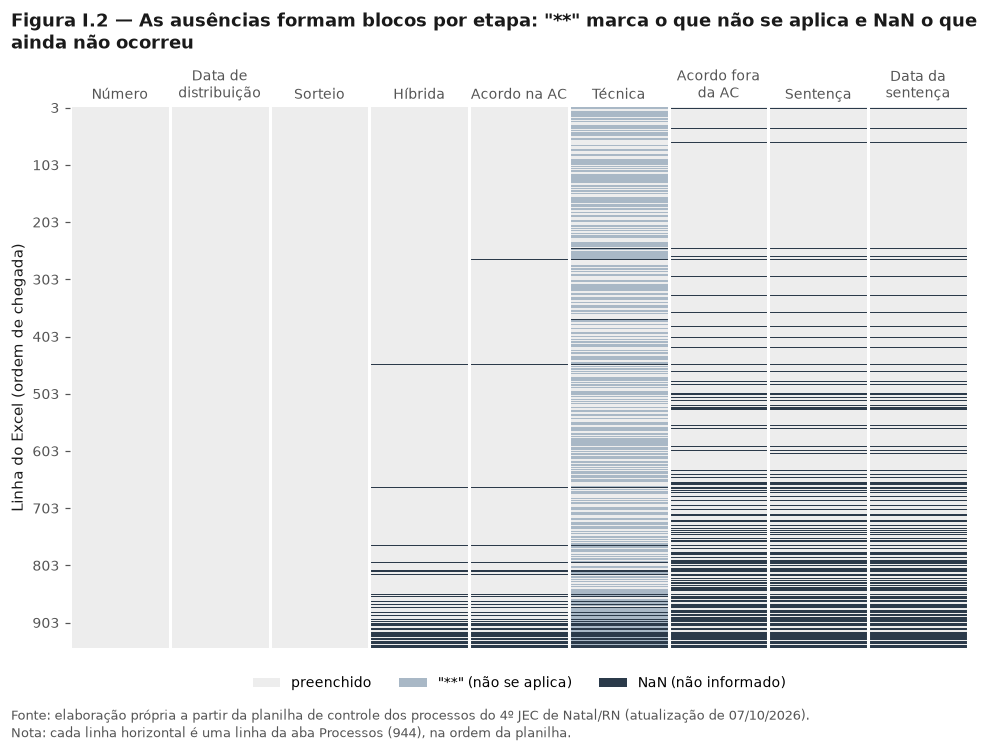

In [13]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
CORES_AUSENCIA = ['#EDEDED', '#A9B8C6', '#2B3A4A']   # preenchido, "**", NaN (sem matizes de grupo/desfecho)
fig, ax = plt.subplots(figsize=(9, 6))
mapa = mpl.colors.ListedColormap(CORES_AUSENCIA)
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Data de distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Data da sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), [quebra(r, 12) for r in ROTULOS_CURTOS])
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0)
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(COLUNAS_DIGITADAS)), minor=True)
ax.grid(which='minor', axis='x', color='white', lw=2)
ax.tick_params(which='minor', length=0)
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(CORES_AUSENCIA, ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
legenda_abaixo(ax, handles=legenda, ncol=3, dy=-0.03)
figura(fig, 'cur_mapa_ausencias',
       'As ausências formam blocos por etapa: "**" marca o que não se aplica e NaN o que ainda não ocorreu',
       secao='1.7.1', nota='cada linha horizontal é uma linha da aba Processos (944), na ordem da planilha.')

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.11 e 1.12. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.8 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [14]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


tabela(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}),
       'cur_renomear', 'Nomes das colunas na cópia de trabalho (o repr mostra espaços extras do original)', secao='1.8')

Coluna original,Nome na cópia de trabalho
'NÚMERO DO PROCESSO',numero_bruto
'DT. DISTRIBUIÇÃO',dt_distribuicao
'SORTEIO',sorteio
'HÍBRIDA',hibrida_bruto
'TEVE ACORDO NA AC?',acordo_ac_bruto
'TÉCNICA',tecnica_bruto
'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
'SENTENÇA',sentenca_bruto
'DT. SENTENÇA',dt_sentenca
'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.9 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [15]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
tabela(numero[fora].map(repr).rename('Valor bruto (repr)').to_frame().rename_axis('Linha do Excel'), 'cur_cnj_fora',
       'Números de processo fora do padrão CNJ antes da limpeza', secao='1.9', formatos={'Linha do Excel': 'texto'})

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
tabela(pd.DataFrame({'Número truncado': passo2[truncado],
                     'Órgãos 5000–5399 com DV válido': pd.Series(candidatos).map(lambda l: ', '.join(map(str, l)))}
                    ).rename_axis('Linha do Excel'),
       'cur_cnj_truncado', 'Números com órgão truncado: órgãos candidatos que fecham o dígito verificador', secao='1.9',
       formatos={'Linha do Excel': 'texto'})
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


Linha do Excel,Valor bruto (repr)
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


Linha do Excel,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"
453,0806739-39.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.9.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [16]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
tabela(pd.crosstab([trab['cnj_ano'].astype(str).rename('Ano (CNJ)'), trab['cnj_orgao'].rename('Órgão (CNJ)')],
                   trab['sorteio'], margins=True, margins_name='Total'),
       'cur_cnj_orgao_ano', 'Ano e órgão de origem do número CNJ por grupo sorteado (linhas da planilha)', secao='1.9.1', indice=True)
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

origem_externa: 12 linhas


---

## 1.10 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [17]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
tabela(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca', 'xl_status']]
       .rename_axis('Linha do Excel').rename(columns={'processo': 'Processo', 'dt_distribuicao': 'Distribuição', 'sorteio': 'Sorteio',
                                                       'tecnica_bruto': 'Técnica', 'sentenca_bruto': 'Sentença',
                                                       'dt_sentenca': 'Data da sentença', 'xl_status': 'STATUS'}),
       'cur_duplicados', 'Números de processo repetidos: reentradas após redistribuição, às vezes sorteadas para outro grupo',
       secao='1.10', formatos={'Linha do Excel': 'texto', 'Processo': 'texto'})
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

Linha do Excel,Processo,Distribuição,Sorteio,Técnica,Sentença,Data da sentença,STATUS
162,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,**,Decisão,18/02/2026,Encerrado
164,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,–,–,–,Ativo
290,0804436-52.2026.8.20.5004,18/03/2026,Ac Obrigatória Presencial,**,Decisão,18/03/2026,Encerrado
322,0804436-52.2026.8.20.5004,24/03/2026,Ac Obrigatória Presencial,**,Decisão,09/04/2026,Encerrado
475,0804436-52.2026.8.20.5004,27/04/2026,Rito Atual Ac Opcional,**,Decisão,27/04/2026,Encerrado
591,0808905-44.2026.8.20.5004,20/05/2026,Ac Remota,**,Decisão,21/05/2026,Encerrado
607,0808905-44.2026.8.20.5004,22/05/2026,Ac Remota,**,–,–,Ativo
819,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,–,–,–,Ativo
822,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,**,Extinção do Feito com Homologação do Acordo,16/09/2026,Encerrado
851,0812839-10.2026.8.20.5004,15/07/2026,Ac Remota,Padrões Objetivos,–,–,Ativo


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [18]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio'), trab['base_primaria'].map({True: 'Mantidas', False: 'Excluídas'}),
                   margins=True, margins_name='Total'),
       'cur_base_primaria', 'Linhas mantidas na base primária e excluídas (duplicata/reentrada), por grupo sorteado', secao='1.10')

Base primária: 938 processos


Sorteio,Excluídas,Mantidas,Total
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.11 Categorias: grafia, partições e recodificações

### 1.11.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [19]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
tabela(pd.DataFrame(diagnostico), 'cur_grafias', 'Grafias distintas e chaves normalizadas por coluna categórica', secao='1.11.1')

Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
sorteio,0,3,3
hibrida_bruto,0,2,2
acordo_ac_bruto,0,2,2
tecnica_bruto,0,7,7
acordo_fora_bruto,0,3,3
sentenca_bruto,0,5,4


### 1.11.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [20]:
tabela(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
       .assign(Chave=lambda t: t.index.map(normalizar_chave)),
       'cur_sentenca_grafias', 'Grafias do tipo de sentença na planilha e chave normalizada', secao='1.11.2')

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
tabela(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)').rename('Sentença (planilha)'), trab['tipo_desfecho']),
       'cur_recod_desfecho', 'Recodificação da sentença da planilha no tipo de desfecho', secao='1.11.2')

Grafia,Linhas,Chave
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
–,210,–
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


Sentença (planilha),Homologação,Mérito,Sem mérito,Redistribuição,Ativo
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.11.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [21]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio (planilha)'), trab['grupo']), 'cur_recod_grupo',
       'Recodificação do grupo sorteado', secao='1.11.3')

Sorteio (planilha),Controle,Presencial,Remota
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.11.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [22]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

_sn = lambda s: s.map({True: 'Sim', False: 'Não'}).astype(object).fillna('<NA>')
tabela(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)').rename('Técnica (planilha)'),
                   _sn(trab['ac_realizada']).rename('AC realizada'), margins=True, margins_name='Total'),
       'cur_tecnica_ac', 'Técnica registrada × AC realizada: "**" indica que a audiência não ocorreu', secao='1.11.4')
tabela(pd.crosstab([_sn(trab['acordo_ac']).rename('Acordo na AC'), _sn(trab['acordo_fora']).rename('Acordo fora da AC')],
                   trab['tipo_desfecho']),
       'cur_acordos_desfecho', 'Acordo na AC e fora dela × tipo de desfecho', secao='1.11.4', indice=True)

Técnica (planilha),,Não,Sim,Total
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.12 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [23]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
tabela(coerencia_grupo, 'cur_coerencia', 'Coerência entre o grupo sorteado e o que ocorreu: o Controle não tem AC (zeros estruturais)',
       secao='1.12')
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
tabela(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                           'hibrida_remota', 'hibrida_sem_ac']].rename_axis('Linha do Excel'),
       'cur_desvios', 'Processos com desvio de protocolo (marcados para análise de sensibilidade)', secao='1.12',
       formatos={'Linha do Excel': 'texto', 'processo': 'texto'})

grupo,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


Linha do Excel,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
318,0804822-82.2026.8.20.5004,Remota,Sim,Separação de Pessoas e Problemas,Mérito,Sim,Não
433,0806545-39.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
455,0806829-47.2026.8.20.5004,Presencial,Sim,**,Homologação,Não,Sim
456,0806797-42.2026.8.20.5004,Remota,Sim,Teoria do Afago ou do Reforço Positivo,Ativo,Sim,Não
712,0810564-88.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
832,0812493-59.2026.8.20.5004,Remota,Sim,–,Ativo,Sim,Não


### 1.12.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [24]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
tabela(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']]
       .rename(columns={'count': 'n', 'min': 'Mínimo (dias)', '50%': 'Mediana (dias)', 'mean': 'Média (dias)', 'max': 'Máximo (dias)'})
       .rename_axis('Grupo'),
       'cur_redistribuicoes', 'Dias da distribuição até a Decisão de redistribuição, por grupo (todas as linhas)',
       secao='1.12.1', casas=1)
tabela(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
       .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tecnica': 'Técnica', 'dias': 'Dias até a Decisão'}),
       'cur_redist_com_ac', 'Redistribuições ocorridas depois de uma AC realizada', secao='1.12.1',
       indice=False, formatos={'Processo': 'texto'})

26 redistribuições (todas as linhas); na base primária: 24


Grupo,n,Mínimo (dias),Mediana (dias),Média (dias),Máximo (dias)
Controle,6,0,1,"4,2",20
Presencial,11,0,1,"3,0",16
Remota,9,1,8,"25,4",84


Processo,Grupo,Técnica,Dias até a Decisão
0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.13 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.13.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [25]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.13.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [26]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
tabela(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
       .size().reindex(DIAS).rename('Sentenças').to_frame().T, 'cur_sentenca_dia_semana',
       'Sentenças por dia da semana da data registrada', secao='1.13.2', indice=False)

Sentenças em fim de semana: 135 de 734


seg,ter,qua,qui,sex,sáb,dom
91,186,149,85,88,70,65


### 1.13.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [27]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
tabela(dados.dtypes.astype(str).rename('dtype').rename_axis('Variável').to_frame(), 'cur_dtypes_tidy',
       'Tipos finais das variáveis do dataset tidy', secao='1.13.3', formatos={'dtype': 'texto'})
tabela(dados.head(5), 'cur_tidy_amostra', 'As cinco primeiras linhas do dataset tidy (base primária)', secao='1.13.3',
       exportar=False, indice=False)

dados_todas: (944, 40) | dados (base primária): (938, 37)


Variável,dtype
processo,string
linha_excel,Int64
ordem_chegada,Int64
dt_distribuicao,datetime64[ns]
dia_estudo,Int64
mes_distribuicao,category
ciclo,category
dia_semana_distribuicao,category
grupo,category
grupo_rotulo,category


processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0800001-35.2026.8.20.5004,3,1,01/01/2026,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,07/01/2026,Sim,6,6,1,1,3,279,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não
0800024-78.2026.8.20.5004,4,2,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,–,–,Ativo,–,Não,274,274,0,0,0,274,2.026,5004,Não,Não,Não,Não,–,Não,Não,Não,Não
0808292-43.2025.8.20.5300,5,3,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,09/01/2026,Sim,3,3,1,1,3,274,2.025,5300,Não,Sim,Não,Não,Não,Não,Não,Não,Não
0800038-62.2026.8.20.5004,6,4,07/01/2026,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,Sim,Desconstrução da Verdade,Desconstrução,Não,Sim,Não,Sim,Homologação,22/02/2026,Sim,46,46,1,1,1,273,2.026,5004,Não,Não,Não,Não,Sim,Não,Não,Não,Não
0800035-10.2026.8.20.5004,7,5,07/01/2026,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Mérito,27/02/2026,Sim,51,51,1,1,2,273,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não


---

## 1.14 Verificações

### 1.14.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [28]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
tabela(pd.DataFrame(resumo_particoes), 'cur_particoes', 'Verificação das partições: cada variável categórica cobre todos os processos',
       secao='1.14.1')
print('Todas as verificações passaram.')

Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
grupo,3,0,0,0,Sim,Sim
grupo_rotulo,3,0,0,0,Sim,Sim
tipo_desfecho,5,0,0,0,Sim,Sim
mes_distribuicao,8,0,0,0,Sim,Sim
ciclo,2,0,0,0,Sim,Sim
dia_semana_distribuicao,7,0,0,0,Sim,Sim
tecnica,6,0,586,0,Sim,Sim
tecnica_curta,6,0,586,0,Sim,Sim


Todas as verificações passaram.


### 1.14.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [29]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
tabela(fluxo.rename_axis('Etapa'), 'cur_fluxo', 'Fluxo dos processos, da planilha à situação em 07/10/2026, por grupo',
       secao='1.14.2', formatos={c: 'texto' for c in fluxo.columns})
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

Etapa,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.14.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [30]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
tabela(conf.astype(str), 'cur_conferencia', 'Conferência com os números divulgados pela pesquisadora', secao='1.14.3')

Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
Processos (linhas com STATUS),943 (Tab_D),943,938
Encerrados (STATUS),734 (Tab_D),734,732
Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
Acordos (homologações),81 (Tabelas),81,81
Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.15 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [31]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
tabela(resumo_log, 'cur_log_resumo', 'Resumo do log de tratamentos por anomalia e ação', secao='1.15')
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

codigo,problema,tratamento,linhas,exemplos
A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.16 Dicionário de variáveis e exportação

### 1.16.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [32]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
tabela(dicionario, 'cur_dicionario', 'Dicionário de variáveis do dataset tidy', secao='1.16.1')

variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.16.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.15) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.16.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [33]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB


ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

# PARTE VI — RESPOSTAS ÀS QUESTÕES DO PROFESSOR (2.2 A 2.12)

Esta parte responde, uma a uma, às questões 2.2 a 2.12 do roteiro `estudo_de_caso_n_2.md`. Cada resposta (i) resume o enunciado; (ii) argumenta com base nas evidências produzidas nas Partes I a V, às quais remete pela numeração das seções; e (iii) quando útil, traz um quadro ou uma figura próprios. Os poucos cálculos feitos aqui (fluxo dos processos, equilíbrio das variáveis basais, contraste entre medianas ingênuas e de Kaplan-Meier) são **de apoio**: não substituem nem refazem as análises das partes anteriores.

| Questão | Tema | Seção | Evidência principal |
|---|---|---|---|
| 2.2 | EO ou ECA? | 6.1 | 1.10, 1.12, 2.5.1, 3.5 |
| 2.3 | Amostras independentes de uma mesma população? | 6.2 | 2.5.1, 3.5.1, 3.5.3 |
| 2.4 | "Híbrida" e "Decisão" | 6.3 | 1.11, 1.12, 3.2.4, 3.3.4, 4.7, 4.9 |
| 2.5 | Populações e cruzamento com os 14 JECs (DataJud) | 6.4 | Parte VIII |
| 2.6 | Tratamento dos dados brutos | 6.5 | Parte I inteira |
| 2.7 | Matriz de correlações; ordem de chegada × duração | 6.6 | 2.6.4, 2.6.5, 3.5.2, 4.5 |
| 2.8 | Variáveis de confundimento | 6.7 | 3.5.3, 4.3.4, 4.9 |
| 2.9 | Outras variáveis em escala intervalar | 6.8 | 5 (limitação), 2.6.4 |
| 2.10 | Validade interna e externa; generalização | 6.9 | Partes III a V |
| 2.11 | Adequação dos TSHN do professor | 6.10 | 3.4, 3.6, Parte IV |
| 2.12 | Avaliação geral e sugestões | 6.11 | todas; Parte VII |

In [34]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')
from matplotlib.patches import FancyBboxPatch
from scipy.stats import chi2_contingency

q6 = dados.copy()
q6['grupo'] = pd.Categorical(q6['grupo'].astype(str), categories=ORDEM_GRUPO)
q6['desfecho'] = q6['tipo_desfecho'].astype(str)
q6['acr'] = q6['ac_realizada'].astype(object)
n_grupo = q6['grupo'].value_counts().reindex(ORDEM_GRUPO)
todas_q6 = pd.read_pickle(PROC / 'ed2_todas_linhas.pkl')
RNG_Q6 = np.random.default_rng(SEMENTE)


def q6_csv(nome, pasta='tab'):
    """Lê um CSV exportado pelas Partes II–V (';' e vírgula decimal); None se ainda não existir."""
    caminho = RAIZ / pasta / nome
    if not caminho.exists():
        print(f'Aviso: {pasta}/{nome} não encontrado (é gerado pelas Partes II a V).')
        return None
    return pd.read_csv(caminho, sep=';', decimal=',', encoding='utf-8-sig')


def q6_chi2_perm(tab, n_perm=20000, rng=RNG_Q6):
    """χ² de independência com valor-p por permutação (tabelas com esperadas pequenas)."""
    tab = np.asarray(tab)
    chi2_obs, p_ass, gl, esp = chi2_contingency(tab, correction=False)
    linhas = np.repeat(np.arange(tab.shape[0]), tab.sum(axis=1))
    colunas = np.repeat(np.arange(tab.shape[1]), tab.sum(axis=0))
    maiores = 0
    for _ in range(n_perm):
        perm = rng.permutation(colunas)
        t = np.zeros_like(tab)
        np.add.at(t, (linhas, perm), 1)
        maiores += chi2_contingency(t, correction=False)[0] >= chi2_obs - 1e-12
    v = np.sqrt(chi2_obs / (tab.sum() * (min(tab.shape) - 1)))
    return chi2_obs, gl, p_ass, (maiores + 1) / (n_perm + 1), esp.min(), v

print(f'Base primária: {len(q6)} processos; linhas brutas: {len(todas_q6)}; '
      f'grupos: ' + ', '.join(f'{g} {n_grupo[g]}' for g in ORDEM_GRUPO))

Base primária: 938 processos; linhas brutas: 944; grupos: Controle 313, Presencial 314, Remota 311


## 6.1 Questão 2.2 — Estudo observacional (EO) ou ensaio controlado aleatorizado (ECA)?

**Enunciado.** Trata-se de um EO ou de um ECA? Qual a diferença entre eles?

**A diferença.** O critério que separa os dois desenhos é **quem atribui a exposição** e **como**. No **estudo observacional**, o pesquisador apenas registra a exposição que as unidades "escolheram" ou receberam por circunstâncias alheias a ele; a comparação entre expostos e não expostos fica sujeita a **confundimento**, porque os grupos podem diferir em fatores que também afetam o desfecho, e a inferência causal exige controlar esses fatores (por ajuste, pareamento ou estratificação), sempre com o risco de confundidores não medidos. No **experimento** (ensaio controlado aleatorizado), o pesquisador **impõe** o tratamento e o faz **por sorteio**, com um grupo de comparação **contemporâneo**; a aleatorização torna os grupos comparáveis **em expectativa** quanto a todos os fatores anteriores à alocação, medidos ou não, e é isso que autoriza ler a diferença dos desfechos como efeito causal do tratamento (MOORE; NOTZ; FLIGNER, 2023, cap. 9, citados no próprio resumo expandido).

**O caso.** O experimento do 4º JEC é um **ECA**, e não um EO, quanto ao rito: cada processo novo foi alocado pelo pesquisador, por sorteio individual, a um de três ritos (rito atual, AC presencial obrigatória ou AC remota obrigatória), e os três grupos correram em paralelo no mesmo período e na mesma unidade. A Parte III não encontrou sinal de alocação não aleatória: o teste de corridas sobre a ordem de chegada não rejeita a aleatoriedade (seção 3.5.1) e a composição por mês, embora desigual em junho e julho, não difere do acaso ao nível de 5% (seção 3.5.3). Com mais precisão, é um **ECA pragmático, de centro único, aberto (sem cegamento), com aleatorização individual e alocação 1:1:1**, cujo sorteio produziu totais **equilibrados demais** para um sorteio simples (seção 2.5.1), o que indica **sorteio com restrição** (lista balanceada, cotas ou compensação). Isso não descaracteriza a aleatorização, mas exige que o mecanismo seja documentado.

Três ressalvas impedem chamá-lo de ECA "puro" em todos os aspectos:

1. **dentro do ECA há componentes observacionais**: a realização da AC, a audiência "híbrida", o acordo e a ausência das partes ocorrem **depois** do sorteio e dependem de escolhas das partes; comparações por essas variáveis (por exemplo, "processos com AC realizada × sem AC") são observacionais (seções 3.2.3 e 4.8);
2. **a unidade judicial não foi sorteada**: o 4º JEC entrou por conveniência (os outros 13 juízes não aderiram); para a população dos 14 JECs, o estudo é um **estudo de caso único** (um conglomerado), e não um ensaio por conglomerados;
3. **o próprio projeto se classifica de forma incoerente**: o resumo expandido fala em "experimento controlado aleatorizado"; o projeto depositado usa a diretriz TREND, destinada a desenhos **não aleatorizados** ("quase experimental"), e chega a falar em "estudo observacional" (ver `docs/r1_documentos.md`, §5). Pelo critério acima, prevalece a classificação de ECA; a diretriz de relato adequada seria a CONSORT, e não a TREND.

O quadro a seguir resume a comparação; o diagrama de fluxo, no formato CONSORT, mostra o percurso dos 944 registros da planilha até os desfechos observados em 07/10/2026.

In [35]:
quadro_eo = pd.DataFrame([
    ['Quem atribui a exposição', 'a própria unidade, as circunstâncias ou terceiros; o pesquisador só observa',
     'o pesquisador, por sorteio', 'o juiz-pesquisador, por sorteio individual de cada processo novo (Chefe de Gabinete, sorteio.com.br)'],
    ['Grupo de comparação', 'expostos × não expostos, às vezes históricos', 'contemporâneo, formado pelo mesmo sorteio',
     'contemporâneo: rito atual (Controle), sorteado junto com os dois braços de AC'],
    ['Comparabilidade dos grupos', 'não garantida; depende de ajuste por confundidores medidos',
     'garantida em expectativa para todos os fatores anteriores ao sorteio', 'grupos de 313/314/311; mês e dia da semana compatíveis com o acaso (6.2)'],
    ['Inferência causal', 'só sob hipóteses fortes (sem confundidores não medidos)', 'direta para o efeito da alocação (ITT)',
     'válida para o efeito do rito dentro do 4º JEC (intenção de tratar)'],
    ['Variáveis pós-alocação', '—', 'não aleatorizadas: comparações por elas são observacionais',
     'AC realizada, híbrida, acordo e ausência das partes: observacionais'],
    ['Cegamento', 'em geral irrelevante', 'desejável (participantes, avaliadores, analistas)',
     'ausente: o juiz que sorteia também julga e analisa'],
    ['Nível da unidade de política', '—', 'várias unidades sorteadas (ensaio por conglomerados)',
     'uma unidade escolhida por conveniência (N = 1 conglomerado)'],
    ['Diretriz de relato', 'STROBE', 'CONSORT', 'CONSORT (o projeto cita TREND, própria de desenhos não aleatorizados)'],
], columns=['Característica', 'Estudo observacional (EO)', 'Ensaio controlado aleatorizado (ECA)', 'Experimento do 4º JEC'])
tabela(quadro_eo, 'q_eo_eca', 'EO × ECA: o experimento do 4º JEC é um ECA quanto ao rito, com componentes observacionais',
       secao='6.1', fonte='Elaboração própria a partir do projeto de pesquisa, do resumo expandido e das Partes I a III.')

Característica,Estudo observacional (EO),Ensaio controlado aleatorizado (ECA),Experimento do 4º JEC
Quem atribui a exposição,"a própria unidade, as circunstâncias ou terceiros; o pesquisador só observa","o pesquisador, por sorteio","o juiz-pesquisador, por sorteio individual de cada processo novo (Chefe de Gabinete, sorteio.com.br)"
Grupo de comparação,"expostos × não expostos, às vezes históricos","contemporâneo, formado pelo mesmo sorteio","contemporâneo: rito atual (Controle), sorteado junto com os dois braços de AC"
Comparabilidade dos grupos,não garantida; depende de ajuste por confundidores medidos,garantida em expectativa para todos os fatores anteriores ao sorteio,grupos de 313/314/311; mês e dia da semana compatíveis com o acaso (6.2)
Inferência causal,só sob hipóteses fortes (sem confundidores não medidos),direta para o efeito da alocação (ITT),válida para o efeito do rito dentro do 4º JEC (intenção de tratar)
Variáveis pós-alocação,—,não aleatorizadas: comparações por elas são observacionais,"AC realizada, híbrida, acordo e ausência das partes: observacionais"
Cegamento,em geral irrelevante,"desejável (participantes, avaliadores, analistas)",ausente: o juiz que sorteia também julga e analisa
Nível da unidade de política,—,várias unidades sorteadas (ensaio por conglomerados),uma unidade escolhida por conveniência (N = 1 conglomerado)
Diretriz de relato,STROBE,CONSORT,"CONSORT (o projeto cita TREND, própria de desenhos não aleatorizados)"


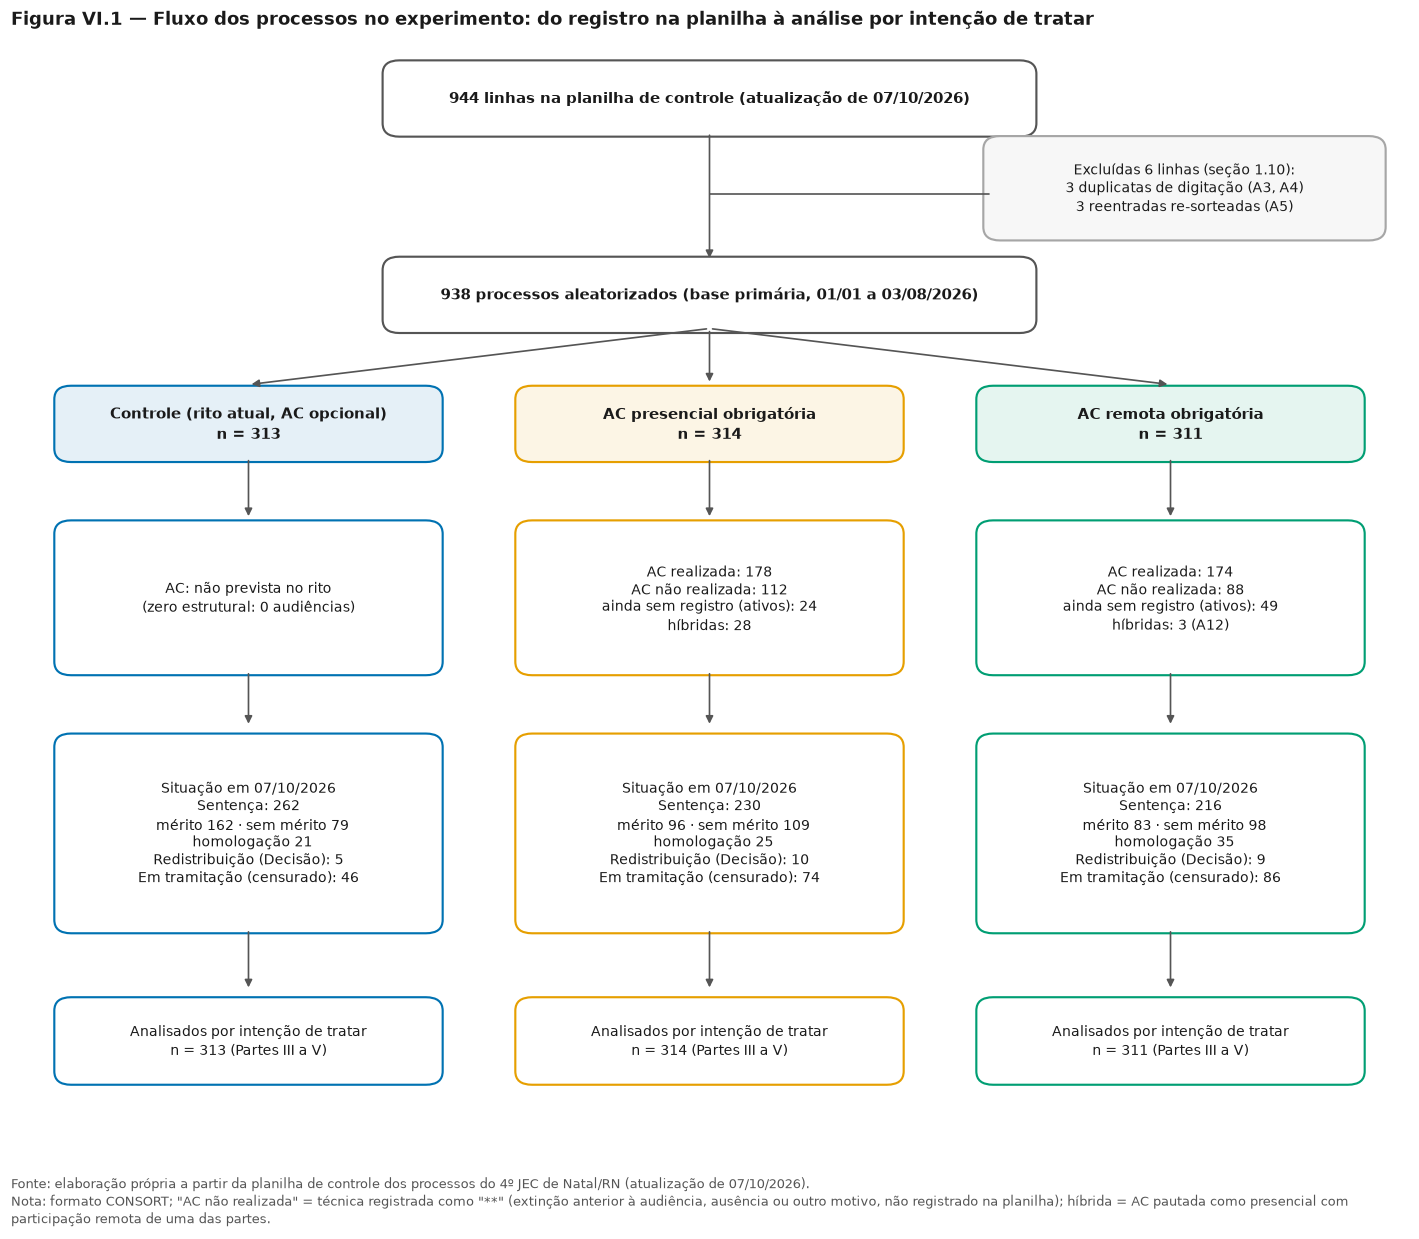

In [36]:
# ---- diagrama de fluxo (CONSORT) com as contagens da base
excl = todas_q6[~todas_q6['base_primaria'].astype(bool)]
n_a3a4 = int(excl['motivo_exclusao'].astype(str).str.startswith(('A3', 'A4')).sum())
n_a5 = int(excl['motivo_exclusao'].astype(str).str.startswith('A5').sum())

def q6_bloco_grupo(g):
    s = q6[q6['grupo'] == g]
    acr = s['acr']
    if g == 'Controle':
        linha_ac = 'AC: não prevista no rito\n(zero estrutural: 0 audiências)'
    else:
        hib = int(s['hibrida'].fillna(False).astype(bool).sum())
        linha_ac = (f'AC realizada: {int((acr == True).sum())}\n'
                    f'AC não realizada: {int((acr == False).sum())}\n'
                    f'ainda sem registro (ativos): {int(acr.isna().sum())}\n'
                    f'híbridas: {hib}' + (' (A12)' if g == 'Remota' else ''))
    cont = s['desfecho'].value_counts()
    sent = int(s['evento'].astype(int).sum())
    linha_desf = (f'Sentença: {sent}\n'
                  f'  mérito {int(cont.get("Mérito", 0))} · sem mérito {int(cont.get("Sem mérito", 0))}\n'
                  f'  homologação {int(cont.get("Homologação", 0))}\n'
                  f'Redistribuição (Decisão): {int(cont.get("Redistribuição", 0))}\n'
                  f'Em tramitação (censurado): {int(cont.get("Ativo", 0))}')
    return linha_ac, linha_desf

fig, ax = plt.subplots(figsize=(13, 10.5))
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis('off')

def caixa(x, y, w, h, texto, cor='#555555', fundo='white', peso='normal', tam=9.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.4,rounding_size=1.2',
                                fc=fundo, ec=cor, lw=1.4))
    ax.text(x, y, texto, ha='center', va='center', fontsize=tam, color=TINTA, fontweight=peso, linespacing=1.3)

def seta(x0, y0, x1, y1):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=TINTA_2, lw=1.1))

caixa(50, 95, 46, 6, f'{len(todas_q6)} linhas na planilha de controle (atualização de 07/10/2026)', peso='bold')
caixa(84, 87, 28, 8.5, f'Excluídas {len(excl)} linhas (seção 1.10):\n{n_a3a4} duplicatas de digitação (A3, A4)\n'
                         f'{n_a5} reentradas re-sorteadas (A5)', cor=CINZA, fundo='#f7f7f7', tam=9)
seta(50, 92, 50, 80.5); ax.plot([50, 70], [86.5, 86.5], color=TINTA_2, lw=1.1)
caixa(50, 77.5, 46, 6, f'{len(q6)} processos aleatorizados (base primária, 01/01 a 03/08/2026)', peso='bold')
xs = {'Controle': 17, 'Presencial': 50, 'Remota': 83}
for g, x in xs.items():
    seta(50, 74.5, x, 69.5)
    caixa(x, 66, 27, 6, f'{ROTULO_GRUPO[g]}\nn = {n_grupo[g]}', cor=CORES_GRUPO[g],
          fundo=mpl.colors.to_rgba(CORES_GRUPO[g], 0.10), peso='bold', tam=9.5)
    l_ac, l_desf = q6_bloco_grupo(g)
    seta(x, 63, x, 57.5)
    caixa(x, 50.5, 27, 13, l_ac, cor=CORES_GRUPO[g], tam=9)
    seta(x, 44, x, 39)
    caixa(x, 29.5, 27, 17, 'Situação em 07/10/2026\n' + l_desf, cor=CORES_GRUPO[g], tam=9)
    seta(x, 21, x, 15.5)
    caixa(x, 11, 27, 7, f'Analisados por intenção de tratar\nn = {n_grupo[g]} (Partes III a V)', cor=CORES_GRUPO[g], tam=9)
figura(fig, 'q_fluxo_consort', 'Fluxo dos processos no experimento: do registro na planilha à análise por intenção de tratar',
       secao='6.1', nota='formato CONSORT; "AC não realizada" = técnica registrada como "**" (extinção anterior à audiência, ausência '
                         'ou outro motivo, não registrado na planilha); '
                         'híbrida = AC pautada como presencial com participação remota de uma das partes.')

**Resposta à questão 2.2.** O diagrama de fluxo mostra o que caracteriza o estudo como **ECA**: os 938 processos da base primária foram repartidos por sorteio em três grupos praticamente iguais (313, 314 e 311), todos acompanhados até a mesma data e todos analisados no grupo sorteado (intenção de tratar), sem perdas. O diagrama mostra também onde o experimento deixa de ser experimento. A partir da segunda linha de caixas, o que acontece depende das partes, e não do sorteio: nos braços com AC, a audiência só foi realizada em 178 de 314 processos (Presencial) e 174 de 311 (Remota); 112 e 88 terminaram sem AC (a técnica ficou registrada como `**`), e 28 audiências presenciais foram híbridas. Comparar "quem teve AC" com "quem não teve" seria, portanto, um estudo observacional embutido no ensaio. Na linha dos desfechos já aparece o achado central: o Controle tem 162 sentenças de mérito e 79 extinções sem mérito; os braços com AC invertem essa proporção (96/109 e 83/98).

Em suma: **ECA** quanto ao rito, porque o pesquisador impôs a exposição por sorteio, com controle contemporâneo; **componentes observacionais** quanto a tudo o que ocorre depois do sorteio; e, quanto à pretensão de avaliar a política nos JECs de Natal, **estudo de caso de uma unidade**. A classificação do próprio projeto como "quase experimental" (TREND) ou "observacional" é imprecisa: o que falta ao experimento não é aleatorização, e sim ocultação da alocação, cegamento e mais de uma unidade.

## 6.2 Questão 2.3 — Os três grupos são amostras independentes de uma mesma população?

**Enunciado.** Decidir, justificadamente, se Controle, AC presencial e AC remota são amostras **independentes** extraídas de uma mesma população, e se isso influi na escolha dos testes.

**Resposta.** Sim, com uma precisão de linguagem e três ressalvas.

*Precisão.* Os grupos não são "amostras extraídas" de uma população por **amostragem probabilística**: são uma **partição aleatória** de um único conjunto, o fluxo de ações distribuídas ao 4º JEC entre 01/01 e 03/08/2026 (praticamente um censo da população disponível; ver 6.4). A "mesma população" é garantida pelo **sorteio**: antes da alocação, cada processo tinha a mesma chance de cair em qualquer grupo, de modo que os três grupos são, em expectativa, idênticos em tudo o que existia antes do sorteio. A base lógica da inferência é, portanto, a **aleatorização** (o que justifica testes de permutação e a interpretação dos testes clássicos como aproximações deles), e não a amostragem de uma população infinita.

*Independência.* Os grupos são **independentes entre si**: cada processo pertence a um só grupo (as reentradas re-sorteadas foram reconduzidas ao primeiro sorteio, A5, seção 1.10), e não há pareamento nem medidas repetidas da mesma unidade em grupos diferentes. A única verificação empírica possível, dado que a planilha não tem covariáveis do processo, é o equilíbrio das variáveis **basais de calendário**: o quadro e a figura abaixo testam mês e dia da semana da distribuição e a origem externa do processo.

*Ressalvas.* (i) **Dependência por agentes comuns**: o mesmo juiz, o mesmo cartório e a **mesma conciliadora em cada braço** atendem todos os processos de um grupo, o que cria correlação intragrupo (agrupamento) que os testes clássicos ignoram e que, no caso da conciliadora, não pode ser corrigida, porque ela coincide com a modalidade (6.7); (ii) **litigantes habituais** (bancos, operadoras) aparecem nos três grupos e podem induzir correlação entre processos, sem que a planilha permita identificá-los; (iii) o **sorteio restrito** (totais fixados ou compensados) cria uma dependência fraca entre as alocações, que torna os testes clássicos levemente conservadores e recomenda estratificar pelo período (seções 2.5.1 e 4.3.4).

*Influência sobre os testes.* Decisiva. Amostras independentes exigem testes para **k amostras independentes**: χ² de independência ou exato de Fisher para proporções; Kruskal-Wallis, Mann-Whitney e Dunn para posições; log-rank e Cox para tempos censurados. Os testes para amostras **dependentes** (McNemar, Wilcoxon pareado, Friedman, Q de Cochran) não se aplicam (seção 3.6.3). Além da independência, a **censura** e a natureza **nominal** de quase todas as variáveis pesam tanto quanto ela: é a censura que desloca a escolha do Kruskal-Wallis para o log-rank (6.10).

In [37]:
# ---- equilíbrio das variáveis basais (as únicas disponíveis antes do sorteio)
q6['mes7'] = q6['mes_distribuicao'].astype(str).replace({'ago': 'jul'})
ordem_mes7 = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul']
ordem_dia = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
variaveis_basais = {
    'Mês de distribuição (jul + ago)': ('mes7', ordem_mes7),
    'Dia da semana da distribuição': ('dia_semana_distribuicao', ordem_dia),
    'Origem externa (redistribuído à vara)': ('origem_ext_txt', ['Não', 'Sim']),
}
q6['origem_ext_txt'] = np.where(q6['origem_externa'].astype(bool), 'Sim', 'Não')
eq_linhas, eq_tabs = [], {}
for rotulo, (col, ordem) in variaveis_basais.items():
    tab_ = pd.crosstab(q6[col].astype(str), q6['grupo']).reindex(index=ordem, columns=ORDEM_GRUPO).fillna(0).astype(int)
    eq_tabs[rotulo] = tab_
    chi2_, gl_, p_ass_, p_perm_, esp_min_, v_ = q6_chi2_perm(tab_.to_numpy())
    eq_linhas.append({'Variável basal': rotulo, 'Categorias': len(ordem), 'χ²': chi2_, 'gl': gl_,
                      'Menor esperada': esp_min_, 'p (assintótico)': p_ass_, 'p (permutação)': p_perm_, 'V de Cramér': v_})
eq_df = pd.DataFrame(eq_linhas)
from statsmodels.stats.multitest import multipletests
eq_df['p Holm'] = multipletests(eq_df['p (permutação)'], method='holm')[1]
tabela(eq_df, 'q_equilibrio_basal', 'Equilíbrio das variáveis basais entre os grupos: nenhuma diferença além do acaso',
       secao='6.2', formatos={'gl': 'int', 'Categorias': 'int', 'Menor esperada': 1, 'χ²': 2, 'V de Cramér': 3},
       destaque='p Holm', nota='H0: distribuição da variável igual nos três grupos; p por permutação (20.000 réplicas); '
                               'Holm sobre as três variáveis. Agosto (6 processos) unido a julho.')

Variável basal,Categorias,χ²,gl,Menor esperada,p (assintótico),p (permutação),V de Cramér,p Holm
Mês de distribuição (jul + ago),7,"18,45",12,"34,2","0,103","0,102","0,099","0,306"
Dia da semana da distribuição,7,"10,44",12,"9,3","0,577","0,577","0,075","0,577"
Origem externa (redistribuído à vara),2,"3,50",2,"4,0","0,174","0,263","0,061","0,525"


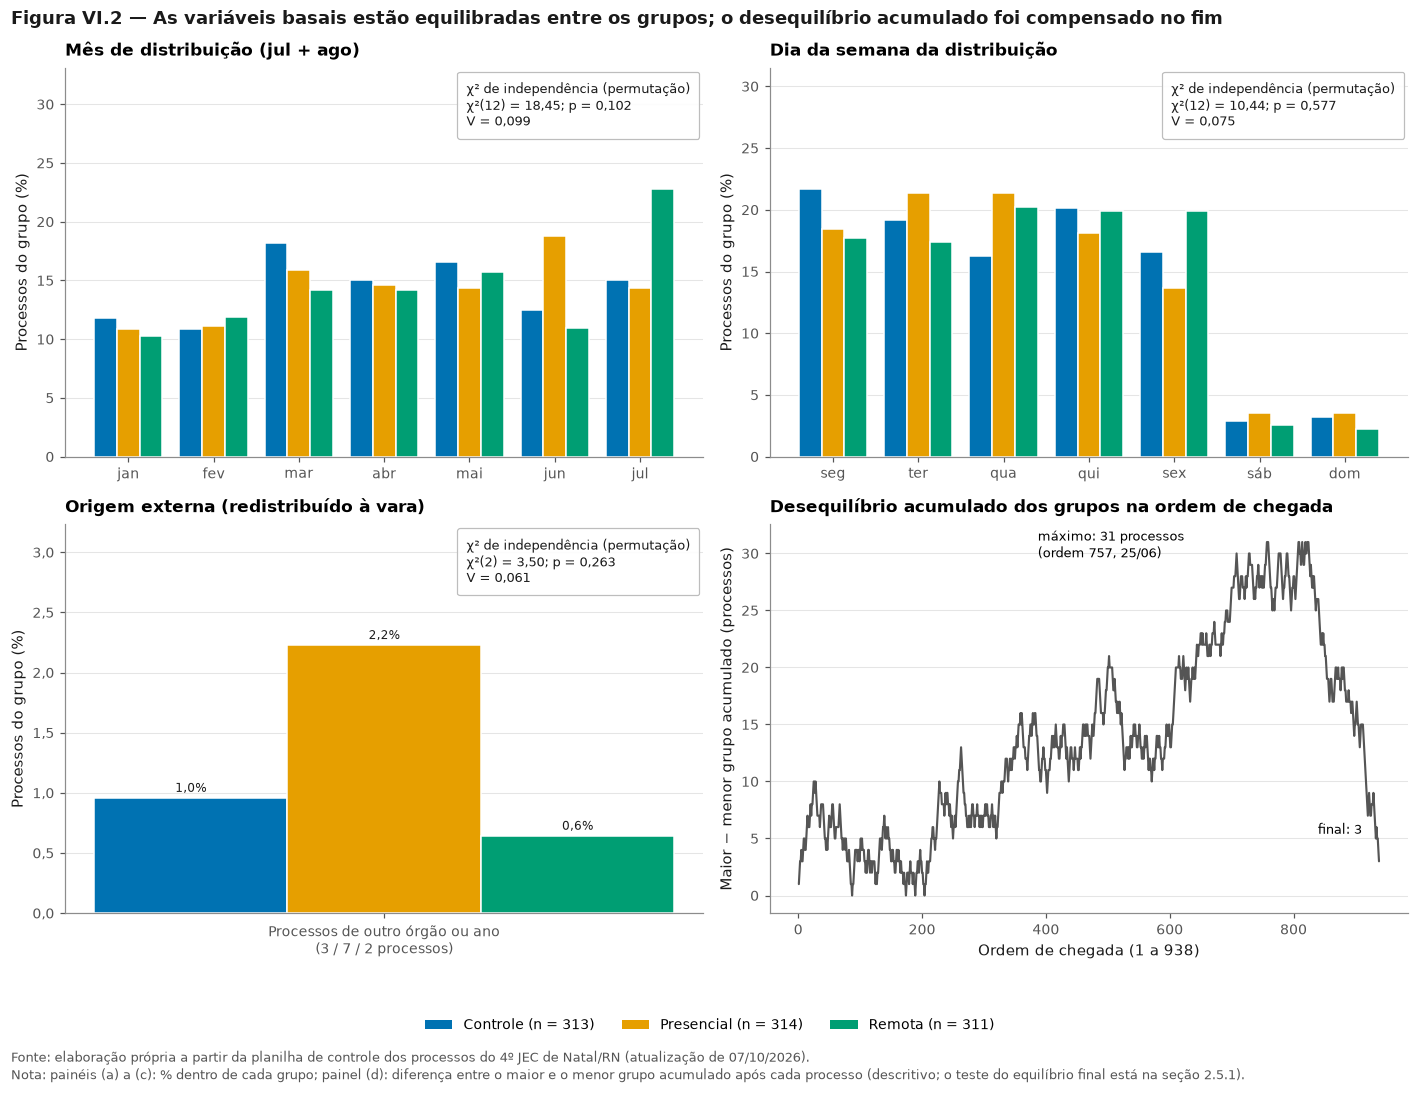

In [38]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, (rotulo, tab_) in zip(axs.ravel()[:3], eq_tabs.items()):
    pct = tab_.div(tab_.sum(axis=0), axis=1) * 100
    if rotulo.startswith('Origem'):          # só a categoria rara, para ser legível
        pct = pct.loc[['Sim']].rename(index={'Sim': 'Processos de outro órgão ou ano'})
        barras_agrupadas(ax, pct, cores=CORES_GRUPO, ylabel='Processos do grupo (%)', legenda=False, rotular=True,
                         fmt=lambda v: fmt_br(v, 1) + '%', quebrar=40)
        pct.index = [f'Processos de outro órgão ou ano\n(' + ' / '.join(str(int(tab_.loc['Sim', g])) for g in ORDEM_GRUPO)
                     + ' processos)']
        ax.set_xticks([0], pct.index)
    else:
        barras_agrupadas(ax, pct, cores=CORES_GRUPO, ylabel='Processos do grupo (%)', legenda=False)
    linha = eq_df.set_index('Variável basal').loc[rotulo]
    ax.set_ylim(0, pct.to_numpy().max() * 1.45)
    anotar_teste(ax, texto_teste('χ² de independência (permutação)', f'χ²({int(linha["gl"])}) = {fmt_br(linha["χ²"], 2)}',
                                 linha['p (permutação)'], f'V = {fmt_br(linha["V de Cramér"], 3)}'), loc='upper right')
    ax.set_title(rotulo)
# (d) desequilíbrio acumulado ao longo da ordem de chegada (descritivo: o sorteio restrito)
ordem = q6.sort_values('ordem_chegada')
acum = pd.get_dummies(ordem['grupo'].astype(str)).reindex(columns=ORDEM_GRUPO).cumsum()
amplitude = acum.max(axis=1) - acum.min(axis=1)
ax = axs[1, 1]
ax.plot(ordem['ordem_chegada'].astype(int).to_numpy(), amplitude.to_numpy(), color=TINTA_2, lw=1.4)
i_max = int(np.argmax(amplitude.to_numpy()))
ax.annotate(f'máximo: {int(amplitude.iloc[i_max])} processos\n(ordem {int(ordem["ordem_chegada"].iloc[i_max])}, '
            f'{ordem["dt_distribuicao"].iloc[i_max].strftime("%d/%m")})',
            (int(ordem['ordem_chegada'].iloc[i_max]), int(amplitude.iloc[i_max])), xytext=(-150, -10),
            textcoords='offset points', fontsize=8.5, arrowprops=dict(arrowstyle='-', color=TINTA_2))
ax.annotate(f'final: {int(amplitude.iloc[-1])}', (len(ordem), int(amplitude.iloc[-1])), xytext=(-40, 18),
            textcoords='offset points', fontsize=8.5, arrowprops=dict(arrowstyle='-', color=TINTA_2))
ax.set_xlabel(ROTULOS['ordem_chegada']); ax.set_ylabel('Maior − menor grupo acumulado (processos)')
ax.set_title('Desequilíbrio acumulado dos grupos na ordem de chegada')
fig.legend(handles=[mpl.patches.Patch(color=CORES_GRUPO[g], label=rotulo_grupo(g, com_n=True)) for g in ORDEM_GRUPO],
           loc='lower center', bbox_to_anchor=(0.5, -0.03), ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
figura(fig, 'q_equilibrio_basal', 'As variáveis basais estão equilibradas entre os grupos; o desequilíbrio acumulado foi compensado no fim',
       secao='6.2', nota='painéis (a) a (c): % dentro de cada grupo; painel (d): diferença entre o maior e o menor grupo '
                         'acumulado após cada processo (descritivo; o teste do equilíbrio final está na seção 2.5.1).')

**Resposta à questão 2.3.** As três variáveis basais disponíveis não diferem entre os grupos além do acaso: mês de distribuição χ²(12) = 18,45, p (permutação) = 0,102, V = 0,099; dia da semana χ²(12) = 10,44, p = 0,577, V = 0,075; origem externa χ²(2) = 3,50, p = 0,263 (3, 7 e 2 processos). Após Holm, nenhum p fica abaixo de 0,30. É o que se espera de grupos formados por sorteio a partir de **uma mesma população** disponível. O mês, embora não significativo no global, tem os desvios localizados já vistos na seção 3.5.3 (junho com excesso de Presencial e julho com excesso de Remota), e por isso foi tratado como estrato nas Partes IV e V.

O painel (d) mostra a trajetória que denuncia o **sorteio restrito**: a diferença entre o maior e o menor grupo acumulado cresceu até 31 processos no fim de junho (ordem 757, 25/06) e caiu para 3 ao final, com a compensação concentrada em julho. Num sorteio simples, a amplitude final tem mediana em torno de 28 processos, e uma divisão tão equilibrada quanto a observada tem probabilidade de cerca de 1% (seção 2.5.1). Isso não compromete a independência entre os grupos, mas cria dependência fraca entre alocações sucessivas e uma associação entre período e grupo, o que reforça a análise estratificada por mês.

**Conclusão.** Os grupos são **amostras independentes** (partição aleatória de uma população finita, sem pareamento), comparáveis em expectativa. Isso determina testes para k amostras independentes (χ², Fisher, Kruskal-Wallis, Mann-Whitney, log-rank, Cox), e não testes pareados. As ressalvas (agrupamento por conciliadora e por juiz, litigantes repetidos, sorteio restrito) não mudam a família de testes, mas pedem cautela com valores-p limítrofes e justificam a estratificação.

## 6.3 Questão 2.4 — O que significam "híbrida" e "Decisão"?

**Enunciado.** O que significa a variável `híbrida` (Sim/Não), à luz da explicação do pesquisador (AC presencial em que uma das partes pediu para participar remotamente, deferida com base na Res. CNJ 481)? E o que significa o registro "Decisão" na coluna `sentença/decisão` (remessa do processo a outro juízo, por prevenção)?

**"Híbrida".** É uma **AC pautada como presencial** em que ao menos uma das partes participou por videoconferência, a pedido próprio, deferido pelo juiz. Estatisticamente, é uma **não adesão parcial ao tratamento sorteado** (*crossover* parcial do braço presencial em direção ao remoto), decidida pela parte **depois** do sorteio. Três consequências:

1. **não é tratamento aleatorizado**: quem pede para participar remotamente pode diferir de quem comparece (distância, trabalho, representação por advogado, interesse em acordo); a comparação "híbrida × presencial pura" é observacional e não testa a hipótese H4 do projeto ("presencial mais efetiva que a híbrida") de forma causal;
2. **na análise principal (intenção de tratar, ITT)** as híbridas permanecem no grupo sorteado (Presencial); a análise "conforme tratado", que as move para a Remota, é **sensibilidade** (seção 4.9);
3. **o "Não" tem dois sentidos**: no Controle, onde não há AC, o "Não" é um **zero estrutural** ("não se aplica"); nos braços com AC, é "audiência integralmente na modalidade pautada". Há, além disso, três "Sim" no grupo **Remota** (A12), incoerentes com a definição (uma audiência pautada como remota não pode ser "híbrida" nesse sentido), e três "Sim" na Presencial com técnica `**`, isto é, sem AC realizada (A13): ambos foram mantidos e sinalizados como desvio de protocolo (seção 1.12).

**"Decisão".** Não é sentença nem resolução do conflito: é a **remessa do processo a outro juízo** para redistribuição, porque um juízo anterior estava **prevento** (CPC, arts. 59 e 286). O processo **sai do 4º JEC** e nunca terá sentença ali. Tratar a "Decisão" como "encerramento" (o notebook do professor a conta como evento, E10) mistura um desfecho administrativo, de mediana de 1 dia, com o tempo até a sentença. Neste notebook, a redistribuição é (i) **risco competitivo** da sentença (Aalen-Johansen e Fine-Gray, seção 4.7), (ii) censura na análise causa-específica (Cox, 4.5) e (iii) excluída ou tratada como evento nas análises de sensibilidade (4.9). Como ela ocorre quase sempre **antes** da AC, é também, na prática, uma **inelegibilidade descoberta depois do sorteio**; e o processo que voltou ao 4º JEC foi **sorteado de novo** (A5), uma falha de protocolo corrigida na curadoria (o processo conserva o grupo do primeiro sorteio).

O quadro resume as duas variáveis, com as contagens da base primária e o efeito de cada tratamento sobre as conclusões.

In [39]:
hib = q6['hibrida'].fillna(False).astype(bool)
red = q6[q6['desfecho'] == 'Redistribuição']
red_t = red['tempo'].astype(float)
n_red = red['grupo'].value_counts().reindex(ORDEM_GRUPO)
quadro_hd = pd.DataFrame([
    ['Híbrida = Sim', 'AC pautada como presencial com participação remota de uma parte (pedido deferido)',
     'pós-sorteio; não adesão parcial ao rito sorteado',
     f'Presencial {int((hib & (q6.grupo == "Presencial")).sum())}; Remota {int((hib & (q6.grupo == "Remota")).sum())} (A12, incoerente); '
     f'Controle {int((hib & (q6.grupo == "Controle")).sum())}',
     'ITT: mantida no grupo sorteado; sensibilidade "conforme tratado" (4.9); acordo na AC híbrida × pura (3.3.4)',
     'não altera: HR da Remota 0,79 a 0,82 em todos os cenários (4.9); acordo 1/24 × 8/154, Fisher p = 1,000'],
    ['Híbrida = Não', 'AC realizada integralmente na modalidade pautada; no Controle, "não se aplica"',
     'zero estrutural no Controle', f'{int((~hib).sum())} registros (Controle: todos)',
     'distinguir "Não" de "não se aplica" (1.7, 1.11)', '—'],
    ['Sentença/decisão = "Decisão"', 'remessa a outro juízo por prevenção (CPC, arts. 59 e 286): o processo sai da vara',
     'saída do estudo antes da sentença; risco competitivo',
     f'{len(red)} na base primária (Controle {n_red["Controle"]}, Presencial {n_red["Presencial"]}, Remota {n_red["Remota"]}); '
     f'mediana {fmt_br(red_t.median(), 0)} dia; {int((red_t > 30).sum())} após 30 dias',
     'evento_cr = 2 (Aalen-Johansen, Fine-Gray, 4.7); censura no Cox causa-específico; exclusão e "evento" como sensibilidade (4.9)',
     'não altera: proporção igual entre grupos (3.2.4); viés do 1 − KM ≤ 3 p.p. aos 180 dias (4.7.1)'],
    ['Reentrada após "Decisão"', 'processo redistribuído que voltou e foi sorteado de novo, às vezes para outro grupo',
     'violação da unicidade da unidade experimental', '3 linhas (A5)', 'excluídas: vale o primeiro sorteio (1.10)',
     'não altera (cenário "com as duplicatas", 4.9)'],
], columns=['Registro', 'Significado', 'Natureza no desenho', 'Contagem (base primária)', 'Tratamento neste notebook',
            'Efeito sobre a conclusão'])
tabela(quadro_hd, 'q_hibrida_decisao', '"Híbrida" é não adesão parcial ao rito; "Decisão" é saída do estudo por redistribuição',
       secao='6.3', fonte='Elaboração própria; contagens da base primária (938 processos); efeitos conforme as Partes III e IV.')

Registro,Significado,Natureza no desenho,Contagem (base primária),Tratamento neste notebook,Efeito sobre a conclusão
Híbrida = Sim,AC pautada como presencial com participação remota de uma parte (pedido deferido),pós-sorteio; não adesão parcial ao rito sorteado,"Presencial 28; Remota 3 (A12, incoerente); Controle 0","ITT: mantida no grupo sorteado; sensibilidade ""conforme tratado"" (4.9); acordo na AC híbrida × pura (3.3.4)","não altera: HR da Remota 0,79 a 0,82 em todos os cenários (4.9); acordo 1/24 × 8/154, Fisher p = 1,000"
Híbrida = Não,"AC realizada integralmente na modalidade pautada; no Controle, ""não se aplica""",zero estrutural no Controle,907 registros (Controle: todos),"distinguir ""Não"" de ""não se aplica"" (1.7, 1.11)",—
"Sentença/decisão = ""Decisão""","remessa a outro juízo por prevenção (CPC, arts. 59 e 286): o processo sai da vara",saída do estudo antes da sentença; risco competitivo,"24 na base primária (Controle 5, Presencial 10, Remota 9); mediana 1 dia; 3 após 30 dias","evento_cr = 2 (Aalen-Johansen, Fine-Gray, 4.7); censura no Cox causa-específico; exclusão e ""evento"" como sensibilidade (4.9)",não altera: proporção igual entre grupos (3.2.4); viés do 1 − KM ≤ 3 p.p. aos 180 dias (4.7.1)
"Reentrada após ""Decisão""","processo redistribuído que voltou e foi sorteado de novo, às vezes para outro grupo",violação da unicidade da unidade experimental,3 linhas (A5),excluídas: vale o primeiro sorteio (1.10),"não altera (cenário ""com as duplicatas"", 4.9)"


**Resposta à questão 2.4.** As duas variáveis têm em comum o fato de registrarem algo que ocorre **depois do sorteio** e que, por isso, não pode ser tratado como tratamento ou desfecho comuns.

- **Híbrida = Sim** é não adesão parcial: 28 audiências do braço Presencial foram feitas com participação remota de uma parte. Mantidas no grupo sorteado (intenção de tratar), elas não alteram nada; movidas para a Remota ("conforme tratado"), também não (o HR da Remota fica entre 0,79 e 0,82 em todos os cenários da seção 4.9). O acordo na AC híbrida (1/24) não difere do da presencial pura (8/154; Fisher p = 1,000), mas com 9 acordos no total a comparação não tem poder e, sendo observacional, não testaria a hipótese H4 mesmo que tivesse. As 3 híbridas registradas no grupo Remota são erro de registro ou de definição e foram sinalizadas (A12).
- **"Decisão"** é saída do estudo por redistribuição a juízo prevento: 24 processos (5, 10 e 9 por grupo), com mediana de 1 dia e só 3 após 30 dias. Não é sentença: contá-la como evento (E10) faria o processo "terminar" em um dia sem que o conflito tivesse sido resolvido no 4º JEC. Como risco competitivo, ela é igualmente frequente nos três grupos (seção 3.2.4) e distorce pouco o 1 − Kaplan-Meier (no máximo cerca de 3 pontos percentuais aos 180 dias; seção 4.7.1), de modo que nenhuma conclusão depende da forma de tratá-la. Do ponto de vista do desenho, porém, é uma falha de elegibilidade: a prevenção deveria ser verificada **antes** do sorteio, e o processo que retorna não deveria ser sorteado de novo.

## 6.4 Questão 2.5 — Populações de interesse, disponível e amostrada; cruzamento com os 14 JECs

**Enunciado.** Descrever a população de interesse, a disponível e a amostrada; dizer como ampliar o cruzamento do tempo da distribuição até a sentença aos 14 JECs de Natal no mesmo período (2/1/2026 a 3/8/2026) e se há dados disponíveis no CNJ.

**As três populações.** A distinção é a de toda pesquisa por amostragem: a **população de interesse** (ou alvo) é aquela sobre a qual se quer concluir; a **disponível** (acessível) é a parte dela a que o pesquisador tem acesso; a **amostrada** é o que efetivamente entrou na base. A inferência estatística vai da amostrada à disponível; a passagem da disponível à de interesse é **extrapolação**, que depende de argumento substantivo, não de cálculo.

- **De interesse.** As ações de conhecimento do procedimento do Juizado Especial Cível (classe CNJ 436) distribuídas aos **14 JECs cíveis de Natal** no período do experimento, e, num sentido mais amplo e implícito no projeto (que pretende avaliar a política nacional de conciliação), as ações dos JECs cíveis em geral sob a alternativa "AC obrigatória × rito sem AC inaugural".
- **Disponível.** As ações distribuídas ao **4º JEC** de Natal entre 01/01 e 03/08/2026: a única unidade cujo juiz aceitou o experimento. Note-se que o período informado na questão (2/1/2026) difere do observado na planilha: o primeiro processo foi distribuído em **01/01/2026** (seção 1.13).
- **Amostrada.** Os **943** processos sorteados (944 linhas), reduzidos a **938** processos distintos na base primária (seção 1.10), observados até a atualização de **07/10/2026**: 708 com sentença, 24 redistribuídos e 206 ainda em tramitação (censurados). Em relação à disponível, é praticamente um **censo**; em relação à de interesse, é **um conglomerado escolhido por conveniência**, e não uma amostra probabilística dos 14 JECs.

**Como ampliar aos 14 JECs: o DataJud.** Há dados públicos no CNJ. A **API Pública do DataJud** expõe, para cada tribunal, os metadados e os **movimentos processuais** codificados pelas Tabelas Processuais Unificadas (TPU): data de ajuizamento, classe, órgão julgador e cada movimento com data e hora (distribuição, audiência, homologação de acordo, julgamento com ou sem resolução do mérito, redistribuição). Para o TJRN, o endpoint é `api_publica_tjrn`; o filtro natural é **classe 436**, **órgão julgador** (o 4º JEC tem o código **13285**; os demais 13 JECs de Natal têm códigos próprios) e data de ajuizamento entre 01/01 e 03/08/2026. Com isso se reconstrói, para os 14 JECs, o tempo da distribuição até o primeiro julgamento, com a mesma regra de censura usada aqui. O vínculo com a planilha é **exato**, porque o número CNJ é identificador único com dígito verificador (940 de 940 válidos, seção 1.9).

**Limites.** A API pública **não traz as partes, o valor da causa, o advogado nem o magistrado**; os movimentos dependem da qualidade do lançamento em cada vara (códigos genéricos, lançamentos em lote); e o índice é atualizado com defasagem. O DataJud permite, portanto, comparar **tempos e tipos de desfecho** entre unidades, mas não fornece as covariáveis que faltam ao experimento (6.8). A etapa de coleta está em curso: até o momento, 199 de 200 números da planilha consultados foram encontrados na API do TJRN, mas a coleta completa está limitada pela sobrecarga da API do CNJ; os números serão apresentados na **Parte VIII**. O que se pode e o que não se pode concluir com a comparação entre JECs está em 6.9.

In [40]:
quadro_pop = pd.DataFrame([
    ['De interesse (alvo)', 'ações do procedimento do JEC cível (classe 436) dos 14 JECs de Natal, 01/01 a 03/08/2026; '
     'em sentido amplo, JECs cíveis sob a política de conciliação do CNJ', 'desconhecido na planilha; estimável pelo DataJud (Parte VIII)',
     'extrapolação: exige argumento substantivo ou replicação (6.9)'],
    ['Disponível (acessível)', 'ações distribuídas ao 4º JEC de Natal, 01/01 a 03/08/2026',
     '943 sorteadas (resumo expandido); 944 linhas na planilha', 'unidade única, escolhida por conveniência'],
    ['Amostrada (analisada)', 'processos distintos da planilha, observados até 07/10/2026',
     f'{len(q6)} processos: {int(q6.evento.astype(int).sum())} sentenças, {int((q6.desfecho == "Redistribuição").sum())} redistribuições, '
     f'{int((q6.desfecho == "Ativo").sum())} censurados', 'censo da disponível; inferência por aleatorização válida para o 4º JEC'],
], columns=['População', 'Definição', 'Tamanho e fonte', 'Alcance da inferência'])
tabela(quadro_pop, 'q_populacoes', 'Populações de interesse, disponível e amostrada', secao='6.4',
       fonte='Elaboração própria a partir do projeto de pesquisa, do resumo expandido e da Parte I.')

quadro_dj = pd.DataFrame([
    ['Número CNJ', 'sim', 'sim', 'vínculo exato planilha × DataJud (validação das datas e desfechos)'],
    ['Data de distribuição / ajuizamento', 'sim', 'sim (dataAjuizamento; movimento de distribuição)', 'origem do tempo'],
    ['Data e tipo da sentença', 'sim (digitado; 18% em fim de semana, A16)', 'sim (movimentos TPU com data e hora)',
     'conferir a data da sentença e o tipo de extinção'],
    ['Redistribuição', 'sim ("Decisão")', 'sim (movimento de redistribuição)', 'risco competitivo nos 14 JECs'],
    ['Audiência de conciliação (data, realização)', 'não (só a técnica)', 'sim, quando lançada (movimentos de audiência)',
     'decompor o tempo em etapas (pauta, AC, sentença)'],
    ['Grupo do experimento, técnica, híbrida', 'sim', 'não', 'só existem na planilha'],
    ['Partes, polo passivo, litigante habitual', 'não', 'não (dados de partes fora da API pública)', 'covariável faltante (6.8)'],
    ['Valor da causa, assunto', 'não', 'assunto sim (TPU); valor da causa não', 'assunto como covariável basal'],
    ['Magistrado, advogado', 'não', 'não', 'efeito de juiz só por órgão julgador'],
], columns=['Informação', 'Planilha do experimento', 'DataJud (API pública)', 'Uso no estudo'])
tabela(quadro_dj, 'q_datajud', 'O que o DataJud acrescenta à planilha e o que continua faltando', secao='6.4',
       fonte='Elaboração própria a partir da documentação da API Pública do DataJud (CNJ) e da Parte I.')

População,Definição,Tamanho e fonte,Alcance da inferência
De interesse (alvo),"ações do procedimento do JEC cível (classe 436) dos 14 JECs de Natal, 01/01 a 03/08/2026; em sentido amplo, JECs cíveis sob a política de conciliação do CNJ",desconhecido na planilha; estimável pelo DataJud (Parte VIII),extrapolação: exige argumento substantivo ou replicação (6.9)
Disponível (acessível),"ações distribuídas ao 4º JEC de Natal, 01/01 a 03/08/2026",943 sorteadas (resumo expandido); 944 linhas na planilha,"unidade única, escolhida por conveniência"
Amostrada (analisada),"processos distintos da planilha, observados até 07/10/2026","938 processos: 708 sentenças, 24 redistribuições, 206 censurados",censo da disponível; inferência por aleatorização válida para o 4º JEC


Informação,Planilha do experimento,DataJud (API pública),Uso no estudo
Número CNJ,sim,sim,vínculo exato planilha × DataJud (validação das datas e desfechos)
Data de distribuição / ajuizamento,sim,sim (dataAjuizamento; movimento de distribuição),origem do tempo
Data e tipo da sentença,"sim (digitado; 18% em fim de semana, A16)",sim (movimentos TPU com data e hora),conferir a data da sentença e o tipo de extinção
Redistribuição,"sim (""Decisão"")",sim (movimento de redistribuição),risco competitivo nos 14 JECs
"Audiência de conciliação (data, realização)",não (só a técnica),"sim, quando lançada (movimentos de audiência)","decompor o tempo em etapas (pauta, AC, sentença)"
"Grupo do experimento, técnica, híbrida",sim,não,só existem na planilha
"Partes, polo passivo, litigante habitual",não,não (dados de partes fora da API pública),covariável faltante (6.8)
"Valor da causa, assunto",não,assunto sim (TPU); valor da causa não,assunto como covariável basal
"Magistrado, advogado",não,não,efeito de juiz só por órgão julgador


**Resposta à questão 2.5.** O quadro das populações deixa explícito o salto que a pesquisa precisa dar: da amostrada à disponível, a inferência é **interna e válida** (os 938 processos são praticamente o censo das ações distribuídas ao 4º JEC no período, e o sorteio dá base às comparações); da disponível à de interesse, não há inferência estatística, porque só uma das 14 unidades entrou, e não por sorteio.

O segundo quadro mostra que o DataJud resolve **parte** do problema. Ele traz, para todos os JECs, exatamente o que é preciso para medir o tempo da distribuição à sentença com a mesma regra de censura (datas de ajuizamento e movimentos de julgamento, homologação e redistribuição), e permite conferir, pelo número CNJ, as datas digitadas na planilha (em especial as 18,4% de sentenças em fim de semana). Não traz o que mais falta ao experimento: partes, valor da causa, advogado e magistrado. O DataJud serve, portanto, para **comparar unidades e validar a medida do desfecho**, não para recuperar as covariáveis do processo. Os resultados da coleta (199 de 200 números consultados encontrados até agora no endpoint do TJRN) e as comparações estão na **Parte VIII**.

## 6.5 Questão 2.6 — O tratamento dos dados brutos no notebook do professor foi adequado?

**Enunciado.** O tratamento das variáveis no notebook `estcaso_4jec_natal_rn.ipynb` foi adequado? Pode ser complementado? Como?

**Resposta.** **Não foi adequado**, e o problema central não é de limpeza cosmética, mas de **definição da variável-alvo**. O notebook lê corretamente a planilha e faz uma auditoria inicial útil (duplicatas, faltantes, conferência data × duração), mas não age sobre o que encontra e deixa de tratar o que determina todas as análises seguintes:

1. **a data de referência dos processos ativos é `TODAY()`** (fórmula volátil da planilha): os 209 ativos têm duração calculada até o dia em que o arquivo foi aberto, e o notebook os trata como tempos completos (E7, E14; A1). Aqui, a censura foi fixada em **07/10/2026** e o tempo recalculado a partir das datas (seção 1.4);
2. **a "Decisão" é contada como encerramento** (E10), quando é redistribuição (6.3);
3. **duplicatas e reentradas** são detectadas e mantidas (E3): duas linhas vazias criariam falsos censurados e três reentradas foram re-sorteadas, uma delas para outro grupo (A3–A5, seção 1.10);
4. **o marcador `**` e as ausências estruturais** são tratados como categoria ou como "Não" (E4, E5): no Controle, "acordo na AC = Não" e "técnica = `**`" significam "não se aplica" (seção 1.7);
5. **as quatro colunas de duração são a mesma variável** (E6, A17), o que contamina a matriz de correlações (6.6);
6. a linha sem fórmulas (A2), as grafias variantes (A6), os números CNJ com espaço, hífen ou órgão truncado (A7, A8), os processos vindos de outro órgão (A9) e os desvios de protocolo da híbrida (A12, A13) não são tratados.

**Como complementar.** O tratamento feito na Parte I responde a cada item com uma regra explícita, registrada no **log de tratamentos** (seção 1.15) e no **dicionário de variáveis** (seção 1.16), sem imputar nenhuma data ou duração; o quadro abaixo emparelha cada problema com a solução. Faltam, e só podem vir de fora da planilha: (i) a **validação das datas de sentença** (18,4% caem em sábado ou domingo, A16; seção 2.5.4) contra os movimentos do PJe/DataJud; (ii) o **motivo da extinção sem mérito** (ausência do autor, desistência, indeferimento), que explicaria o principal achado do experimento (6.7); (iii) a **data da AC** e as demais datas intermediárias; e (iv) as **covariáveis previstas no projeto** e não coletadas (tipo de ação, valor da causa, número de partes).

In [41]:
quadro_trat = pd.DataFrame([
    ['E7, E14 / A1', 'duração dos ativos até TODAY(); censurados tratados como tempos completos',
     'tempo recalculado das datas; censura fixa em 07/10/2026; par (tempo, evento)', '1.4, 1.13'],
    ['E10 / Decisão', '"Decisão" contada como encerramento', 'tipo "Redistribuição"; evento = 0, evento_cr = 2, causa = 4', '1.11.2, 1.12.1'],
    ['E3 / A3–A5', 'duplicatas detectadas e mantidas', '6 linhas excluídas; 1 processo = 1 unidade, grupo do 1º sorteio', '1.10'],
    ['E2 / A2', 'linha sem fórmulas e STATUS vazio', 'mantida como ativo censurado (data de distribuição válida)', '1.13'],
    ['E4, E5', '"**" e NA como categorias ou como "Não"', 'NA estrutural × NA de registro; ac_realizada; tabela de padrões de ausência', '1.7'],
    ['E6 / A17', 'quatro colunas de duração idênticas tratadas como variáveis distintas', 'descartadas; uma só variável-tempo', '1.4'],
    ['A6', 'grafia variante do tipo de sentença (11 casos)', 'recodificada para a forma canônica', '1.11'],
    ['A7, A8', 'CNJ com espaço, hífen ou órgão truncado', 'normalizado; dígito verificador (mod 97) confere em 100%', '1.9'],
    ['A9', 'processos de outro órgão ou ano (redistribuídos à vara)', 'mantidos; flag origem_externa; sensibilidade', '1.9.1, 4.9'],
    ['E11 / A12, A13', 'híbrida ignorada; híbridas incoerentes', 'flags de desvio de protocolo; ITT e "conforme tratado"', '1.12, 4.9'],
    ['A15', 'desfechos no dia zero descartados no ajuste (x > 0)', 'mantidos; 0,5 dia só nos modelos paramétricos', '1.13, 2.2.5'],
    ['A16', 'não examinado', 'flag sentenca_fim_semana; sensibilidade; validar no DataJud', '2.5.4, 4.9'],
    ['—', 'sem dicionário nem registro das decisões', 'log de tratamentos e dicionário exportados', '1.15, 1.16'],
], columns=['Código', 'No notebook do professor', 'Tratamento neste notebook', 'Seção'])
tabela(quadro_trat, 'q_tratamento', 'Tratamento dos dados brutos: o que o notebook do professor deixou de fazer e como foi feito aqui',
       secao='6.5', fonte='Elaboração própria; códigos E1–E30 de docs/r2_notebook_professor.md e A1–A20 de docs/r3_auditoria_dados.md.')

Código,No notebook do professor,Tratamento neste notebook,Seção
"E7, E14 / A1",duração dos ativos até TODAY(); censurados tratados como tempos completos,"tempo recalculado das datas; censura fixa em 07/10/2026; par (tempo, evento)","1.4, 1.13"
E10 / Decisão,"""Decisão"" contada como encerramento","tipo ""Redistribuição""; evento = 0, evento_cr = 2, causa = 4","1.11.2, 1.12.1"
E3 / A3–A5,duplicatas detectadas e mantidas,"6 linhas excluídas; 1 processo = 1 unidade, grupo do 1º sorteio",1.10
E2 / A2,linha sem fórmulas e STATUS vazio,mantida como ativo censurado (data de distribuição válida),1.13
"E4, E5","""**"" e NA como categorias ou como ""Não""",NA estrutural × NA de registro; ac_realizada; tabela de padrões de ausência,1.7
E6 / A17,quatro colunas de duração idênticas tratadas como variáveis distintas,descartadas; uma só variável-tempo,1.4
A6,grafia variante do tipo de sentença (11 casos),recodificada para a forma canônica,1.11
"A7, A8","CNJ com espaço, hífen ou órgão truncado",normalizado; dígito verificador (mod 97) confere em 100%,1.9
A9,processos de outro órgão ou ano (redistribuídos à vara),mantidos; flag origem_externa; sensibilidade,"1.9.1, 4.9"
"E11 / A12, A13",híbrida ignorada; híbridas incoerentes,"flags de desvio de protocolo; ITT e ""conforme tratado""","1.12, 4.9"


**Resposta à questão 2.6.** O quadro mostra que os problemas do notebook do professor não são independentes: quase todos convergem para a **variável-alvo**. A duração dos ativos calculada até `TODAY()`, a "Decisão" contada como encerramento, as duplicatas que criariam falsos censurados e as colunas redundantes de duração afetam diretamente o par (tempo, evento), do qual dependem todas as análises posteriores. Os demais itens (grafias, CNJ, `**`, híbridas) afetam as variáveis de classificação.

O tratamento adequado não exigiu imputar nada: bastou (i) fixar a data de corte, (ii) recalcular o tempo pelas datas, (iii) definir o evento e o tipo de desfecho com base no significado jurídico de cada registro, (iv) aplicar uma regra única às duplicatas (um processo, uma unidade, o grupo do primeiro sorteio) e (v) registrar cada decisão. O tratamento pode e deve ser complementado com fontes externas: as datas e os motivos de extinção, que a planilha não tem, estão nos movimentos do PJe e, em parte, no DataJud (6.4).

## 6.6 Questão 2.7 — A matriz de correlações é adequada? Ordem de chegada × duração

**Enunciado.** A matriz de correlações inicial do notebook do professor é adequada? Com a informação de que o sorteio seguiu rigorosamente a ordem de chegada dos processos, é possível investigar a correlação entre essa ordem e `duracao_proc`?

**A matriz não é adequada**, por três razões, cada uma suficiente:

1. **é tautológica**: as quatro colunas correlacionadas (`DURAÇÃO-SENT2`, `-SORT`, `-PROC`, `-TECN`) são **a mesma fórmula** da planilha, apenas filtrada para as tabelas dinâmicas; as três primeiras coincidem em 943 de 943 linhas e a quarta nas 428 em que existe. O r = 1 em todas as células (e o R² = 1 das dispersões) é identidade aritmética, não achado (E6, E16; seção 2.6.4);
2. **não há outra variável quantitativa** na planilha: as demais (grupo, híbrida, acordo, técnica, tipo de sentença) são **nominais**, para as quais a medida de associação adequada é o V de Cramér (ou o φ), e entre uma nominal e o tempo, a razão de correlação η ou, melhor, um modelo de sobrevivência. A seção 2.6.4 substitui a matriz do professor por uma **matriz de associação** com essas medidas;
3. **ignora a censura**: um quarto dos tempos é limite inferior (processos ainda ativos), e qualquer correlação calculada sobre eles mistura duração com tempo de seguimento.

**A ordem de chegada pode ser investigada, mas não pela correlação bruta.** A ordem é uma variável **ordinal** (equivalente à data de distribuição), o que admite Spearman ou Kendall, nunca Pearson sobre códigos. O obstáculo é estrutural: como todos os processos foram observados até a mesma data (07/10/2026), **quanto mais tarde o processo chegou, menor o seguimento máximo possível** (correlação de −1 entre ordem e seguimento). Um processo de julho só aparece como "sentenciado" se for rápido; um de janeiro pode aparecer com 200 dias. Isso produz uma correlação **negativa artificial** entre ordem e tempo, mesmo que não haja nenhuma relação real. A Parte III mediu esse artefato por simulação (tempos gerados independentemente da ordem e censurados pelo seguimento real de cada processo; seção 3.5.2): a figura abaixo compara o ρ observado com o intervalo que a censura sozinha produziria. Na **janela comum** de 65 dias (o seguimento mínimo, observado sem censura para todos), o sinal se **inverte**.

A forma correta de responder à pergunta substantiva ("o tempo até a sentença mudou ao longo do experimento?") é incluir o mês ou a ordem como **covariável num modelo de sobrevivência**. O Cox da seção 4.5 mostra razões de risco decrescentes com o mês (junho 0,70; julho-agosto 0,58, contra janeiro), e o AFT log-normal da seção 5.1.3 estima que o tempo típico até a sentença **aumentou cerca de 20% a cada mês** de distribuição: um **acúmulo de acervo** ao longo do experimento que a correlação bruta apresentava com o sinal trocado. A ordem de chegada serviu, ainda, para testar a aleatoriedade do sorteio (teste de corridas, seção 3.5.1).

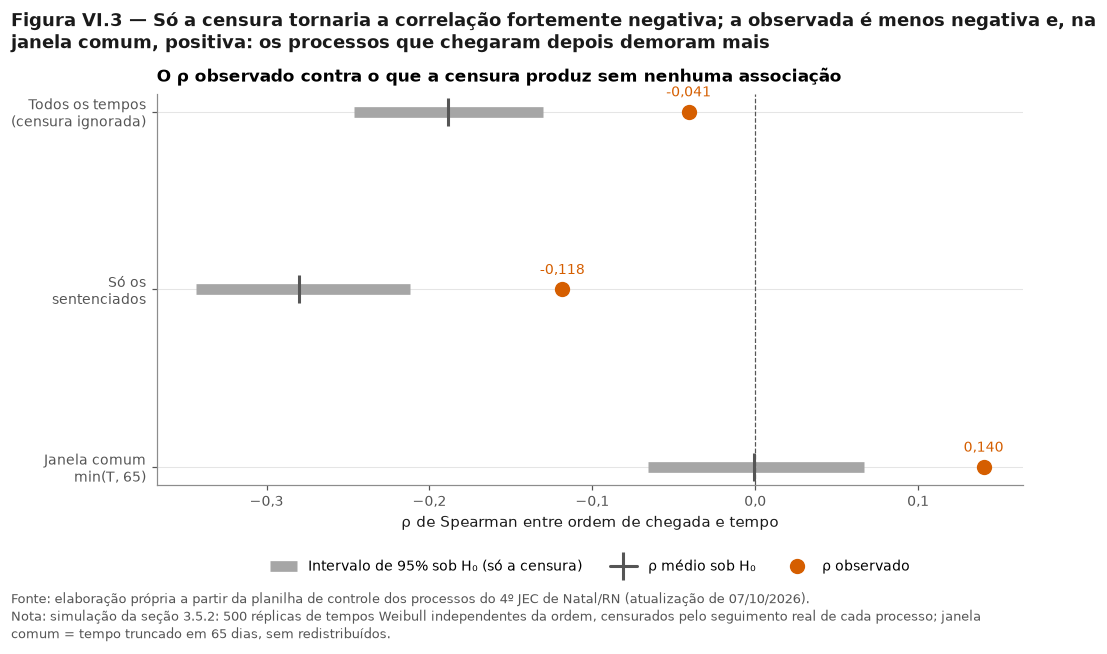

In [42]:
sim_ordem = q6_csv('tst_ordem_simulacao.csv')
if sim_ordem is not None:
    rot_v = {'todos (censura ignorada)': 'Todos os tempos\n(censura ignorada)', 'só encerrados': 'Só os\nsentenciados',
             'min(T, 65)': 'Janela comum\nmin(T, 65)'}
    fig, ax = plt.subplots(figsize=(9.5, 5))
    for i, lin in sim_ordem.reset_index(drop=True).iterrows():
        ax.plot([lin['Percentil 2,5'], lin['Percentil 97,5']], [i, i], color=CINZA, lw=7, solid_capstyle='butt',
                label='Intervalo de 95% sob H₀ (só a censura)' if i == 0 else None)
        ax.plot(lin['ρ médio sob H₀'], i, marker='|', ms=18, color=TINTA_2, mew=2, label='ρ médio sob H₀' if i == 0 else None)
        ax.plot(lin['ρ observado'], i, 'o', ms=9, color=DESTAQUE, label='ρ observado' if i == 0 else None)
        ax.annotate(fmt_br(lin['ρ observado'], 3), (lin['ρ observado'], i), xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=9, color=DESTAQUE)
    ax.axvline(0, color=TINTA_2, lw=0.8, ls='--')
    ax.set_yticks(range(len(sim_ordem)), [rot_v.get(v, v) for v in sim_ordem['Versão']])
    ax.invert_yaxis()
    ax.set_xlabel('ρ de Spearman entre ordem de chegada e tempo')
    ax.set_title('O ρ observado contra o que a censura produz sem nenhuma associação')
    legenda_abaixo(ax, ncol=3)
    figura(fig, 'q_ordem_artefato', 'Só a censura tornaria a correlação fortemente negativa; a observada é menos negativa '
           'e, na janela comum, positiva: os processos que chegaram depois demoram mais', secao='6.6',
           nota='simulação da seção 3.5.2: 500 réplicas de tempos Weibull independentes da ordem, censurados pelo seguimento '
                'real de cada processo; janela comum = tempo truncado em 65 dias, sem redistribuídos.')

**Resposta à questão 2.7.** A figura resolve a aparente contradição entre "há correlação" e "não há correlação" na ordem de chegada. Se os tempos fossem **independentes** da ordem, a censura sozinha produziria um ρ de Spearman em torno de −0,19 quando se usam todos os tempos (intervalo de 95%: −0,25 a −0,13) e de −0,28 quando se usam só os sentenciados (−0,34 a −0,21). Os valores observados (−0,041 e −0,118) são **menos negativos** do que isso e caem **fora** dos intervalos de nulidade. Na janela comum de 65 dias, a única versão do tempo sem censura para todos, o artefato desaparece (ρ médio sob H₀ ≈ 0) e o ρ observado é **positivo** (0,140), acima do intervalo de nulidade (−0,066 a 0,067).

A leitura correta é, portanto, oposta à que a correlação bruta sugere: os processos que chegaram depois **demoraram mais** para ser sentenciados, e o sinal negativo dos dados brutos é produzido pela censura. Isso coincide com os modelos que respeitam a censura (Cox com mês: HR de 0,70 em junho e de 0,58 em julho-agosto contra janeiro; AFT log-normal: cerca de 20% mais tempo por mês de distribuição) e indica **acúmulo de acervo** ao longo do experimento.

Quanto à matriz do professor, a resposta é inequívoca: correlacionar quatro cópias da mesma coluna produz r = 1 por identidade e nada informa. A matriz adequada é de **associação** (V de Cramér entre nominais, η entre nominal e tempo), e a relação de qualquer variável com o tempo deve ser medida num modelo de sobrevivência.

## 6.7 Questão 2.8 — Variáveis de confundimento

**Enunciado.** Refletir sobre possíveis variáveis de confundimento, apresentá-las em quadro com os seus efeitos possíveis e dizer se foram ou não controladas pelo desenho.

**Conceito.** Um **confundidor** é uma variável associada ao mesmo tempo à exposição e ao desfecho, sem estar no caminho causal entre eles; se não for controlado, a diferença observada entre os grupos mistura o efeito do tratamento com o efeito dele. É preciso distingui-lo do **mediador** (a variável pela qual o tratamento age, como a fila da pauta da AC ou a ausência do autor à audiência) e do **modificador de efeito** (a variável que muda o tamanho do efeito, como o perfil da unidade).

**O que o sorteio controla e o que não controla.** A aleatorização individual controla, **em expectativa**, todos os fatores **do processo** anteriores ao sorteio: tipo de ação, valor da causa, número de partes, litigante habitual, presença de advogado. Esse é o grande mérito do desenho, e é por isso que a falta dessas variáveis na planilha não enviesa a comparação entre grupos (embora impeça verificar o equilíbrio e reduza a precisão). O sorteio **não controla** três famílias de fatores:

- os que estão **amarrados ao braço** pelo próprio protocolo: a conciliadora (CEJUSC na presencial, gabinete na remota) é **a mesma para todos os processos de cada braço**, de modo que o "efeito da modalidade" e o "efeito da conciliadora" são indissociáveis (a hipótese H5 do projeto é inestimável);
- os que **agem sobre todos os grupos** de forma possivelmente diferencial e não são cegos: o juiz-pesquisador que sorteia, julga e analisa; a reatividade da equipe (Hawthorne); a contaminação entre grupos (mesmo cartório e mesma equipe);
- os que **variam no tempo** e se combinam com a composição dos grupos: o mês de distribuição (junho com excesso de Presencial e julho de Remota, resíduos ajustados 2,95 e 3,10; seção 3.5.3), que também determina o seguimento e coincide com um acúmulo de acervo (6.6). Este foi **controlado na análise**, por estratificação (log-rank estratificado, Cox com estrato por mês; seções 4.3.4 e 4.5), e a conclusão se manteve.

O quadro a seguir organiza os candidatos, com o efeito provável, a direção do viés e o que o desenho ou a análise fez a respeito.

In [43]:
quadro_conf = pd.DataFrame([
    ['Conciliadora (CEJUSC × gabinete)', 'condutora diferente em cada braço; habilidade e estilo próprios',
     'acordo e tempo do braço refletem a pessoa, não só a modalidade', 'indeterminada (Presencial × Remota)',
     'não: confundida por desenho', 'rodízio das conciliadoras entre modalidades; várias conciliadoras por braço'],
    ['Juiz-pesquisador não cego', 'quem sorteia também pauta, julga e analisa',
     'ritmo de sentença diferente por grupo, consciente ou não', 'indeterminada; os resultados contrariam H1, o que atenua a suspeita',
     'não', 'análise cega ao grupo; desfecho extraído do PJe/DataJud por terceiro'],
    ['Reatividade (Hawthorne)', 'equipe sabe que é observada', 'aceleração geral ou do braço "de interesse"', 'tende a reduzir tempos em todos os grupos',
     'não', 'comparar o 4º JEC antes (2025) e durante (2026) com os outros 13 JECs (6.9)'],
    ['Contaminação entre grupos', 'mesmo cartório, mesma equipe e mesmas práticas nos três ritos',
     'práticas da AC vazam para o Controle', 'para zero (subestima diferenças)', 'não', 'ensaio por conglomerados (unidades sorteadas)'],
    ['Mês de distribuição / acúmulo de acervo', 'composição dos grupos varia por mês; tempo cresce ~20% por mês',
     'grupo com mais entradas tardias parece mais lento', 'contra a Remota (mais casos em julho)',
     'parcialmente (sorteio restrito)', 'estratificação por mês (feita: 4.3.4, 4.5); blocos por mês na replicação'],
    ['Tipo de ação, valor da causa, nº de partes', 'complexidade e chance de acordo variam com o caso',
     'tempo e acordo', 'nenhuma em expectativa', 'sim, em expectativa (sorteio)', 'coletar para verificar o equilíbrio e ganhar precisão'],
    ['Litigante habitual, advogado constituído', 'réus repetidos e assistência técnica', 'acordo, ausência, tempo', 'nenhuma em expectativa',
     'sim, em expectativa; dependência entre processos', 'coletar; erros-padrão por agrupamento'],
    ['Audiência híbrida (adesão)', 'pedido da parte após o sorteio', 'acordo e tempo da AC', 'pequena (28 casos)',
     'sim pela análise ITT', 'ITT principal; "conforme tratado" como sensibilidade (feita: 4.9)'],
    ['Ausência do autor à AC (art. 51, I, Lei 9.099/95)', 'mediador: a AC obrigatória cria a ocasião da extinção',
     'mais extinções sem mérito nos braços com AC', 'é parte do efeito do rito (não é viés)', 'não se aplica (mediador)',
     'registrar comparecimento e motivo da extinção'],
    ['Fila da pauta da AC', 'mediador: a AC acrescenta uma etapa ao rito', 'sentenças de mérito mais tardias', 'é parte do efeito do rito',
     'não se aplica (mediador)', 'registrar data da AC; decompor o tempo em etapas'],
    ['Técnica de conciliação', 'sorteada por audiência', 'acordo na AC', 'nenhuma (sorteio uniforme, p = 0,566)',
     'sim (sorteio)', '—'],
    ['Data da sentença registrada', '18,4% em fim de semana; possível data de lançamento', 'erro de medida do tempo',
     'não diferencial (sem efeito na conclusão, 4.9)', 'não', 'conferir no PJe/DataJud (Parte VIII)'],
    ['Redistribuição por prevenção', 'saída do estudo antes da sentença', 'remove casos do risco', 'nenhuma (igual entre grupos, p = 0,393)',
     'sim, na análise (risco competitivo)', 'triagem de prevenção antes do sorteio'],
], columns=['Variável', 'Mecanismo', 'Efeito provável', 'Direção do viés', 'Controlada pelo desenho?', 'Como controlar'])
tabela(quadro_conf, 'q_confundidores', 'Variáveis de confundimento, mediadores e ameaças: efeito provável e controle pelo desenho',
       secao='6.7', fonte='Elaboração própria a partir do projeto de pesquisa, do texto antagonista (ODT) e das Partes II a IV.')

Variável,Mecanismo,Efeito provável,Direção do viés,Controlada pelo desenho?,Como controlar
Conciliadora (CEJUSC × gabinete),condutora diferente em cada braço; habilidade e estilo próprios,"acordo e tempo do braço refletem a pessoa, não só a modalidade",indeterminada (Presencial × Remota),não: confundida por desenho,rodízio das conciliadoras entre modalidades; várias conciliadoras por braço
Juiz-pesquisador não cego,"quem sorteia também pauta, julga e analisa","ritmo de sentença diferente por grupo, consciente ou não","indeterminada; os resultados contrariam H1, o que atenua a suspeita",não,análise cega ao grupo; desfecho extraído do PJe/DataJud por terceiro
Reatividade (Hawthorne),equipe sabe que é observada,"aceleração geral ou do braço ""de interesse""",tende a reduzir tempos em todos os grupos,não,comparar o 4º JEC antes (2025) e durante (2026) com os outros 13 JECs (6.9)
Contaminação entre grupos,"mesmo cartório, mesma equipe e mesmas práticas nos três ritos",práticas da AC vazam para o Controle,para zero (subestima diferenças),não,ensaio por conglomerados (unidades sorteadas)
Mês de distribuição / acúmulo de acervo,composição dos grupos varia por mês; tempo cresce ~20% por mês,grupo com mais entradas tardias parece mais lento,contra a Remota (mais casos em julho),parcialmente (sorteio restrito),"estratificação por mês (feita: 4.3.4, 4.5); blocos por mês na replicação"
"Tipo de ação, valor da causa, nº de partes",complexidade e chance de acordo variam com o caso,tempo e acordo,nenhuma em expectativa,"sim, em expectativa (sorteio)",coletar para verificar o equilíbrio e ganhar precisão
"Litigante habitual, advogado constituído",réus repetidos e assistência técnica,"acordo, ausência, tempo",nenhuma em expectativa,"sim, em expectativa; dependência entre processos",coletar; erros-padrão por agrupamento
Audiência híbrida (adesão),pedido da parte após o sorteio,acordo e tempo da AC,pequena (28 casos),sim pela análise ITT,"ITT principal; ""conforme tratado"" como sensibilidade (feita: 4.9)"
"Ausência do autor à AC (art. 51, I, Lei 9.099/95)",mediador: a AC obrigatória cria a ocasião da extinção,mais extinções sem mérito nos braços com AC,é parte do efeito do rito (não é viés),não se aplica (mediador),registrar comparecimento e motivo da extinção
Fila da pauta da AC,mediador: a AC acrescenta uma etapa ao rito,sentenças de mérito mais tardias,é parte do efeito do rito,não se aplica (mediador),registrar data da AC; decompor o tempo em etapas


**Resposta à questão 2.8.** O quadro separa três situações que costumam ser confundidas sob o nome de "confundimento":

1. **confundidores neutralizados pelo sorteio** (tipo de ação, valor, partes, litigante habitual, advogado): não enviesam a comparação entre grupos, embora a sua ausência na planilha impeça verificar o equilíbrio e reduza a precisão;
2. **confundidores que o sorteio não alcança** porque estão amarrados ao braço ou agem sobre todos os grupos sem cegamento (conciliadora, juiz-pesquisador, reatividade, contaminação): não foram controlados pelo desenho e só podem ser controlados numa replicação (rodízio, cegamento, várias unidades). A conciliadora é o mais grave: torna a comparação Presencial × Remota uma comparação entre **duas pessoas** tanto quanto entre duas modalidades. A contaminação, ao contrário, tende a **reduzir** as diferenças, o que torna mais robustos os efeitos encontrados contra o Controle;
3. **mediadores** (fila da pauta, ausência do autor à AC): não são viés, são o **caminho** pelo qual o rito age, e explicam o resultado. Os dados são compatíveis com o mecanismo da ausência: as extinções sem mérito ocorridas **após 30 dias** de tramitação, período em que a AC costuma ocorrer, somam 26 no Controle, 45 na Presencial e 48 na Remota, enquanto as extinções da primeira semana não mostram excesso consistente (39, 48 e 34). A planilha, porém, não registra o motivo da extinção, e a confirmação depende do PJe.

O mês de distribuição é o único confundidor de calendário **controlado na análise**: o log-rank estratificado por mês (p = 0,045) e o Cox com estrato por mês (HR da Remota 0,80; IC 0,67–0,96) mantêm a conclusão.

## 6.8 Questão 2.9 — Outras variáveis quantitativas em escala intervalar

**Enunciado.** Seria possível extrair outra variável quantitativa intervalar (discreta ou contínua), como o número de autores e réus ou o número de atos da serventia e do juiz, com datas e durações, para correlacionar com `duracao_proc`? Que correlação e que teste usar?

**Sim, e elas fariam falta.** Nenhuma variável quantitativa além do tempo existe na planilha (a Parte V é limitada por isso). Do PJe e, em parte, do DataJud podem ser extraídas variáveis de dois tipos, que precisam ser separadas porque respondem a perguntas diferentes:

- **basais (anteriores ao sorteio)**: número de autores e de réus, valor da causa, número de pedidos, presença de pessoa jurídica no polo passivo; servem como **covariáveis** (verificar o equilíbrio do sorteio e ganhar precisão nos modelos);
- **de processo (posteriores ao sorteio)**: número de atos da serventia e do juiz, número de petições, número de remarcações da AC, dias até a citação, dias até a AC, dias da AC à conclusão e da conclusão à sentença; são **mediadores** e componentes do próprio tempo. O número de atos, em particular, cresce **mecanicamente** com a duração (processo mais longo acumula mais atos): uma correlação alta entre eles nada diz sobre causa e, se usado como preditor da duração, produz viés de tempo imortal. Para esse tipo de variável, a medida útil é a **taxa** (atos por 30 dias) ou a **decomposição do tempo em etapas**.

Rigorosamente, contagens e valores monetários estão em **escala de razão** (zero absoluto), que contém as propriedades da intervalar; o que importa para a escolha da medida é que são **quantitativas**, em geral **assimétricas** e, nas contagens, com **muitos empates**.

**Que correlação e que teste.** Para duas variáveis quantitativas **sem censura**:

- **Pearson** (r) mede associação **linear** e, para inferência, supõe normalidade bivariada ou n grande; teste de H₀: ρ = 0 por t = r√(n − 2)/√(1 − r²), com n − 2 graus de liberdade. É pouco indicado aqui: tempos e contagens são assimétricos e a relação raramente é linear;
- **Spearman** (ρ_s) mede associação **monotônica** sobre os postos; teste pela mesma aproximação t ou, em amostras pequenas, pela distribuição exata ou por permutação (SIEGEL; CASTELLAN, 2006);
- **Kendall** (τ_b) é preferível com **muitos empates** (contagens pequenas, como número de réus) e tem interpretação direta (diferença entre as probabilidades de pares concordantes e discordantes); teste por aproximação normal ou permutação.

**Com censura**, nenhuma dessas correlações vale para o tempo (6.6). A medida adequada é a **razão de riscos por unidade da covariável** num modelo de Cox (testes de Wald, razão de verossimilhanças ou escore; COLOSIMO; GIOLO, 2006, cap. 5), a **razão de tempos** num AFT, ou o **índice de concordância C de Harrell**, que generaliza o τ de Kendall a dados censurados. A forma funcional da covariável contínua se verifica pelos **resíduos martingal** (seção 4.5.4).

In [44]:
quadro_vars = pd.DataFrame([
    ['Número de autores; número de réus', 'razão (contagem discreta)', 'PJe (não está na API pública)', 'basal',
     'Kendall τ_b (empates); com censura: Cox (HR por parte a mais)', 'equilíbrio entre grupos; covariável'],
    ['Valor da causa (R$)', 'razão (contínua, assimétrica)', 'PJe', 'basal', 'Spearman; com censura: Cox com log(valor)',
     'transformar em log; teto de 40 salários mínimos nos JECs'],
    ['Pessoa jurídica / litigante habitual no polo passivo', 'nominal (não quantitativa)', 'PJe', 'basal',
     'V de Cramér; Cox com indicadora', 'agrupamento por réu'],
    ['Dias da distribuição até a citação', 'razão (contínua)', 'PJe; DataJud (movimentos)', 'pós-sorteio (etapa)',
     'decomposição do tempo; Cox por etapa', 'censura em cada etapa'],
    ['Dias da distribuição até a AC (pauta)', 'razão (contínua)', 'PJe; DataJud', 'pós-sorteio (mediador)',
     'decomposição do tempo; covariável dependente do tempo', 'só existe nos braços com AC'],
    ['Dias da AC (ou da contestação) até a sentença', 'razão (contínua)', 'PJe; DataJud', 'pós-sorteio (etapa)',
     'KM/Cox a partir da AC', 'origem do relógio na AC'],
    ['Número de atos da serventia e do juiz', 'razão (contagem)', 'PJe; DataJud (movimentos)', 'pós-sorteio',
     'taxa por 30 dias × grupo (Mann-Whitney/Poisson com offset)', 'cresce mecanicamente com a duração'],
    ['Número de remarcações da AC', 'razão (contagem)', 'PJe', 'pós-sorteio', 'Kendall τ_b; Poisson/binomial negativa',
     'mede atrito do rito'],
], columns=['Variável', 'Escala', 'Fonte', 'Momento', 'Medida e teste adequados', 'Cuidado'])
tabela(quadro_vars, 'q_vars_quantitativas', 'Variáveis quantitativas que poderiam ser extraídas e a medida de associação adequada a cada uma',
       secao='6.8', fonte='Elaboração própria; SIEGEL; CASTELLAN (2006); COLOSIMO; GIOLO (2006).')

Variável,Escala,Fonte,Momento,Medida e teste adequados,Cuidado
Número de autores; número de réus,razão (contagem discreta),PJe (não está na API pública),basal,Kendall τ_b (empates); com censura: Cox (HR por parte a mais),equilíbrio entre grupos; covariável
Valor da causa (R$),"razão (contínua, assimétrica)",PJe,basal,Spearman; com censura: Cox com log(valor),transformar em log; teto de 40 salários mínimos nos JECs
Pessoa jurídica / litigante habitual no polo passivo,nominal (não quantitativa),PJe,basal,V de Cramér; Cox com indicadora,agrupamento por réu
Dias da distribuição até a citação,razão (contínua),PJe; DataJud (movimentos),pós-sorteio (etapa),decomposição do tempo; Cox por etapa,censura em cada etapa
Dias da distribuição até a AC (pauta),razão (contínua),PJe; DataJud,pós-sorteio (mediador),decomposição do tempo; covariável dependente do tempo,só existe nos braços com AC
Dias da AC (ou da contestação) até a sentença,razão (contínua),PJe; DataJud,pós-sorteio (etapa),KM/Cox a partir da AC,origem do relógio na AC
Número de atos da serventia e do juiz,razão (contagem),PJe; DataJud (movimentos),pós-sorteio,taxa por 30 dias × grupo (Mann-Whitney/Poisson com offset),cresce mecanicamente com a duração
Número de remarcações da AC,razão (contagem),PJe,pós-sorteio,Kendall τ_b; Poisson/binomial negativa,mede atrito do rito


**Resposta à questão 2.9.** O quadro mostra que a resposta depende de duas perguntas prévias: **quando** a variável é medida (antes ou depois do sorteio) e **se o tempo está censurado**. Variáveis basais (número de partes, valor da causa) são covariáveis legítimas e ajudariam a verificar o sorteio e a ganhar precisão; variáveis de processo (número de atos, remarcações, dias até a AC) são componentes ou mediadores do tempo, e uma correlação delas com a duração é em boa parte mecânica.

Quanto à medida: a correlação de **Pearson** só é apropriada para relação linear com distribuição aproximadamente normal, o que contagens e tempos raramente satisfazem; **Spearman** (relações monotônicas) e **Kendall τ_b** (com muitos empates, típico de contagens pequenas como o número de réus) são as escolhas naturais para dados completos, com teste t para ρ = 0 ou por permutação. Com 24,5% dos tempos censurados, porém, nenhuma correlação simples é válida (6.6): a covariável quantitativa entra num **modelo de Cox** (razão de riscos por unidade, testes de Wald, escore ou razão de verossimilhanças) ou num AFT (razão de tempos), e o C de Harrell faz o papel de um τ de Kendall para dados censurados.

## 6.9 Questão 2.10 — Validade interna e externa; generalização aos 14 JECs

**Enunciado.** Considerando a validade interna e a externa, seria possível generalizar os resultados para toda a população dos 14 JECs de Natal no mesmo período?

**Validade interna: razoável para o efeito do rito no 4º JEC.** A validade interna pergunta se a diferença observada entre os grupos pode ser atribuída ao tratamento. Aqui, os pontos fortes são reais: alocação por sorteio individual, grupos contemporâneos e de mesmo tamanho, equilíbrio das variáveis basais disponíveis (6.2), análise por intenção de tratar, e tratamento correto da censura e dos riscos competitivos (Parte IV). As conclusões principais resistiram a doze cenários de sensibilidade (seção 4.9). As ameaças que permanecem são as do quadro de 6.7: a conciliadora confundida com a modalidade (o que compromete só a comparação Presencial × Remota, não a comparação de cada braço com o Controle), o juiz-pesquisador não cego, a reatividade e a contaminação; e o seguimento curto (mínimo de 65 dias), que deixa um quarto dos processos sem desfecho.

**Validade externa: não há base estatística para generalizar aos 14 JECs.** A validade externa pergunta se o efeito estimado vale para outras unidades, pessoas e momentos. O estudo tem **uma só unidade**, escolhida por conveniência: no nível em que a política seria adotada (a serventia), N = 1. Há aqui uma distinção importante. Como a distribuição entre os 14 JECs é aleatória e alternada pelo PJe (CPC, art. 285), os **processos** que chegam ao 4º JEC são, em expectativa, parecidos com os que chegam aos demais; o que **não** é representativo é a **unidade**: o juiz (que é o pesquisador), as duas conciliadoras, o cartório, a pauta e a cultura conciliatória. Se o efeito da AC obrigatória depende dessas características (e é plausível que dependa: o acordo depende da conciliadora; o tempo, da pauta e do gabinete), o efeito do 4º JEC não se transporta automaticamente aos demais. A premissa de que os 14 JECs são "conglomerados homogêneos" é uma **hipótese não testada**, e mesmo uma homogeneidade de perfil das ações não garantiria homogeneidade de efeito. A generalização possível é **analítica** (o mecanismo encontrado, como a extinção por ausência do autor à AC obrigatória, deve operar em outras unidades), não estatística.

**O que se pode fazer com os dados disponíveis (recorte adotado).** O DataJud (6.4; Parte VIII) permite duas comparações **observacionais** no nível da unidade, que medem o **efeito do experimento sobre o 4º JEC**, e não o efeito do rito (que só o sorteio interno identifica):

1. **4º JEC antes × durante**: processos distribuídos em 2025 (antes do experimento) × 2026 (durante), com o mesmo tratamento da censura;
2. **4º JEC × os outros 13 JECs de Natal**, no mesmo período: um desenho de **diferenças em diferenças** (antes/durante × 4º JEC/demais) que separa a mudança do 4º JEC da tendência comum da capital, e que é a melhor forma disponível de avaliar a reatividade e o acúmulo de acervo observado (6.6).

**Outra comarca ou outro estado** ficam como **trabalhos futuros**: ali a validade externa exige **replicar o experimento** (sortear os ritos em outras unidades), e não comparar tempos observacionalmente, porque unidades diferentes diferem em tudo o que o sorteio interno controlava.

In [45]:
quadro_val = pd.DataFrame([
    ['Alocação por sorteio individual e controle contemporâneo', 'interna', 'favorece', 'efeito causal do rito no 4º JEC (ITT)'],
    ['Censura e riscos competitivos tratados (Parte IV)', 'interna / estatística', 'favorece', 'estimativas não enviesadas pelo seguimento'],
    ['Conciliadora confundida com a modalidade', 'interna', 'ameaça', 'Presencial × Remota não separa modalidade de pessoa'],
    ['Juiz-pesquisador não cego; reatividade (Hawthorne)', 'interna / constructo', 'ameaça', 'possível ritmo diferencial; não verificável'],
    ['Contaminação entre grupos', 'interna', 'ameaça', 'tende a subestimar diferenças'],
    ['Seguimento curto (65 a 279 dias) e 24,5% sem desfecho', 'estatística', 'ameaça (tratada)', 'cauda da distribuição não estimável; usar RMST'],
    ['Unidade única, escolhida por conveniência (N = 1)', 'externa', 'ameaça grave', 'sem inferência estatística para os 14 JECs'],
    ['Distribuição aleatória entre os 14 JECs (art. 285 do CPC)', 'externa', 'favorece parcialmente', 'perfil dos processos semelhante em expectativa'],
    ['Efeito dependente de juiz, conciliadoras, pauta e cultura', 'externa', 'ameaça', 'efeito pode não se transportar a outra unidade'],
    ['Período de 7 meses de 2026', 'externa (tempo)', 'ameaça', 'sazonalidade e acúmulo de acervo específicos'],
], columns=['Aspecto', 'Tipo de validade', 'Efeito', 'Consequência'])
tabela(quadro_val, 'q_validade', 'Validade interna razoável no 4º JEC; validade externa sem base estatística para os 14 JECs',
       secao='6.9', fonte='Elaboração própria a partir das Partes II a V e do texto antagonista (ODT).')

quadro_cmp = pd.DataFrame([
    ['Sorteio interno (este notebook)', 'efeito do rito sobre o tempo e o acordo no 4º JEC', 'KM, log-rank, Cox, RMST, riscos competitivos',
     'planilha (938)', 'feito (Partes III a V)'],
    ['4º JEC antes (2025) × durante (2026)', 'o experimento mudou o tempo da unidade?', 'KM/Cox por período (série interrompida)',
     'DataJud', 'recorte adotado (Parte VIII)'],
    ['4º JEC × outros 13 JECs de Natal, antes e durante', 'efeito do experimento além da tendência da capital',
     'diferenças em diferenças com Cox estratificado por juizado', 'DataJud', 'recorte adotado (Parte VIII)'],
    ['Outra comarca ou estado', 'o efeito do rito se transporta?', 'replicação do ECA (multicêntrico, por conglomerados)',
     'nova coleta primária', 'trabalho futuro'],
], columns=['Comparação', 'Pergunta', 'Método', 'Dados', 'Situação'])
tabela(quadro_cmp, 'q_comparacoes', 'Comparações possíveis: só o sorteio interno identifica o efeito do rito',
       secao='6.9', fonte='Elaboração própria.')

Aspecto,Tipo de validade,Efeito,Consequência
Alocação por sorteio individual e controle contemporâneo,interna,favorece,efeito causal do rito no 4º JEC (ITT)
Censura e riscos competitivos tratados (Parte IV),interna / estatística,favorece,estimativas não enviesadas pelo seguimento
Conciliadora confundida com a modalidade,interna,ameaça,Presencial × Remota não separa modalidade de pessoa
Juiz-pesquisador não cego; reatividade (Hawthorne),interna / constructo,ameaça,possível ritmo diferencial; não verificável
Contaminação entre grupos,interna,ameaça,tende a subestimar diferenças
"Seguimento curto (65 a 279 dias) e 24,5% sem desfecho",estatística,ameaça (tratada),cauda da distribuição não estimável; usar RMST
"Unidade única, escolhida por conveniência (N = 1)",externa,ameaça grave,sem inferência estatística para os 14 JECs
Distribuição aleatória entre os 14 JECs (art. 285 do CPC),externa,favorece parcialmente,perfil dos processos semelhante em expectativa
"Efeito dependente de juiz, conciliadoras, pauta e cultura",externa,ameaça,efeito pode não se transportar a outra unidade
Período de 7 meses de 2026,externa (tempo),ameaça,sazonalidade e acúmulo de acervo específicos


Comparação,Pergunta,Método,Dados,Situação
Sorteio interno (este notebook),efeito do rito sobre o tempo e o acordo no 4º JEC,"KM, log-rank, Cox, RMST, riscos competitivos",planilha (938),feito (Partes III a V)
4º JEC antes (2025) × durante (2026),o experimento mudou o tempo da unidade?,KM/Cox por período (série interrompida),DataJud,recorte adotado (Parte VIII)
"4º JEC × outros 13 JECs de Natal, antes e durante",efeito do experimento além da tendência da capital,diferenças em diferenças com Cox estratificado por juizado,DataJud,recorte adotado (Parte VIII)
Outra comarca ou estado,o efeito do rito se transporta?,"replicação do ECA (multicêntrico, por conglomerados)",nova coleta primária,trabalho futuro


**Resposta à questão 2.10.** **Não é possível generalizar estatisticamente** os resultados aos 14 JECs de Natal. O primeiro quadro mostra a assimetria: os pontos que favorecem a validade **interna** são fortes (sorteio, controle contemporâneo, tratamento da censura, robustez em doze cenários de sensibilidade), enquanto a validade **externa** repousa numa única unidade escolhida por conveniência. A distribuição aleatória entre os JECs pelo PJe torna o perfil das **ações** do 4º JEC semelhante, em expectativa, ao das demais unidades; não torna semelhantes o juiz, as conciliadoras, a pauta e o cartório, que são justamente os fatores pelos quais a AC obrigatória age.

O segundo quadro organiza o que se pode fazer. Só o sorteio interno identifica o **efeito do rito**. As duas comparações com o DataJud adotadas como recorte (4º JEC antes × durante e 4º JEC × os outros 13 JECs) respondem a outra pergunta, o **efeito do experimento sobre a unidade**, úteis para avaliar a reatividade e o acúmulo de acervo e para situar os tempos do 4º JEC na capital. A validade externa propriamente dita, para outras comarcas ou estados, exige **replicação** do experimento, não comparação observacional.

## 6.10 Questão 2.11 — Os testes de significância do notebook do professor foram adequados?

**Enunciado.** Todos os testes de significância contra a hipótese nula (TSHN) do notebook foram adequados? Que outros testes poderiam ser aplicados (BECKER, 2015; BARBETTA; REIS; BORNIA, 2020; SIEGEL; CASTELLAN, 2006)?

**Resposta.** **Não.** Um teste é adequado quando (i) a hipótese nula responde a uma pergunta substantiva, (ii) os pressupostos valem para os dados e (iii) o resultado vem acompanhado de tamanho de efeito, intervalo de confiança e controle de multiplicidade. O notebook do professor falha no primeiro critério em quatro testes (tautológicos ou sem sentido), no segundo em quase todos (sobretudo pela **censura**) e no terceiro em todos (E27). O quadro a seguir avalia cada teste; a Parte III reproduziu os testes problemáticos na base primária (seção 3.6.1) e a Parte IV aplicou os métodos adequados a dados censurados.

O caso exemplar é o **Kruskal-Wallis** da duração por grupo (H = 1,48; p = 0,478 nas 943 linhas; p = 0,559 na base primária). Ele trata os 206 processos ainda ativos como se tivessem terminado no dia do corte, e os ativos estão concentrados nos braços com AC (14,7% no Controle, 23,6% na Presencial, 27,7% na Remota). O teste "não vê diferença" porque **trunca justamente a cauda longa dos grupos tratados**. A figura abaixo mostra como a mediana de cada grupo depende do tratamento da censura: as medianas ingênuas são praticamente iguais, e as de Kaplan-Meier revelam que os braços com AC levam cerca de duas semanas a mais até a sentença, diferença confirmada pelo log-rank (seção 4.3.1). O único teste que o professor anunciou como "imprescindível", o Kaplan-Meier com log-rank, **nunca rodou**, por um erro de importação silenciado (E1).

**Outros testes aplicáveis**, segundo as referências indicadas:

- **para proporções e tabelas** (BARBETTA; REIS; BORNIA, 2020; SIEGEL; CASTELLAN, 2006): exato de Fisher e Fisher-Freeman-Halton (acordo na AC, com 17 eventos); qui-quadrado de **aderência** (equilíbrio do sorteio dos grupos e das técnicas, seções 2.5.1 e 2.5.3); binomial exato contra a taxa histórica de 13,3% (2.5.2); **Cochran-Mantel-Haenszel** para o acordo estratificado por mês (3.6.4); intervalos de Wilson e de Newcombe;
- **não paramétricos de posição e de forma** (SIEGEL; CASTELLAN, 2006): teste da mediana de Mood; Dunn com Holm após o Kruskal-Wallis; Kolmogorov-Smirnov para duas amostras; Jonckheere-Terpstra para tendência ordenada ao longo dos meses; **teste de sequências (corridas)** para a aleatoriedade do sorteio (3.5.1); Spearman e Kendall para a ordem de chegada (3.5.2);
- **para tempos censurados**: log-rank e a família ponderada (Wilcoxon-Gehan, Tarone-Ware, Peto-Prentice, Fleming-Harrington), log-rank estratificado, testes em pontos fixos do tempo, diferença de RMST, teste de Grambsch-Therneau para riscos proporcionais e teste tipo Gray para as funções de incidência acumulada (Parte IV);
- **inferência e decisão** (BECKER, 2015): intervalos de confiança como forma principal de relato, correção de **Holm** e controle da **FDR** (seção 3.7), **análise de poder** e **testes de equivalência** (TOST), indispensáveis para sustentar a alegação de "não há diferença" que o resumo expandido faz sem teste algum;
- **não se aplicam**: McNemar, Wilcoxon pareado, Friedman e Q de Cochran, porque os grupos são independentes (6.2).

In [46]:
quadro_tshn = pd.DataFrame([
    ['Kruskal-Wallis duração × grupo (+ MW post-hoc)', 'H = 1,48; p = 0,478', 'não', 'censurados como completos; "Decisão" como sentença; sem correção (E14, E17)',
     'KM + log-rank; Cox; RMST', 'log-rank χ² = 7,52; p = 0,023; HR Remota 0,81 (0,67–0,97)', '3.4.6; 4.3; 4.5'],
    ['Mann-Whitney Encerrado × Ativo', 'p = 3,2 × 10⁻²⁴', 'não', 'tautológico: ativos têm, por construção, seguimento ≥ 65 dias (E18)',
     'remover', '—', '3.6.1'],
    ['χ² grupo × status', 'p = 0,00015', 'não', 'estar ativo depende do mês de entrada e do seguimento (E19)',
     'situação em horizonte comum (65º dia); KM', 'χ²(8) = 59,19; p < 0,001; V = 0,178', '3.2.5'],
    ['χ² grupo × acordo na AC', 'p = 0,0074', 'não', 'zero estrutural no Controle; esperadas ≈ 5 (E20)',
     'Fisher Presencial × Remota entre AC realizadas', '5,1% × 4,6%; p = 1,000; OR 1,11 (0,37–3,38)', '3.3.1'],
    ['χ² tipo de sentença × grupo', 'p = 2,0 × 10⁻⁶', 'em parte', 'ideia correta, mas inclui "Decisão"; sem resíduos, V nem pares (E21)',
     'χ² sem Decisão, resíduos ajustados, V, Fisher par a par com Holm', 'χ²(4) = 34,34; V = 0,156; sem mérito OR 2,09 e 1,92', '3.2'],
    ['Matriz de Spearman das 4 durações', 'r = 1', 'não', 'quatro cópias da mesma variável (E6, E16)', 'matriz de associação (V, η)', '—', '2.6.4'],
    ['Shapiro-Wilk e D\'Agostino (subamostra de 500)', 'p = 2,6 × 10⁻⁸ / 0,213', 'não', 'subamostra arbitrária; variável censurada; a posteriori (E22)',
     'normalidade por grupo dos sentenciados; diagnóstico de modelos', '17 de 20 testes rejeitam H₀', '2.3'],
    ['z de proporção (p₀ = 0,5) de encerrados', 'z = 17,1', 'não', 'H₀ sem sentido substantivo; depende da data de corte (E23)', 'remover', '—', '3.6.1'],
    ['Mann-Whitney com × sem acordo na AC', 'p = 0,456', 'não', '"sem acordo" inclui o Controle e os ativos (E24)',
     'restringir às AC realizadas; riscos competitivos', 'Md 63 × 104 dias; Cliff d = −0,61 (condicional)', '3.4.6; 4.7'],
    ['Ajuste MLE de distribuições', 'Weibull melhor AIC', 'não', 'censura ignorada; loc livre; zeros descartados (E25)',
     'ajuste com censura; gama generalizada e exponencial por partes', 'risco não monótono; exponencial por partes', '2.4'],
    ['OLS duração ~ grupo; Logit evento ~ grupo', 'p = 0,588; p < 0,001', 'não', 'censura; o evento depende do seguimento (E26)',
     'Cox/AFT; logit em horizonte fixo', 'razão de tempos Weibull Remota 1,21 (1,00–1,45)', '4.5; 4.6; 5.1; 5.2'],
    ['Kaplan-Meier + log-rank', 'não executado', 'adequado, mas não rodou', 'erro de importação silenciado (E1)',
     'corrigir a importação', 'medianas 81 / 96 / 95 dias', '4.2; 4.3'],
], columns=['Teste do professor', 'Resultado original', 'Adequado?', 'Por quê (código)', 'Alternativa', 'Resultado com a alternativa', 'Seção'])
tabela(quadro_tshn, 'q_testes_professor', 'Avaliação dos testes do notebook do professor: o que muda com o teste adequado',
       secao='6.10', fonte='Elaboração própria; resultados originais do notebook do professor (docs/r2_notebook_professor.md) e das Partes II a V.')

Teste do professor,Resultado original,Adequado?,Por quê (código),Alternativa,Resultado com a alternativa,Seção
Kruskal-Wallis duração × grupo (+ MW post-hoc),"H = 1,48; p = 0,478",não,"censurados como completos; ""Decisão"" como sentença; sem correção (E14, E17)",KM + log-rank; Cox; RMST,"log-rank χ² = 7,52; p = 0,023; HR Remota 0,81 (0,67–0,97)",3.4.6; 4.3; 4.5
Mann-Whitney Encerrado × Ativo,"p = 3,2 × 10⁻²⁴",não,"tautológico: ativos têm, por construção, seguimento ≥ 65 dias (E18)",remover,—,3.6.1
χ² grupo × status,"p = 0,00015",não,estar ativo depende do mês de entrada e do seguimento (E19),situação em horizonte comum (65º dia); KM,"χ²(8) = 59,19; p < 0,001; V = 0,178",3.2.5
χ² grupo × acordo na AC,"p = 0,0074",não,zero estrutural no Controle; esperadas ≈ 5 (E20),Fisher Presencial × Remota entre AC realizadas,"5,1% × 4,6%; p = 1,000; OR 1,11 (0,37–3,38)",3.3.1
χ² tipo de sentença × grupo,"p = 2,0 × 10⁻⁶",em parte,"ideia correta, mas inclui ""Decisão""; sem resíduos, V nem pares (E21)","χ² sem Decisão, resíduos ajustados, V, Fisher par a par com Holm","χ²(4) = 34,34; V = 0,156; sem mérito OR 2,09 e 1,92",3.2
Matriz de Spearman das 4 durações,r = 1,não,"quatro cópias da mesma variável (E6, E16)","matriz de associação (V, η)",—,2.6.4
Shapiro-Wilk e D'Agostino (subamostra de 500),"p = 2,6 × 10⁻⁸ / 0,213",não,subamostra arbitrária; variável censurada; a posteriori (E22),normalidade por grupo dos sentenciados; diagnóstico de modelos,17 de 20 testes rejeitam H₀,2.3
"z de proporção (p₀ = 0,5) de encerrados","z = 17,1",não,H₀ sem sentido substantivo; depende da data de corte (E23),remover,—,3.6.1
Mann-Whitney com × sem acordo na AC,"p = 0,456",não,"""sem acordo"" inclui o Controle e os ativos (E24)",restringir às AC realizadas; riscos competitivos,"Md 63 × 104 dias; Cliff d = −0,61 (condicional)",3.4.6; 4.7
Ajuste MLE de distribuições,Weibull melhor AIC,não,censura ignorada; loc livre; zeros descartados (E25),ajuste com censura; gama generalizada e exponencial por partes,risco não monótono; exponencial por partes,2.4


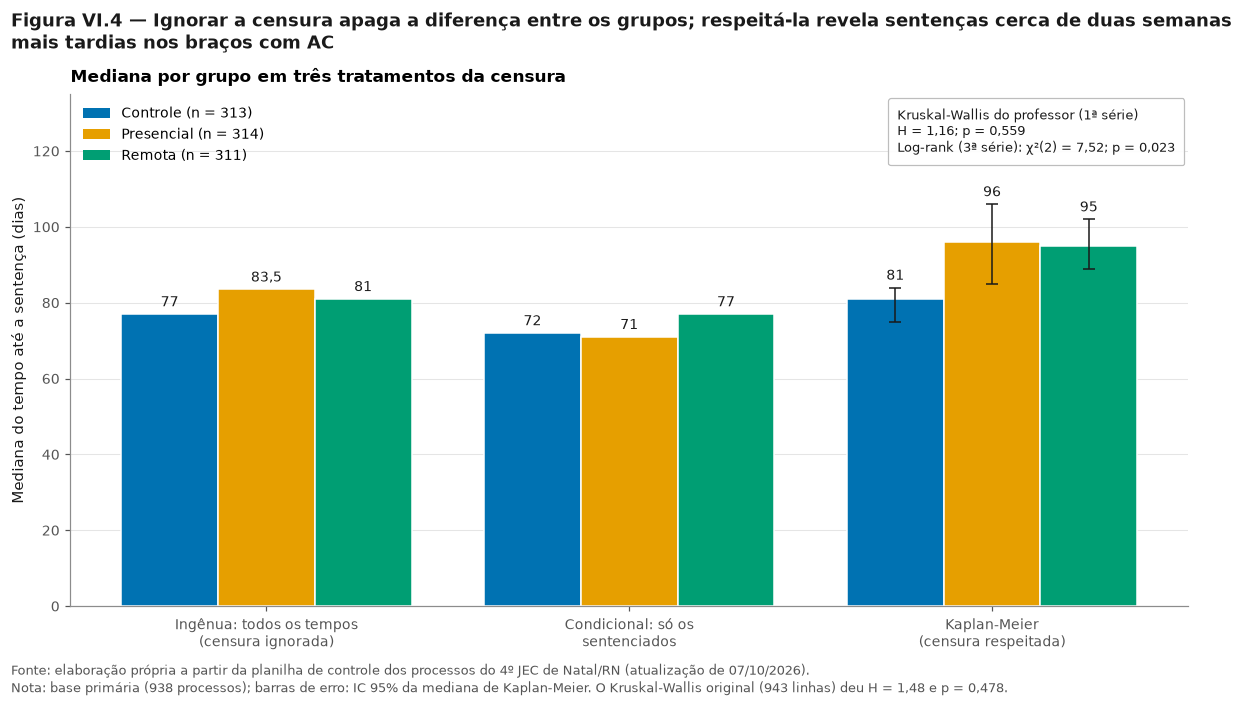

In [47]:
# ---- contraste de apoio: a mediana por grupo depende do tratamento da censura
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import median_survival_times
med = pd.DataFrame(index=ORDEM_GRUPO, dtype=float)
med_ic = {}
for g in ORDEM_GRUPO:
    s = q6[q6['grupo'] == g]
    med.loc[g, 'Ingênua: todos os tempos\n(censura ignorada)'] = s['tempo'].astype(float).median()
    med.loc[g, 'Condicional: só os\nsentenciados'] = s.loc[s['evento'].astype(int) == 1, 'tempo'].astype(float).median()
    kmf = KaplanMeierFitter().fit(s['tempo'].astype(float), s['evento'].astype(int))
    med.loc[g, 'Kaplan-Meier\n(censura respeitada)'] = kmf.median_survival_time_
    med_ic[g] = median_survival_times(kmf.confidence_interval_).to_numpy().ravel()
kw = stats.kruskal(*[q6.loc[q6['grupo'] == g, 'tempo'].astype(float) for g in ORDEM_GRUPO])
lr = multivariate_logrank_test(q6['tempo'].astype(float), q6['grupo'].astype(str), q6['evento'].astype(int))
tab_med = med.T
fig, ax = plt.subplots(figsize=(11, 5.6))
barras_agrupadas(ax, tab_med, cores=CORES_GRUPO, rotular=False, ylabel='Mediana do tempo até a sentença (dias)', legenda=False,
                 quebrar=40)
w_ = 0.8 / 3
for j, g in enumerate(ORDEM_GRUPO):
    for i in range(3):
        xi, vi = i + (j - 1) * w_, tab_med.iloc[i][g]
        topo_ = vi
        if i == 2:
            ax.errorbar(xi, vi, yerr=[[vi - med_ic[g][0]], [med_ic[g][1] - vi]], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
            topo_ = med_ic[g][1]
        ax.annotate(fmt_br(vi, 0 if float(vi).is_integer() else 1), (xi, topo_), xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, color=TINTA)
ax.set_ylim(0, 135)
ax.legend(handles=[mpl.patches.Patch(color=CORES_GRUPO[g], label=rotulo_grupo(g, com_n=True)) for g in ORDEM_GRUPO],
          loc='upper left', frameon=False)
anotar_teste(ax, texto_teste('Kruskal-Wallis do professor (1ª série)', f'H = {fmt_br(kw.statistic, 2)}', kw.pvalue,
                             extra=f'Log-rank (3ª série): χ²(2) = {fmt_br(lr.test_statistic, 2)}; p = {fmt_p(lr.p_value)}'),
             loc='upper right')
ax.set_title('Mediana por grupo em três tratamentos da censura')
figura(fig, 'q_censura_conclusao', 'Ignorar a censura apaga a diferença entre os grupos; respeitá-la revela sentenças '
       'cerca de duas semanas mais tardias nos braços com AC', secao='6.10',
       nota=f'base primária ({len(q6)} processos); barras de erro: IC 95% da mediana de Kaplan-Meier. O Kruskal-Wallis '
            'original (943 linhas) deu H = 1,48 e p = 0,478.')

**Resposta à questão 2.11.** Dos doze procedimentos do quadro, só um era adequado em si, o Kaplan-Meier com log-rank, e foi justamente o que não rodou (E1). O χ² do tipo de sentença tinha a ideia certa, mas precisou ser refeito. Os demais eram tautológicos (Mann-Whitney Encerrado × Ativo, matriz de r = 1), sem sentido substantivo (z com p₀ = 0,5) ou inválidos sob censura (Kruskal-Wallis, OLS, ajuste MLE, χ² de status).

A figura mostra por que isso importa. Com a censura ignorada, as medianas são 77, 83,5 e 81 dias e o Kruskal-Wallis não vê diferença (H = 1,16; p = 0,559 na base primária; p = 0,478 nas 943 linhas do professor). Restrito aos sentenciados, o quadro fica ainda mais "igual" (72, 71 e 77 dias). Com a censura respeitada, as medianas de Kaplan-Meier são 81, 96 e 95 dias, com intervalos de confiança que mal se tocam entre o Controle e os braços com AC, e o log-rank rejeita a igualdade (χ²(2) = 7,52; p = 0,023). O efeito existia; o teste escolhido é que o tornava invisível, porque os processos ainda ativos, mais longos e concentrados nos braços com AC, entravam como se tivessem terminado no dia do corte.

A lição para o TSHN é dupla: o teste deve corresponder à **estrutura dos dados** (censura, zeros estruturais, independência) e à **pergunta** (uma comparação de tempos censurados não é uma comparação de posições), e deve ser relatado com tamanho de efeito, intervalo e controle de multiplicidade. A alegação de "não diferença" do resumo expandido exigiria, ainda, um teste de equivalência e uma análise de poder (7.4.3).

## 6.11 Questão 2.12 — Avaliação geral da pesquisa e sugestões de validade

**Enunciado.** Concluir com uma avaliação geral da pesquisa empírica com levantamento de dados primários fidedignos, em especial do delineamento da coleta, com sugestões para conferir maior validade interna e externa a uma eventual replicação.

**Avaliação.** A pesquisa tem um mérito raro na pesquisa empírica em Direito no Brasil: é um **experimento de verdade**, com sorteio individual, controle contemporâneo e dados primários coletados diariamente na própria unidade, sobre uma questão de política judiciária relevante (a obrigatoriedade da AC inaugural nos JECs). Os dados são, no essencial, **fidedignos**: o dígito verificador do número CNJ confere em 100% dos casos, nenhuma sentença precede a distribuição, e a coerência entre acordo e tipo de sentença é perfeita (seção 1.14). Os problemas não estão na honestidade do registro, mas no **delineamento da coleta**, que foi pensado para tabelas dinâmicas de acompanhamento e não para análise estatística:

- a **variável-alvo foi mal definida** na própria planilha (duração dos ativos até `TODAY()`, "Decisão" como sentença), o que levou as médias divulgadas (78,46 e 75,2 dias) a misturar processos encerrados com processos ainda em curso (seção 2.1.2);
- **faltam as covariáveis** que o próprio projeto previa (tipo de ação, valor da causa, número de partes) e as **datas intermediárias** (AC, contestação, conclusão), que permitiriam decompor o tempo;
- **falta o motivo da extinção** sem mérito, justamente o desfecho que mais diferencia os grupos;
- o **mecanismo do sorteio** não foi documentado (o equilíbrio final é improvável num sorteio simples), as **reentradas foram re-sorteadas** e a **conciliadora coincide com a modalidade**;
- **não houve plano de análise**: o projeto previa apenas estatística descritiva, e o resumo expandido concluiu "não haver discrepância significativa" com base numa amplitude de 2,45 dias, sem teste, sem intervalo e sem considerar a censura.

**O que os dados, bem analisados, mostram.** Ao contrário da conclusão divulgada, a AC obrigatória **alongou** o tempo até a sentença (mediana de Kaplan-Meier 81 dias no Controle, 96 na Presencial e 95 na Remota), sobretudo porque **trocou sentenças de mérito por extinções sem mérito** e tornou as sentenças de mérito mais tardias, sem aumentar o acordo **na audiência** (5,1% × 4,6%). A Parte VII sintetiza esses achados com as estimativas e os intervalos.

O quadro abaixo avalia o delineamento item a item, no espírito da lista CONSORT, com a sugestão correspondente; as recomendações para a replicação estão consolidadas na seção 7.4.

In [48]:
quadro_aval = pd.DataFrame([
    ['Pergunta e hipóteses', 'parcial', 'hipóteses unilaterais no projeto; nenhum teste previsto; desfecho primário ambíguo',
     'pré-registrar desfecho primário (tempo até a sentença, com censura) e secundários (acordo, tipo de extinção)'],
    ['Geração da sequência de alocação', 'parcial', 'sorteio individual; equilíbrio final improvável (P ≈ 1%) → mecanismo restrito não documentado',
     'lista gerada por terceiro, em blocos permutados estratificados por mês, com semente registrada'],
    ['Ocultação da alocação', 'inadequado', 'sorteio feito no gabinete do juiz-pesquisador, processo a processo', 'central de aleatorização externa ao juízo'],
    ['Unicidade da unidade experimental', 'inadequado', 'reentradas re-sorteadas (A5)', 'regra: reentrada herda o grupo original'],
    ['Elegibilidade', 'parcial', 'redistribuições por prevenção sorteadas (24) e processos de outro órgão (12)', 'triagem de prevenção antes do sorteio'],
    ['Adesão ao tratamento', 'parcial', 'híbridas (28) e AC não realizadas sem motivo registrado', 'registrar comparecimento, formato e motivo da não realização'],
    ['Cegamento', 'inadequado', 'juiz sorteia, julga e analisa', 'análise cega ao grupo; desfecho extraído do PJe por terceiro'],
    ['Condutor da intervenção', 'inadequado', 'uma conciliadora por modalidade', 'rodízio ou várias conciliadoras por braço'],
    ['Medida do desfecho', 'parcial', 'datas digitadas; 18,4% de sentenças em fim de semana; TODAY() nos ativos', 'extrair datas dos movimentos do PJe/DataJud'],
    ['Covariáveis basais', 'inadequado', 'só a data de distribuição', 'tipo de ação, valor, nº de partes, litigante habitual, advogado'],
    ['Seguimento', 'parcial', '65 a 279 dias; 24,5% sem desfecho', 'seguimento mínimo comum (por exemplo, 180 dias) e análise de sobrevivência'],
    ['Tamanho da amostra e poder', 'inadequado', 'sem cálculo; poder ≈ 0,6 para o efeito observado (7.4)', 'cálculo de poder prévio para o desfecho primário'],
    ['Análise e relato', 'inadequado', 'amplitude de médias sem teste; sem IC', 'plano de análise ITT pré-registrado; relato CONSORT'],
    ['Fidedignidade do registro', 'adequado', 'CNJ 100% válido; 0 incoerências entre acordo e sentença; 0 datas invertidas', 'manter; acrescentar dicionário de dados'],
], columns=['Item do delineamento', 'Avaliação', 'Evidência', 'Sugestão para a replicação'])
cores_aval = {'adequado': '#E8F1E4', 'parcial': '#FFF4D6', 'inadequado': '#F9E1DC'}
tabela(quadro_aval, 'q_avaliacao', 'Avaliação do delineamento da coleta: registro fidedigno, mas desenho e plano de análise frágeis',
       secao='6.11', destaque=quadro_aval['Avaliação'].eq('inadequado').to_numpy(),
       nota='linhas destacadas: itens avaliados como inadequados.',
       fonte='Elaboração própria a partir das Partes I a V; itens inspirados na lista CONSORT.')

Item do delineamento,Avaliação,Evidência,Sugestão para a replicação
Pergunta e hipóteses,parcial,hipóteses unilaterais no projeto; nenhum teste previsto; desfecho primário ambíguo,"pré-registrar desfecho primário (tempo até a sentença, com censura) e secundários (acordo, tipo de extinção)"
Geração da sequência de alocação,parcial,sorteio individual; equilíbrio final improvável (P ≈ 1%) → mecanismo restrito não documentado,"lista gerada por terceiro, em blocos permutados estratificados por mês, com semente registrada"
Ocultação da alocação,inadequado,"sorteio feito no gabinete do juiz-pesquisador, processo a processo",central de aleatorização externa ao juízo
Unicidade da unidade experimental,inadequado,reentradas re-sorteadas (A5),regra: reentrada herda o grupo original
Elegibilidade,parcial,redistribuições por prevenção sorteadas (24) e processos de outro órgão (12),triagem de prevenção antes do sorteio
Adesão ao tratamento,parcial,híbridas (28) e AC não realizadas sem motivo registrado,"registrar comparecimento, formato e motivo da não realização"
Cegamento,inadequado,"juiz sorteia, julga e analisa",análise cega ao grupo; desfecho extraído do PJe por terceiro
Condutor da intervenção,inadequado,uma conciliadora por modalidade,rodízio ou várias conciliadoras por braço
Medida do desfecho,parcial,"datas digitadas; 18,4% de sentenças em fim de semana; TODAY() nos ativos",extrair datas dos movimentos do PJe/DataJud
Covariáveis basais,inadequado,só a data de distribuição,"tipo de ação, valor, nº de partes, litigante habitual, advogado"


**Resposta à questão 2.12.** O quadro de avaliação tem um padrão claro: o item **fidedignidade do registro** é o único avaliado como adequado sem ressalvas, e os itens inadequados concentram-se no **desenho da alocação** (ocultação, unicidade da unidade), na **execução** (cegamento, condutor da intervenção), nas **covariáveis** e no **plano de análise**. É o perfil de uma pesquisa feita com cuidado e boa-fé por quem conhece o processo, mas sem protocolo estatístico prévio: os dados primários são confiáveis naquilo que registram; o problema é o que **não** registram e como foram **analisados**.

A avaliação geral é, por isso, positiva quanto ao potencial e crítica quanto à execução. O experimento respondeu, com validade interna razoável, a uma pergunta relevante de política judiciária, e a resposta (a AC obrigatória alongou o tempo até a sentença e aumentou a extinção sem mérito, sem aumentar o acordo na audiência) é mais informativa do que a conclusão divulgada. Para conferir maior validade a uma replicação, as prioridades são: **interna**, ocultação e documentação do sorteio, rodízio das conciliadoras, cegamento da extração e registro do motivo da extinção; **externa**, várias unidades judiciais sorteadas; **estatística**, pré-registro do desfecho primário e cálculo de poder. O detalhamento está na seção 7.4.

# PARTE VII — SÍNTESE E CONCLUSÕES

Esta parte reúne os achados do notebook numa síntese executiva (7.1), com uma tabela-resumo das estimativas e dos intervalos de confiança e um gráfico dos efeitos (7.2); responde à pergunta de pesquisa (7.3); consolida as limitações e as recomendações para uma replicação, com um cálculo de poder (7.4); e lista as referências (7.6). Os números vêm das tabelas exportadas pelas Partes III a V; a seção de cada estimativa está indicada.

## 7.1 Síntese executiva

1. **Os números divulgados não medem a duração.** As médias de 78,46 dias (planilha) e de 75,2 dias (resumo expandido) misturam 708 sentenças com os tempos parciais de 206 processos ainda em tramitação e contam 24 redistribuições como desfecho; foram reconstituídas exatamente e nenhuma estima uma quantidade interpretável (seção 2.1.2). A duração mediana correta, pelo Kaplan-Meier, é de 89 dias para o conjunto (seção 4.2).
2. **A AC obrigatória alongou o tempo até a sentença.** Medianas de Kaplan-Meier de 81 dias no Controle, 96 na AC presencial e 95 na AC remota; log-rank p = 0,023. Ajustado pelo mês e pela origem, o Cox estima HR de 0,87 (0,72–1,04) para a Presencial e de 0,81 (0,67–0,97) para a Remota (sentença **mais lenta**); o tempo médio restrito a 180 dias é 10,7 dias maior na Remota (IC 1,9–19,5). A diferença concentra-se entre 30 e 90 dias, o intervalo em que a AC ocorre (seções 4.3 a 4.6).
3. **O mecanismo é a troca do tipo de desfecho.** Entre os sentenciados, a extinção sem mérito passa de 30,2% no Controle para 47,4% na Presencial e 45,4% na Remota (OR 2,09 e 1,92), e a sentença de mérito cai de 61,8% para 41,7% e 38,4%; as sentenças de mérito, quando ocorrem, chegam mais tarde (medianas condicionais de 83, 112,5 e 106 dias). O padrão é compatível com a extinção por ausência do autor à audiência obrigatória (art. 51, I, da Lei 9.099/1995), mas a planilha não registra o motivo da extinção (seções 3.2, 4.7).
4. **A audiência não aumentou o acordo na audiência.** O acordo na AC foi de 5,1% na Presencial e de 4,6% na Remota (Fisher p = 1,000), muito abaixo do índice histórico de 13,3% da unidade. O acordo em qualquer momento é maior na Remota que no Controle (OR ≈ 2,2 entre os encerrados; 2,7 até 120 dias), mas esse contraste não sobrevive à correção de Holm sobre a família completa de testes da Parte III, e a maior parte dos acordos da Remota ocorreu **fora** da audiência (seções 3.3, 5.2).
5. **Modalidade, técnica e híbrida não fizeram diferença detectável.** Presencial × Remota não difere no tempo (log-rank par a par p = 0,519) nem no acordo; as seis técnicas foram sorteadas de modo compatível com o uniforme (p = 0,566; os "53,85%" do resumo não se reproduzem) e não diferem no tempo; a AC híbrida não difere da presencial pura (seções 2.5.3, 3.3.4, 4.8).
6. **O desenho é um ECA válido internamente, mas de unidade única.** O sorteio passou nos testes possíveis (corridas, equilíbrio por mês), com indício de restrição não documentada; a conciliadora está confundida com a modalidade, o juiz-pesquisador não é cego e não há covariáveis do processo. A generalização aos 14 JECs não tem base estatística (seções 6.1 a 6.9).

In [49]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')
import re
from scipy.stats import norm


def s7_csv(nome, pasta='tab', **kw):
    caminho = RAIZ / pasta / nome
    if not caminho.exists():
        print(f'Aviso: {pasta}/{nome} não encontrado (é gerado pelas Partes III a V).')
        return None
    opcoes = dict(sep=';', decimal=',', encoding='utf-8-sig')
    opcoes.update(kw)
    return pd.read_csv(caminho, **opcoes)


def s7_num(texto):
    """'0,87 (0,72–1,04)' → [0.87, 0.72, 1.04]."""
    return [float(x.replace(',', '.')) for x in re.findall(r'-?\d+(?:,\d+)?', str(texto))]


sint_sob = s7_csv('ed2_sintese_sobrevivencia.csv', pasta='dat/processado', index_col=0, decimal='.')
reg3 = s7_csv('ed2_parte3_testes.csv', pasta='dat/processado')
pares_tipo = s7_csv('tst_tipobin_pares.csv')
pares_120 = s7_csv('tst_acordo_horizonte_pares.csv')
tempo_tipo = s7_csv('tst_tempo_por_tipo.csv')
acordo_ac = s7_csv('tst_acordo_ac.csv')
logit_a = s7_csv('mul_logit_A_contrastes.csv')


def s7_holm(trecho):
    """p bruto e p Holm global do registro de testes da Parte III (pelo nome do teste)."""
    if reg3 is None:
        return np.nan, np.nan
    lin = reg3[reg3['Teste'].str.contains(trecho, regex=False)]
    return (float(lin['p'].iloc[0]), float(lin['p Holm global'].iloc[0])) if len(lin) else (np.nan, np.nan)


def s7_par(tipo, comp):
    lin = pares_tipo[(pares_tipo['Tipo'] == tipo) & (pares_tipo['Comparação'] == comp)].iloc[0]
    return lin


def s7_pct_xn(xn):
    x, n = (int(v) for v in str(xn).split('/'))
    return f'{pct_br(x / n, 1)} ({x}/{n})'

col_s = list(sint_sob.columns) if sint_sob is not None else []
linhas = []
if sint_sob is not None:
    for rot, chave, leitura, sec in [
        ('Tempo até a sentença', 'Mediana KM, dias (IC 95%)', 'maior = mais lento', '4.2.3'),
        ('Tempo até a sentença', 'RMST 180 d, dias (IC 95%)', 'dias sem sentença nos primeiros 180 d', '4.3.6'),
        ('Tempo até a sentença', 'ΔRMST 180 d vs. Controle (IC bootstrap)', '> 0 = mais lento que o Controle', '4.3.6'),
        ('Tempo até a sentença', 'HR Cox (b) (IC 95%)', '< 1 = sentença mais lenta; ajustado por mês e origem', '4.5.1'),
        ('Tempo até a sentença', 'Razão de tempos Weibull (IC 95%)', '> 1 = mais lento', '4.6'),
        ('Incidência acumulada aos 90 dias', 'FIA 90 d: Mérito', 'riscos competitivos (Aalen-Johansen)', '4.7.2'),
        ('Incidência acumulada aos 90 dias', 'FIA 90 d: Sem mérito', 'riscos competitivos (Aalen-Johansen)', '4.7.2'),
        ('Incidência acumulada aos 90 dias', 'FIA 90 d: Homologação', 'riscos competitivos (Aalen-Johansen)', '4.7.2'),
    ]:
        v = sint_sob.loc[chave]
        linhas.append([rot, chave.replace(' (IC 95%)', '').replace(' (IC bootstrap)', ''), v.iloc[0], v.iloc[1], v.iloc[2], leitura, sec])
if pares_tipo is not None:
    for tipo, rot in [('Sentença de mérito', 'Sentença de mérito'), ('Extinção sem mérito', 'Extinção sem mérito'),
                      ('Homologação de acordo', 'Homologação de acordo')]:
        lp, lr_ = s7_par(tipo, 'Presencial × Controle'), s7_par(tipo, 'Remota × Controle')
        celula = lambda l: (f'{s7_pct_xn(l["x/n (1º)"])}; OR {fmt_br(l["OR"], 2)} ({fmt_br(l["OR IC inf"], 2)}–'
                            f'{fmt_br(l["OR IC sup"], 2)}); p Holm {fmt_p(l["p Holm"])}')
        linhas.append(['Tipo de sentença (% dos sentenciados)', rot, s7_pct_xn(lp['x/n (2º)']), celula(lp), celula(lr_),
                       'OR contra o Controle; Fisher, Holm em 9 pares', '3.2.3'])
if tempo_tipo is not None:
    tm = tempo_tipo[tempo_tipo['Tipo'] == 'Sentença de mérito'].iloc[0]
    linhas.append(['Tempo condicional (sentenciados)', 'Mediana até a sentença de mérito (dias)',
                   fmt_br(tm['Mediana Controle (dias)'], 1), fmt_br(tm['Mediana Presencial (dias)'], 1), fmt_br(tm['Mediana Remota (dias)'], 1),
                   f'condicional; Kruskal-Wallis p Holm {fmt_p(tm["p Holm"])}', '3.4.5'])
if acordo_ac is not None:
    p_ac, ph_ac = s7_holm('Fisher acordo na AC: Presencial × Remota')
    a = acordo_ac.set_index('Grupo')
    cel = lambda g: f'{pct_br(a.loc[g, "Acordo na AC"] / (a.loc[g, "Acordo na AC"] + a.loc[g, "Sem acordo"]), 1)} ' \
                    f'({int(a.loc[g, "Acordo na AC"])}/{int(a.loc[g, "Acordo na AC"] + a.loc[g, "Sem acordo"])})'
    linhas.append(['Acordo', 'Acordo na AC (% das AC realizadas)', 'não se aplica (sem AC)', cel('Presencial'), cel('Remota'),
                   f'Presencial × Remota: Fisher p = {fmt_p(p_ac)}', '3.3.1'])
if pares_120 is not None:
    p_r, ph_r = s7_holm('Fisher acordo até 120 d: Remota × Controle')
    sub = pares_120[pares_120['Horizonte (dias)'] == 120].set_index('Comparação')
    cel = lambda c: f'{sub.loc[c, "1º"]}; OR {fmt_br(sub.loc[c, "OR"], 2)} ({sub.loc[c, "OR IC"].replace(" a ", "–")})'
    linhas.append(['Acordo', 'Acordo em qualquer momento até 120 dias', str(sub.loc['Presencial × Controle', '2º']),
                   cel('Presencial × Controle'), cel('Remota × Controle'),
                   f'Remota × Controle: p = {fmt_p(p_r)}; p Holm global (55 testes) = {fmt_p(ph_r)}', '3.3.2'])
if logit_a is not None:
    la = logit_a.set_index('Contraste')
    cel = lambda c: f'RC {fmt_br(la.loc[c, "RC"], 2)} ({fmt_br(la.loc[c, "IC 95% inf."], 2)}–{fmt_br(la.loc[c, "IC 95% sup."], 2)}); ' \
                    f'p Holm {fmt_p(la.loc[c, "p (Holm)"])}'
    linhas.append(['Acordo', 'Acordo entre os encerrados (logit ajustado pelo mês)', 'referência', cel('Presencial vs Controle'),
                   cel('Remota vs Controle'), 'Holm nos 3 contrastes do modelo', '5.2.1'])
resumo7 = pd.DataFrame(linhas, columns=['Dimensão', 'Estimativa', 'Controle (rito atual)', 'AC presencial', 'AC remota', 'Leitura', 'Seção'])
resumo7 = resumo7.set_index(['Dimensão', 'Estimativa'])
tabela(resumo7, 'sin_resumo', 'Síntese das estimativas: a AC obrigatória atrasa a sentença e troca mérito por extinção sem mérito, '
       'sem aumentar o acordo na audiência', secao='7.1', indice=True,
       nota='IC 95% entre parênteses; HR e razão de tempos contra o Controle; OR = razão de chances contra o Controle; '
            'FIA = função de incidência acumulada.', fonte='Elaboração própria a partir das tabelas exportadas pelas Partes III a V.')

**Leitura da tabela-resumo.** As estimativas formam um quadro coerente, em três camadas:

- **tempo**: todas as medidas que respeitam a censura apontam na mesma direção. Mediana de Kaplan-Meier de 81 dias no Controle contra 96 e 95 nos braços com AC; RMST em 180 dias de 82,1 contra 88,6 e 92,9 dias (ΔRMST da Remota 10,7 dias, IC 1,9 a 19,5); HR do Cox ajustado de 0,87 (0,72–1,04) e 0,81 (0,67–0,97); razão de tempos do Weibull de 1,11 e 1,21. O efeito é nítido para a Remota e na mesma direção, mas não significativo isoladamente, para a Presencial;
- **tipo de desfecho**: a incidência acumulada de sentença de mérito aos 90 dias cai de 31,1% no Controle para 7,8% e 7,5%, enquanto a de extinção sem mérito sobe de 23,5% para 32,0% e 27,3%. Entre os sentenciados, a extinção sem mérito passa de 30,2% para 47,4% e 45,4% (OR 2,09 e 1,92, ambos significativos após Holm), e as sentenças de mérito, quando ocorrem, chegam mais tarde (medianas condicionais de 83, 112,5 e 106 dias). É essa troca que explica o atraso global;
- **acordo**: o acordo **na audiência** é baixo e igual nas duas modalidades (5,1% e 4,6%; Fisher p = 1,000). O acordo em qualquer momento é maior na Remota: homologações 16,2% contra 8,0% dos sentenciados (OR 2,22; p Holm 0,033 na família de 9 pares), RC 2,15 no logit ajustado pelo mês (p Holm 0,027) e OR 2,70 até 120 dias. Na família completa dos 55 testes da Parte III, porém, o p de Holm global desse último contraste é 0,267: trata-se de um sinal **sugestivo**, não de um resultado robusto, e concentrado em acordos feitos fora da audiência.

## 7.2 Os efeitos num só gráfico

O gráfico de floresta resume, em escala logarítmica, os efeitos de cada braço com AC contra o Controle: à esquerda, os dois modelos de tempo (a razão de riscos do Cox, em que valores **abaixo** de 1 indicam sentença mais lenta, e a razão de tempos do Weibull, em que valores **acima** de 1 indicam processo mais longo); à direita, as razões de chances dos tipos de sentença e do acordo. A linha vertical marca a ausência de efeito; um intervalo que não a cruza é significativo a 5% antes da correção de multiplicidade.

C:\Users\MPGO\AppData\Local\Temp\ipykernel_21044\3358668381.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.05, 1, 1))


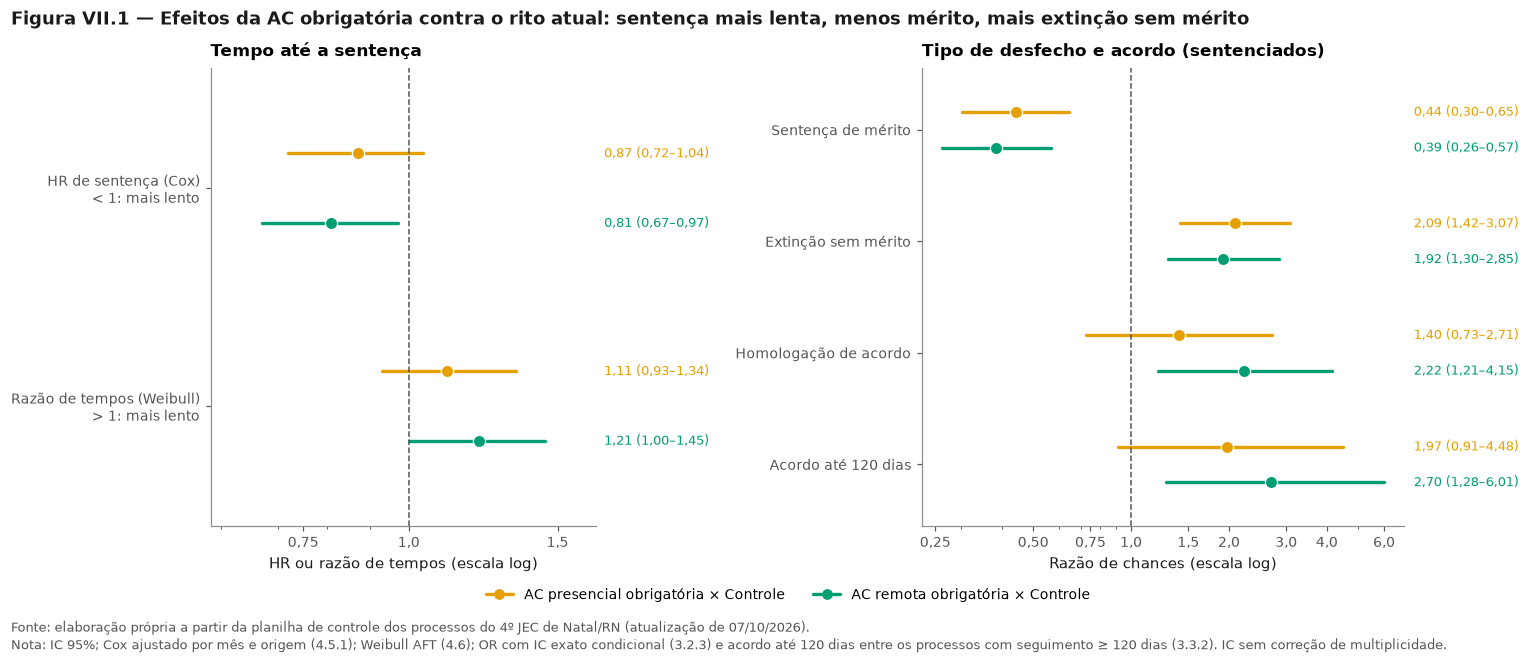

In [50]:
if sint_sob is not None and pares_tipo is not None and pares_120 is not None:
    efeitos_t = []
    for chave, nome in [('HR Cox (b) (IC 95%)', 'HR de sentença (Cox)\n< 1: mais lento'),
                        ('Razão de tempos Weibull (IC 95%)', 'Razão de tempos (Weibull)\n> 1: mais lento')]:
        for g, col in zip(['Presencial', 'Remota'], col_s[1:]):
            est, lo, hi = s7_num(sint_sob.loc[chave, col])[:3]
            efeitos_t.append((nome, g, est, lo, hi))
    efeitos_o = []
    for tipo, nome in [('Sentença de mérito', 'Sentença de mérito'), ('Extinção sem mérito', 'Extinção sem mérito'),
                       ('Homologação de acordo', 'Homologação de acordo')]:
        for g in ['Presencial', 'Remota']:
            l = s7_par(tipo, f'{g} × Controle')
            efeitos_o.append((nome, g, l['OR'], l['OR IC inf'], l['OR IC sup']))
    sub120 = pares_120[pares_120['Horizonte (dias)'] == 120].set_index('Comparação')
    for g in ['Presencial', 'Remota']:
        lo, hi = s7_num(sub120.loc[f'{g} × Controle', 'OR IC'])
        efeitos_o.append(('Acordo até 120 dias', g, sub120.loc[f'{g} × Controle', 'OR'], lo, hi))

    fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.25], 'wspace': 0.75})
    for ax, efeitos, titulo, xlab in [(axs[0], efeitos_t, 'Tempo até a sentença', 'HR ou razão de tempos (escala log)'),
                                      (axs[1], efeitos_o, 'Tipo de desfecho e acordo (sentenciados)', 'Razão de chances (escala log)')]:
        nomes = list(dict.fromkeys(e[0] for e in efeitos))
        ypos = {}
        for i, nome in enumerate(nomes):
            for j, g in enumerate(['Presencial', 'Remota']):
                ypos[(nome, g)] = i * 1.0 + (j - 0.5) * 0.32
        for nome, g, est, lo, hi in efeitos:
            y = ypos[(nome, g)]
            ax.plot([lo, hi], [y, y], color=CORES_GRUPO[g], lw=2.2)
            ax.plot(est, y, 'o', color=CORES_GRUPO[g], ms=8, mec='white', mew=0.8)
            ax.text(1.02, y, f'{fmt_br(est, 2)} ({fmt_br(lo, 2)}–{fmt_br(hi, 2)})', transform=ax.get_yaxis_transform(),
                    va='center', ha='left', fontsize=8.5, color=CORES_GRUPO[g])
        ax.axvline(1, color=TINTA_2, lw=1, ls='--')
        ax.set_xscale('log')
        ax.set_yticks(range(len(nomes)), nomes)
        ax.set_xlabel(xlab)
        ax.set_title(titulo)
        lo_all = min(e[3] for e in efeitos); hi_all = max(e[4] for e in efeitos)
        ax.set_xlim(lo_all / 1.15, hi_all * 1.15)
        ax.set_ylim(len(nomes) - 0.45, -0.55)
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: fmt_br(v, 2 if v < 1 else 1)))
        ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
        ticks = [t for t in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6] if lo_all / 1.15 <= t <= hi_all * 1.15]
        ax.set_xticks(ticks)
        ax.grid(axis='y', visible=False)
    fig.legend(handles=[mpl.lines.Line2D([], [], color=CORES_GRUPO[g], marker='o', lw=2.2, label=f'{ROTULO_GRUPO[g]} × Controle')
                        for g in ['Presencial', 'Remota']], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    figura(fig, 'sin_forest', 'Efeitos da AC obrigatória contra o rito atual: sentença mais lenta, menos mérito, mais extinção sem mérito',
           secao='7.2', nota='IC 95%; Cox ajustado por mês e origem (4.5.1); Weibull AFT (4.6); OR com IC exato condicional '
                             '(3.2.3) e acordo até 120 dias entre os processos com seguimento ≥ 120 dias (3.3.2). IC sem correção de multiplicidade.')

**Leitura do gráfico.** No painel do tempo, os dois braços com AC ficam do lado "mais lento" da linha de nulidade nos dois modelos; só o intervalo da Remota a exclui (HR 0,81; razão de tempos 1,21, com limite inferior em 1,00). No painel dos desfechos, os efeitos mais fortes e consistentes são os da **troca de tipo de sentença**: as razões de chances de mérito (0,44 e 0,39) e de extinção sem mérito (2,09 e 1,92) excluem 1 com folga nos dois braços, e as duas modalidades praticamente se sobrepõem. Os intervalos do acordo (homologação e acordo até 120 dias) são largos e só excluem 1 para a Remota, o que reflete o pequeno número de acordos (81 homologações no total) e reforça a leitura de que o efeito sobre o acordo é incerto. A semelhança entre Presencial e Remota em todos os desfechos sugere que o que importa é a **obrigatoriedade** da audiência, e não a sua modalidade, com a ressalva de que a modalidade está confundida com a conciliadora.

## 7.3 Resposta à pergunta de pesquisa

**A audiência de conciliação obrigatória, presencial ou remota, reduz o tempo de tramitação no 4º JEC de Natal em relação ao rito atual? Aumenta os acordos?**

**Não, nas duas perguntas.** Com os dados até 07/10/2026 e uma análise que respeita a censura, a AC obrigatória **aumentou** o tempo até a sentença em cerca de duas semanas na mediana (81 dias no rito atual contra 95 e 96 dias nos braços com AC), com evidência mais forte para a modalidade remota (HR ajustado 0,81; IC 0,67–0,97; ΔRMST de 10,7 dias em 180). A hipótese H1 do projeto ("a audiência obrigatória reduz o tempo médio de tramitação") é, portanto, **contrariada** pelos dados, e não apenas não confirmada. A conclusão do resumo expandido, de que não haveria "discrepância significativa" entre os ritos, decorre de médias que ignoram a censura e não resiste à análise correta (6.10).

Quanto ao acordo (H2), a AC obrigatória **não aumentou o acordo na audiência**, que ficou em torno de 5% das audiências realizadas em ambas as modalidades, e o excesso de acordos da Remota em relação ao Controle é **sugestivo, mas não robusto** à correção de multiplicidade e ocorre sobretudo fora da audiência. Quanto à modalidade (H3), presencial e remota **não diferem** em tempo nem em acordo, mas a comparação está confundida com a conciliadora. As hipóteses H4 (híbrida) e H5 (CEJUSC × vara) **não são testáveis** neste desenho (6.3, 6.7).

O achado juridicamente mais relevante é o **mecanismo**: a AC obrigatória funcionou menos como espaço de autocomposição e mais como **ocasião de extinção sem mérito** (de 30% para cerca de 46% das sentenças), compatível com o art. 51, I, da Lei 9.099/1995, enquanto as sentenças de mérito chegaram mais tarde. Do ponto de vista da política judiciária, o resultado sugere que, nesta unidade e neste período, a obrigatoriedade da AC acrescentou uma etapa ao rito sem produzir o ganho de conciliação que a justificaria. Esse resultado vale **para o 4º JEC**; a sua extensão aos demais JECs depende da comparação observacional da Parte VIII e, para a validade externa propriamente dita, de replicação.

## 7.4 Limitações e recomendações para a replicação

### 7.4.1 Limitações deste estudo

- **Unidade única e escolhida por conveniência**: sem inferência estatística para os 14 JECs (6.9).
- **Conciliadora confundida com a modalidade**: Presencial × Remota não separa a modalidade da pessoa (6.7).
- **Juiz-pesquisador não cego e reatividade da equipe**: não verificáveis com a planilha.
- **Seguimento curto e escalonado** (65 a 279 dias; 24,5% sem desfecho): a cauda da distribuição não é estimável; por isso se usaram a mediana de Kaplan-Meier e o RMST até 180 dias.
- **Ausência de covariáveis do processo** e de datas intermediárias: impede verificar o equilíbrio, decompor o tempo e explicar o mecanismo (Parte V).
- **Motivo da extinção sem mérito não registrado**: a leitura pelo art. 51, I, é plausível, mas não demonstrada.
- **Data da sentença possivelmente de lançamento** (18,4% em fins de semana): sem efeito nas conclusões (4.9), mas a validar no DataJud.
- **Riscos não proporcionais**: o efeito do rito concentra-se entre 30 e 90 dias (4.5.2), de modo que um único HR resume mal o efeito; o RMST e as curvas são a leitura preferível.
- **Mecanismo do sorteio não documentado**: o equilíbrio final é improvável num sorteio simples (P ≈ 1%), o que indica restrição; a análise estratificada por mês mitiga, mas não substitui a documentação.

### 7.4.2 Recomendações

O quadro consolida as recomendações para uma replicação, cada uma ligada ao problema que resolve e ao tipo de validade que fortalece. O cálculo de poder que o segue mostra que o próprio experimento, com o efeito observado, tinha poder modesto.

In [51]:
quadro_rec = pd.DataFrame([
    ['Hipóteses e análise definidas depois dos dados', 'pré-registro do protocolo (desfecho primário, secundários, plano de análise ITT, regras de exclusão)',
     'registro público antes do 1º sorteio; relato CONSORT', 'interna; credibilidade'],
    ['Desfecho primário ambíguo; médias com censura', 'desfecho primário = tempo até a sentença, com censura; estimandos: mediana de KM, RMST(τ), HR',
     'τ e data de corte fixados no protocolo', 'interna; estatística'],
    ['Poder não calculado', 'cálculo de poder para o desfecho primário', 'eventos necessários pela fórmula de Schoenfeld (7.4.3)', 'estatística'],
    ['Sorteio sem documentação; equilíbrio improvável', 'lista de aleatorização em blocos permutados, estratificada por mês, gerada por terceiro',
     'semente registrada; ocultação (central externa ao juízo)', 'interna'],
    ['Reentradas re-sorteadas; prevenção sorteada', 'regras de elegibilidade e de reentrada', 'triagem de prevenção antes do sorteio; reentrada herda o grupo', 'interna'],
    ['Conciliadora confundida com a modalidade', 'rodízio das conciliadoras entre modalidades (ou várias por braço)',
     'escala de rodízio sorteada por semana', 'interna; constructo'],
    ['Juiz-pesquisador não cego', 'cegamento da extração e da análise', 'desfecho extraído do PJe/DataJud por terceiro; análise com grupos codificados', 'interna'],
    ['Sem covariáveis nem datas intermediárias', 'coleta das covariáveis basais e das datas de citação, AC, contestação e conclusão',
     'extração automática do PJe/DataJud pelo número CNJ', 'interna; precisão'],
    ['Motivo da extinção e comparecimento não registrados', 'registrar comparecimento de cada parte, formato real da AC e motivo da extinção',
     'campos fechados na planilha (lista de validação)', 'constructo; mecanismo'],
    ['Seguimento curto e escalonado', 'seguimento mínimo comum para todos', 'por exemplo, 180 dias após o último sorteio', 'estatística'],
    ['Mês como confundidor de calendário', 'estratificação por mês no sorteio e na análise', 'blocos por mês; Cox estratificado', 'interna'],
    ['Unidade única (N = 1)', 'ensaio multicêntrico por conglomerados ou escalonado (stepped-wedge) entre JECs',
     'adesão das unidades via TJRN/NUPEMEC; sorteio das unidades e do momento de entrada', 'externa'],
    ['Efeito do experimento sobre a unidade desconhecido', 'comparação com o período anterior e com os outros JECs',
     'diferenças em diferenças com o DataJud (Parte VIII)', 'interna (reatividade); externa'],
], columns=['Problema encontrado', 'Recomendação', 'Como implementar', 'Validade fortalecida'])
tabela(quadro_rec, 'sin_recomendacoes', 'Recomendações para a replicação do experimento', secao='7.4',
       fonte='Elaboração própria a partir das Partes I a VI.')

Problema encontrado,Recomendação,Como implementar,Validade fortalecida
Hipóteses e análise definidas depois dos dados,"pré-registro do protocolo (desfecho primário, secundários, plano de análise ITT, regras de exclusão)",registro público antes do 1º sorteio; relato CONSORT,interna; credibilidade
Desfecho primário ambíguo; médias com censura,"desfecho primário = tempo até a sentença, com censura; estimandos: mediana de KM, RMST(τ), HR",τ e data de corte fixados no protocolo,interna; estatística
Poder não calculado,cálculo de poder para o desfecho primário,eventos necessários pela fórmula de Schoenfeld (7.4.3),estatística
Sorteio sem documentação; equilíbrio improvável,"lista de aleatorização em blocos permutados, estratificada por mês, gerada por terceiro",semente registrada; ocultação (central externa ao juízo),interna
Reentradas re-sorteadas; prevenção sorteada,regras de elegibilidade e de reentrada,triagem de prevenção antes do sorteio; reentrada herda o grupo,interna
Conciliadora confundida com a modalidade,rodízio das conciliadoras entre modalidades (ou várias por braço),escala de rodízio sorteada por semana,interna; constructo
Juiz-pesquisador não cego,cegamento da extração e da análise,desfecho extraído do PJe/DataJud por terceiro; análise com grupos codificados,interna
Sem covariáveis nem datas intermediárias,"coleta das covariáveis basais e das datas de citação, AC, contestação e conclusão",extração automática do PJe/DataJud pelo número CNJ,interna; precisão
Motivo da extinção e comparecimento não registrados,"registrar comparecimento de cada parte, formato real da AC e motivo da extinção",campos fechados na planilha (lista de validação),constructo; mecanismo
Seguimento curto e escalonado,seguimento mínimo comum para todos,"por exemplo, 180 dias após o último sorteio",estatística


### 7.4.3 Cálculo de poder: quantos eventos seriam necessários?

Para comparar dois braços 1:1 com um modelo de riscos proporcionais, o número de **eventos** (sentenças) necessário para detectar uma razão de riscos HR, com nível α bilateral e poder 1 − β, é dado pela fórmula de Schoenfeld (1983): d = 4(z₁₋α/₂ + z₁₋β)² / (ln HR)². Inversamente, com d eventos, o poder para um HR verdadeiro é Φ(√(d/4)·|ln HR| − z₁₋α/₂). Para o acordo na AC, uma proporção baixa (cerca de 5%), o tamanho por grupo para detectar a diferença entre p₁ e p₂ usa a transformação arco-seno, h = 2·arcsen√p₂ − 2·arcsen√p₁, com n = 2[(z₁₋α/₂ + z₁₋β)/h]² processos com AC realizada por braço. Os cálculos usam α = 5% e poder de 80%; com a correção de Holm para duas comparações contra o Controle, o α efetivo da primeira comparação cai para 2,5%, o que aumenta as exigências em cerca de 20%.

Desfecho,Efeito a detectar,Necessário (α = 5%),"Necessário (α = 2,5%, Holm)",Disponível no estudo,Poder com o disponível
"Tempo até a sentença (Cox, 1:1)","HR = 0,90",2.828,3.425,478,"20,9%"
"Tempo até a sentença (Cox, 1:1)","HR = 0,85",1.189,1.439,478,"42,7%"
"Tempo até a sentença (Cox, 1:1)","HR = 0,80",631,764,478,"68,4%"
"Tempo até a sentença (Cox, 1:1)","HR = 0,75",379,459,478,"88,2%"
"Tempo até a sentença (Cox, 1:1)","HR observado Presencial = 0,87",1.619,1.960,492,"33,9%"
"Tempo até a sentença (Cox, 1:1)","HR observado Remota = 0,81",707,856,478,"63,4%"
Acordo na AC (proporções),"4,8% → 10,0%",391,474,174,"46,4%"
Acordo na AC (proporções),"4,8% → 13,3%",170,206,174,"80,8%"
Acordo na AC (proporções),"4,8% → 20,0%",67,81,174,"99,5%"


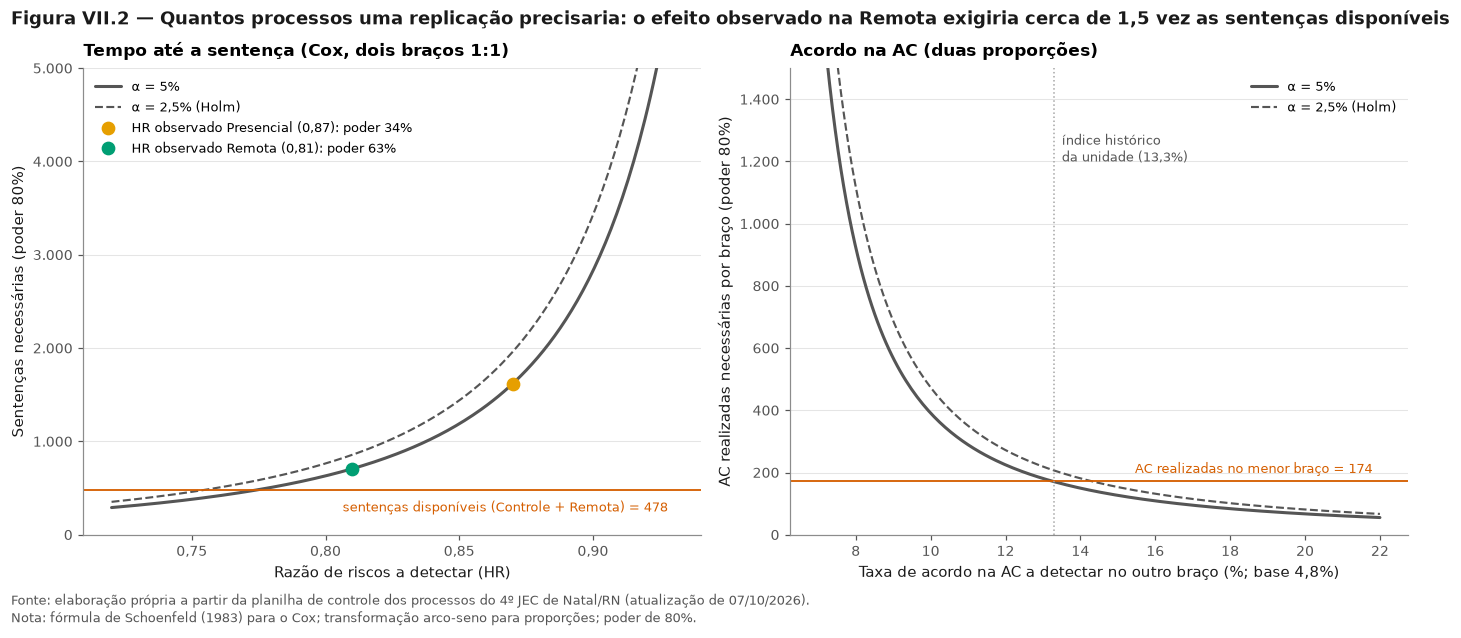

In [52]:
za, zb = norm.ppf(0.975), norm.ppf(0.80)
eventos_nec = lambda hr, a=0.05, pw=0.80: 4 * (norm.ppf(1 - a / 2) + norm.ppf(pw)) ** 2 / np.log(hr) ** 2
poder_cox = lambda d, hr, a=0.05: norm.cdf(np.sqrt(d / 4) * abs(np.log(hr)) - norm.ppf(1 - a / 2))
h_arc = lambda p1, p2: abs(2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1)))
n_prop = lambda p1, p2, a=0.05, pw=0.80: 2 * ((norm.ppf(1 - a / 2) + norm.ppf(pw)) / h_arc(p1, p2)) ** 2
poder_prop = lambda n, p1, p2, a=0.05: norm.cdf(np.sqrt(n / 2) * h_arc(p1, p2) - norm.ppf(1 - a / 2))

ev = dados.groupby('grupo', observed=True)['evento'].apply(lambda s: int(s.astype(int).sum())).reindex(ORDEM_GRUPO)
d_pc, d_rc = int(ev['Controle'] + ev['Presencial']), int(ev['Controle'] + ev['Remota'])
acr = dados[dados['ac_realizada'].fillna(False).astype(bool)]
n_ac = acr.groupby('grupo', observed=True).size().reindex(['Presencial', 'Remota'])
k_ac = acr.groupby('grupo', observed=True)['acordo_ac'].apply(lambda s: int(s.fillna(False).astype(bool).sum())).reindex(['Presencial', 'Remota'])
p_base = k_ac.sum() / n_ac.sum()
hr_obs = {}
if sint_sob is not None:
    for g, col in zip(['Presencial', 'Remota'], col_s[1:]):
        hr_obs[g] = s7_num(sint_sob.loc['HR Cox (b) (IC 95%)', col])[0]

linhas_p = []
for hr in [0.90, 0.85, 0.80, 0.75]:
    linhas_p.append(['Tempo até a sentença (Cox, 1:1)', f'HR = {fmt_br(hr, 2)}', eventos_nec(hr), eventos_nec(hr, a=0.025),
                     d_rc, poder_cox(d_rc, hr)])
for g, d in [('Presencial', d_pc), ('Remota', d_rc)]:
    if g in hr_obs:
        linhas_p.append(['Tempo até a sentença (Cox, 1:1)', f'HR observado {g} = {fmt_br(hr_obs[g], 2)}', eventos_nec(hr_obs[g]),
                         eventos_nec(hr_obs[g], a=0.025), d, poder_cox(d, hr_obs[g])])
n_disp = int(n_ac.min())
for p2 in [0.10, 0.133, 0.20]:
    linhas_p.append(['Acordo na AC (proporções)', f'{pct_br(p_base, 1)} → {pct_br(p2, 1)}', n_prop(p_base, p2), n_prop(p_base, p2, a=0.025),
                     n_disp, poder_prop(n_disp, p_base, p2)])
poder_df = pd.DataFrame(linhas_p, columns=['Desfecho', 'Efeito a detectar', 'Necessário (α = 5%)', 'Necessário (α = 2,5%, Holm)',
                                           'Disponível no estudo', 'Poder com o disponível'])
tabela(poder_df, 'sin_poder', 'Poder do experimento: cerca de 60% para o efeito observado sobre o tempo; no acordo na AC, só diferenças grandes eram detectáveis',
       secao='7.4.3', formatos={'Necessário (α = 5%)': 0, 'Necessário (α = 2,5%, Holm)': 0, 'Disponível no estudo': 'int',
                                 'Poder com o disponível': 'pct'},
       nota=f'tempo: número de sentenças nos dois braços comparados (Controle + Remota = {d_rc}; Controle + Presencial = {d_pc}); '
            f'acordo: AC realizadas por braço (menor braço = {n_disp}); taxa-base de acordo na AC = {pct_br(p_base, 1)} '
            f'({int(k_ac.sum())}/{int(n_ac.sum())}); 13,3% = índice histórico da unidade. Poder com α = 5%.',
       fonte='Elaboração própria; fórmula de Schoenfeld (1983) e aproximação arco-seno para proporções.')

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
hrs = np.linspace(0.72, 0.93, 200)
ax = axs[0]
ax.plot(hrs, eventos_nec(hrs), color=TINTA_2, lw=2, label='α = 5%')
ax.plot(hrs, eventos_nec(hrs, a=0.025), color=TINTA_2, lw=1.4, ls='--', label='α = 2,5% (Holm)')
ax.axhline(d_rc, color=DESTAQUE, lw=1.2)
ax.annotate(f'sentenças disponíveis (Controle + Remota) = {d_rc}', (0.928, d_rc), xytext=(0, -14), textcoords='offset points',
            fontsize=8.5, color=DESTAQUE, ha='right')
for g in hr_obs:
    ax.plot(hr_obs[g], eventos_nec(hr_obs[g]), 'o', color=CORES_GRUPO[g], ms=8,
            label=f'HR observado {g} ({fmt_br(hr_obs[g], 2)}): poder {pct_br(poder_cox(d_rc if g == "Remota" else d_pc, hr_obs[g]), 0)}')
ax.set_ylim(0, 5000)
ax.set_xlabel('Razão de riscos a detectar (HR)'); ax.set_ylabel('Sentenças necessárias (poder 80%)')
ax.set_title('Tempo até a sentença (Cox, dois braços 1:1)')
ax.legend(loc='upper left', fontsize=8.5)
ax = axs[1]
p2s = np.linspace(0.07, 0.22, 200)
ax.plot(p2s * 100, n_prop(p_base, p2s), color=TINTA_2, lw=2, label='α = 5%')
ax.plot(p2s * 100, n_prop(p_base, p2s, a=0.025), color=TINTA_2, lw=1.4, ls='--', label='α = 2,5% (Holm)')
ax.axhline(n_disp, color=DESTAQUE, lw=1.2)
ax.annotate(f'AC realizadas no menor braço = {n_disp}', (21.8, n_disp), xytext=(0, 5), textcoords='offset points',
            fontsize=8.5, color=DESTAQUE, ha='right')
ax.axvline(13.3, color=CINZA, lw=1, ls=':')
ax.annotate('índice histórico\nda unidade (13,3%)', (13.3, 1200), xytext=(5, 0), textcoords='offset points', fontsize=8.5, color=TINTA_2)
ax.set_ylim(0, 1500)
ax.set_xlabel(f'Taxa de acordo na AC a detectar no outro braço (%; base {pct_br(p_base, 1)})')
ax.set_ylabel('AC realizadas necessárias por braço (poder 80%)')
ax.set_title('Acordo na AC (duas proporções)')
ax.legend(loc='upper right', fontsize=8.5)
figura(fig, 'sin_poder', 'Quantos processos uma replicação precisaria: o efeito observado na Remota exigiria cerca de 1,5 vez as sentenças disponíveis',
       secao='7.4.3', nota='fórmula de Schoenfeld (1983) para o Cox; transformação arco-seno para proporções; poder de 80%.')

**Leitura do cálculo de poder.** Com 478 sentenças nos braços Controle e Remota, o experimento tinha 63% de poder para detectar o HR efetivamente observado (0,81) e 34% para o da Presencial (0,87, com 492 sentenças); detectar o HR da Remota com 80% de poder exigiria 707 sentenças (856 com a correção de Holm), cerca de 1,5 vez as disponíveis, e o da Presencial, 1.619. Isso tem duas consequências. Primeiro, o resultado significativo da Remota não é artefato de excesso de poder: é um efeito de tamanho moderado, detectado com poder apenas razoável. Segundo, a ausência de significância da Presencial **não** autoriza concluir que ela não atrasa a sentença: o experimento simplesmente não tinha poder para efeitos desse tamanho.

No acordo na AC, com 174 audiências realizadas no menor braço e taxa-base de 4,8%, só diferenças grandes eram detectáveis: o poder seria de 46% para chegar a 10% de acordos e de 81% para atingir o índice histórico da unidade (13,3%). Uma replicação que pretenda comparar técnicas ou modalidades quanto ao acordo na audiência precisa, portanto, de algumas centenas de audiências por braço, e deve definir no protocolo qual diferença é relevante para a política judiciária.

## 7.5 Considerações finais

O experimento do 4º JEC de Natal é uma contribuição valiosa justamente porque é um experimento: o sorteio permitiu responder a uma pergunta causal que estudos observacionais sobre a conciliação raramente conseguem responder. A resposta, porém, é a oposta da que os autores anunciaram: a obrigatoriedade da AC inaugural **não acelerou** os processos e **não aumentou** a conciliação na audiência; alongou o tempo até a sentença e transformou parte das sentenças de mérito em extinções sem mérito. A divergência não vem dos dados, que são fidedignos, mas da **análise**: médias calculadas sobre processos ainda em curso, sem tratamento da censura, sem teste e sem intervalo. O exercício mostra, assim, o valor da ciência de dados aplicada ao Direito: os mesmos registros, tratados com os métodos adequados (curadoria explícita, análise de sobrevivência, riscos competitivos e controle de multiplicidade), mudam a conclusão sobre uma política judiciária.

A replicação deve preservar o que o experimento fez bem (sorteio individual, controle contemporâneo, registro diário) e corrigir o que limitou a sua validade: pré-registro, aleatorização documentada e estratificada, rodízio das conciliadoras, cegamento da extração, coleta das covariáveis e do motivo da extinção, seguimento comum e, sobretudo, várias unidades judiciais.

## 7.6 Referências

AALEN, O. O.; JOHANSEN, S. An empirical transition matrix for non-homogeneous Markov chains based on censored observations. **Scandinavian Journal of Statistics**, v. 5, n. 3, p. 141-150, 1978.

ALENCAR, P. G. M. de. **Impacto da audiência de conciliação no tempo de tramitação dos processos do 4º JEC de Natal/RN**: efeitos do art. 334 do CPC e das mudanças impostas pela pandemia da Covid-19. Projeto de pesquisa (Mestrado Profissional em Direito e Políticas Públicas) — Universidade Federal de Goiás, Goiânia, 2026.

ALENCAR, P. G. M. de; NEVES, C. B. das. Eficácia da conciliação obrigatória na tramitação processual: um experimento no 4º Juizado Especial Cível de Natal (2026). In: ENCONTRO DE ADMINISTRAÇÃO DA JUSTIÇA (ENAJUS), Goiânia, 2026. **Resumo expandido**.

ARTES, R.; BARROSO, L. P. **Métodos multivariados de análise estatística**. São Paulo: Blucher, 2023.

AUSTIN, P. C.; LEE, D. S.; FINE, J. P. Introduction to the analysis of survival data in the presence of competing risks. **Circulation**, v. 133, n. 6, p. 601-609, 2016.

BARBETTA, P. A.; REIS, M. M.; BORNIA, A. C. **Estatística para cursos de engenharia e informática**. São Paulo: Atlas, 2020.

BECKER, J. L. **Estatística básica**: transformando dados em informação. Porto Alegre: Bookman, 2015.

BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. **Journal of the Royal Statistical Society: Series B**, v. 57, n. 1, p. 289-300, 1995.

BRASIL. Conselho Nacional de Justiça. **API Pública do DataJud**: documentação. Brasília: CNJ, [2023]. Disponível em: https://datajud-wiki.cnj.jus.br/api-publica/. Acesso em: 12 nov. 2026.

BRASIL. Conselho Nacional de Justiça. **Justiça em Números 2026**: ano-base 2025. Brasília: CNJ, 2026. Disponível em: https://www.cnj.jus.br/pesquisas-judiciarias/justica-em-numeros/. Acesso em: 12 nov. 2026.

BRASIL. Conselho Nacional de Justiça. Resolução nº 125, de 29 de novembro de 2010. Dispõe sobre a Política Judiciária Nacional de tratamento adequado dos conflitos de interesses no âmbito do Poder Judiciário. Brasília: CNJ, 2010.

BRASIL. Lei nº 9.099, de 26 de setembro de 1995. Dispõe sobre os Juizados Especiais Cíveis e Criminais. **Diário Oficial da União**, Brasília, 27 set. 1995.

BRASIL. Lei nº 13.105, de 16 de março de 2015. Código de Processo Civil. **Diário Oficial da União**, Brasília, 17 mar. 2015.

BRASIL. Lei nº 13.994, de 24 de abril de 2020. Altera a Lei nº 9.099, de 26 de setembro de 1995, para possibilitar a conciliação não presencial no âmbito dos Juizados Especiais Cíveis. **Diário Oficial da União**, Brasília, 27 abr. 2020.

BROOKMEYER, R.; CROWLEY, J. A confidence interval for the median survival time. **Biometrics**, v. 38, n. 1, p. 29-41, 1982.

COLOSIMO, E. A.; GIOLO, S. R. **Análise de sobrevivência aplicada**. São Paulo: Blucher, 2006. (Projeto Fisher.)

COX, D. R. Regression models and life-tables. **Journal of the Royal Statistical Society: Series B**, v. 34, n. 2, p. 187-220, 1972.

DAVIDSON-PILON, C. lifelines: survival analysis in Python. **Journal of Open Source Software**, v. 4, n. 40, p. 1317, 2019.

EFRON, B. The efficiency of Cox's likelihood function for censored data. **Journal of the American Statistical Association**, v. 72, n. 359, p. 557-565, 1977.

FINE, J. P.; GRAY, R. J. A proportional hazards model for the subdistribution of a competing risk. **Journal of the American Statistical Association**, v. 94, n. 446, p. 496-509, 1999.

FLEMING, T. R.; HARRINGTON, D. P. **Counting processes and survival analysis**. New York: Wiley, 1991.

GESKUS, R. B. Cause-specific cumulative incidence estimation and the Fine and Gray model under both left truncation and right censoring. **Biometrics**, v. 67, n. 1, p. 39-49, 2011.

GRAMBSCH, P. M.; THERNEAU, T. M. Proportional hazards tests and diagnostics based on weighted residuals. **Biometrika**, v. 81, n. 3, p. 515-526, 1994.

GRAY, R. J. A class of K-sample tests for comparing the cumulative incidence of a competing risk. **The Annals of Statistics**, v. 16, n. 3, p. 1141-1154, 1988.

HOLM, S. A simple sequentially rejective multiple test procedure. **Scandinavian Journal of Statistics**, v. 6, n. 2, p. 65-70, 1979.

HOSMER, D. W.; LEMESHOW, S.; STURDIVANT, R. X. **Applied logistic regression**. 3. ed. Hoboken: Wiley, 2013.

INSTITUTO DE PESQUISA ECONÔMICA APLICADA (IPEA). **Diagnóstico sobre os Juizados Especiais Cíveis**: relatório de pesquisa. Brasília: Ipea; CNJ, 2013.

KAPLAN, E. L.; MEIER, P. Nonparametric estimation from incomplete observations. **Journal of the American Statistical Association**, v. 53, n. 282, p. 457-481, 1958.

MOORE, D. S.; NOTZ, W. I.; FLIGNER, M. A. **A estatística básica e sua prática**. Rio de Janeiro: LTC, 2023.

MORETTIN, P. A.; SINGER, J. M. **Estatística e ciência de dados**. Versão preliminar. São Paulo: IME-USP, abr. 2021.

PUTTER, H.; FIOCCO, M.; GESKUS, R. B. Tutorial in biostatistics: competing risks and multi-state models. **Statistics in Medicine**, v. 26, n. 11, p. 2389-2430, 2007.

ROYSTON, P.; PARMAR, M. K. B. Restricted mean survival time: an alternative to the hazard ratio for the design and analysis of randomized trials with a time-to-event outcome. **BMC Medical Research Methodology**, v. 13, art. 152, 2013.

SCHOENFELD, D. A. Sample-size formula for the proportional-hazards regression model. **Biometrics**, v. 39, n. 2, p. 499-503, 1983.

SCHULZ, K. F.; ALTMAN, D. G.; MOHER, D. CONSORT 2010 Statement: updated guidelines for reporting parallel group randomised trials. **BMJ**, v. 340, c332, 2010.

SEABOLD, S.; PERKTOLD, J. statsmodels: econometric and statistical modeling with Python. In: PYTHON IN SCIENCE CONFERENCE, 9., 2010, Austin. **Proceedings** [...]. Austin: SciPy, 2010. p. 92-96.

SIEGEL, S.; CASTELLAN JR., N. J. **Estatística não-paramétrica para ciências do comportamento**. 2. ed. Porto Alegre: Artmed, 2006.

THERNEAU, T. M.; GRAMBSCH, P. M. **Modeling survival data**: extending the Cox model. New York: Springer, 2000.